# Tecnológico de Monterrey
**Maestría en Inteligencia Artificial Aplicada**

---

# Proyecto Integrador
## Avance 4. Modelos alternativos

### Reconstrucción de tiempos de desplazamiento mediante técnicas de aprendizaje automático

**Proyecto:**  
*Planeación inteligente de rutas ante interrupciones mediante técnicas de optimización e inteligencia artificial*

**Equipo 42 - Route Intelligence**

**Integrantes:**
- Luis Ángel Herrera Flores
- Francisco Natanael Ortiz Martínez
- Edgar Iván Rosas Gómez

**Asesor académico:**  
Dr. Gerardo Jesús Camacho González

**Fecha:** 25 de octubre de 2026

---

### Descripción del entregable

Esta libreta documenta la construcción, comparación y ajuste de seis modelos individuales de aprendizaje automático para estimar los tiempos de recorrido de una red vial experimental a partir de un conjunto reducido de consultas origen-destino (OD) contemporáneas simuladas.

Se presenta el diseño experimental, la selección de 32 consultas guía, la reconstrucción de tiempos de las aristas y la evaluación de los modelos mediante matrices OD. Finalmente, se selecciona el modelo individual con mejor desempeño y se evalúa sobre un periodo temporal reservado.

**Entorno experimental:** PEMS-BAY, enero-junio de 2017.  
**Modelo seleccionado:** regresión Ridge multisalida, con $K=32$ y $\alpha=1000$.

---

*Avance 4 - Modelos alternativos | Equipo 42 - Route Intelligence*

## Contenido y alcance

La libreta inicia con un análisis exploratorio que fundamenta la selección de consultas guía y el escenario K=32. Después presenta la comparación de seis modelos, el ajuste de los dos candidatos mejor clasificados y la justificación de la elección final. Como evaluación complementaria, reconstruye matrices de tiempos OD entre conjuntos variables de nodos mediante caminos mínimos y evalúa el modelo seleccionado sobre junio de 2017, reservado como prueba final.

**Alcance:** las consultas guía son **observaciones simuladas** a partir de tiempos de viaje calculados sobre el grafo experimental, cuyas aristas utilizan velocidades de PEMS-BAY. No son consultas reales a una API externa. La evaluación no mide el desempeño de un solucionador del problema de ruteo de vehículos con ventanas de tiempo (VRPTW), la latencia de las consultas externas ni la generalización a otras redes.

**Guía de lectura:** **Bloque I (secciones 1-7):** preparación y análisis exploratorio. **Bloque II (secciones 8-13):** comparación de seis modelos, ajuste y selección, que responden a la rúbrica del Avance 4. **Bloque III (secciones 14-19):** evaluación final, visualizaciones complementarias y conclusiones.

**Requisitos de reproducción:** la primera celda de código requiere `nodes.csv`, `edges.csv`, `edge_travel_times.parquet` y `manifest.json`, correspondientes a `routing_dataset_v1`. Puede localizarlos en `data/routing_dataset_v1/`, en la carpeta de Drive configurada en el código, o en el directorio indicado por la variable de entorno `ROUTE_INTELLIGENCE_DATASET_DIR`. Para la ejecución completa también se requieren las bibliotecas de análisis utilizadas en las celdas, incluido un motor de lectura Parquet como `pyarrow`.


## Bloque I. Preparación y fundamentación experimental

Secciones 1-7. Estos análisis justifican el escenario K=32; no constituyen modelos adicionales de la comparación principal.


### 1. Recuperación de la red experimental PEMS-BAY

Se cargan y verifican la topología, los tiempos por arista y el manifiesto de datos utilizados en todas las secciones posteriores.


In [1]:
# ------------------------------------------------------------
# 1. Recuperación de la red experimental PEMS-BAY
# ------------------------------------------------------------
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd

# Colab: montar Drive sólo si necesitamos buscar archivos allí.
# Fuera de Colab no se requiere importar google.colab.
required = {'nodes.csv', 'edges.csv', 'edge_travel_times.parquet', 'manifest.json'}

def choose_dataset_dir():
    candidates = []
    if os.getenv('ROUTE_INTELLIGENCE_DATASET_DIR'):
        candidates.append(Path(os.environ['ROUTE_INTELLIGENCE_DATASET_DIR']))
    candidates += [
        Path.cwd() / 'data' / 'routing_dataset_v1',
        Path.cwd() / 'routing_dataset_v1',
        Path('/content/drive/MyDrive/Route Intelligence/routing_dataset_v1'),
        Path('/mnt/data'),
    ]
    for path in candidates:
        if all((path / name).is_file() for name in required):
            return path
    try:
        from google.colab import drive
    except ImportError:
        pass
    else:
        drive.mount('/content/drive')
        drive_dir = Path('/content/drive/MyDrive/Route Intelligence/routing_dataset_v1')
        if all((drive_dir / name).is_file() for name in required):
            return drive_dir
    raise FileNotFoundError(
        'Faltan insumos: coloque los cuatro archivos en routing_dataset_v1. '
        'Alternativamente defina ROUTE_INTELLIGENCE_DATASET_DIR.'
    )

DATASET_DIR = choose_dataset_dir()
PROJECT_DIR = DATASET_DIR.parent if DATASET_DIR.name == 'routing_dataset_v1' else DATASET_DIR

nodes = pd.read_csv(DATASET_DIR / 'nodes.csv', dtype={'node_id': str})
edges = pd.read_csv(DATASET_DIR / 'edges.csv', dtype={
    'edge_id': str, 'from': str, 'to': str,
    'sensor_1': str, 'sensor_2': str,
})

try:
    edge_times = pd.read_parquet(DATASET_DIR / 'edge_travel_times.parquet')
except ImportError as exc:
    raise ImportError('Se requiere pyarrow o fastparquet para leer Parquet.') from exc

edge_times.index = pd.to_datetime(edge_times.index)
with open(DATASET_DIR / 'manifest.json', encoding='utf-8') as f:
    manifest = json.load(f)

assert len(nodes) == manifest['network']['nodes'] == 322
assert len(edges) == manifest['network']['directed_edges'] == 345
assert edge_times.shape == (52116, 345)
assert edges['edge_id'].tolist() == edge_times.columns.tolist()
assert edge_times.index.is_monotonic_increasing and edge_times.index.is_unique
assert np.isfinite(edge_times.to_numpy()).all()
assert (edge_times.to_numpy() > 0).all()

train_times = edge_times.loc['2017-01-01':'2017-03-31 23:59:59'].copy()
val_times = edge_times.loc['2017-04-01':'2017-04-30 23:59:59'].copy()
assert train_times.shape == (25908, 345)
assert val_times.shape == (8640, 345)
assert train_times.index.max() < val_times.index.min()

print('Dataset base recuperado:', DATASET_DIR)
print('Nodos:', len(nodes), '| Aristas:', len(edges))
print('Serie temporal:', edge_times.shape)
print('Periodo:', edge_times.index.min(), '→', edge_times.index.max())
print('Entrenamiento inicial:', train_times.shape)
print('Validación preliminar:', val_times.shape)
print('Tipos de arista:')
print(edges['edge_type'].value_counts())
print('Tiempos mínimo y máximo (min):',
      round(float(edge_times.to_numpy().min()), 5),
      round(float(edge_times.to_numpy().max()), 5))


Mounted at /content/drive
Dataset base recuperado: /content/drive/MyDrive/Route Intelligence/routing_dataset_v1
Nodos: 322 | Aristas: 345
Serie temporal: (52116, 345)
Periodo: 2017-01-01 00:00:00 → 2017-06-30 23:55:00
Entrenamiento inicial: (25908, 345)
Validación preliminar: (8640, 345)
Tipos de arista:
edge_type
corridor                 273
sensor_to_interchange     36
interchange_to_sensor     36
Name: count, dtype: int64
Tiempos mínimo y máximo (min): 0.00811 31.56923



### 2. Caracterización de la variabilidad histórica

Se construye una referencia temporal K=0 para cada una de las 345 aristas, utilizando la mediana histórica condicionada por día de la semana e intervalo de cinco minutos.

La referencia se estima exclusivamente con enero-marzo de 2017. Abril se utiliza para examinar preliminarmente el comportamiento de las desviaciones fuera del periodo de ajuste.

Se analizan errores absolutos en segundos y desviaciones relativas respecto de la referencia histórica.

Para examinar posibles diferencias en la variabilidad de los tiempos de recorrido, las aristas se clasifican en tres grupos: conexiones entre sensores de un mismo corredor (273), conexiones de sensores hacia macronodos de intercambio (36) y conexiones de macronodos hacia sensores (36). Esta distinción permite analizar por separado los resultados de los tramos ordinarios y los enlaces introducidos para representar de manera simplificada las interconexiones entre autopistas.

Este análisis es exploratorio. Las aristas con mayor variabilidad residual no se interpretarán automáticamente como las más informativas para reconstruir el estado completo de la red.


In [2]:

# ------------------------------------------------------------
# 2. Variabilidad residual de las 345 aristas
# ------------------------------------------------------------

# Claves de contexto temporal
def temporal_keys(index):
    return pd.MultiIndex.from_arrays(
        [
            index.dayofweek,
            index.hour * 12 + index.minute // 5
        ],
        names=['weekday', 'slot5']
    )


# ------------------------------------------------------------
# Baseline ajustado con enero-marzo
# ------------------------------------------------------------

historical_edge_reference = train_times.groupby(
    temporal_keys(train_times.index)
).median()

assert historical_edge_reference.shape == (2016, 345)


def historical_prediction(reference, timestamps):
    keys = temporal_keys(timestamps)

    predicted = pd.DataFrame(
        reference.reindex(keys).to_numpy(),
        index=timestamps,
        columns=reference.columns
    )

    assert np.isfinite(predicted.to_numpy()).all()
    assert (predicted.to_numpy() > 0).all()

    return predicted


base_train = historical_prediction(
    historical_edge_reference,
    train_times.index
)

base_april = historical_prediction(
    historical_edge_reference,
    val_times.index
)

# ------------------------------------------------------------
# Desviaciones absolutas y relativas
# ------------------------------------------------------------

actual_train = train_times.to_numpy()
actual_april = val_times.to_numpy()

expected_train = base_train.to_numpy()
expected_april = base_april.to_numpy()

relative_train = (
    actual_train - expected_train
) / expected_train

relative_april = (
    actual_april - expected_april
) / expected_april

absolute_error_april = np.abs(
    actual_april - expected_april
)

assert np.isfinite(relative_train).all()
assert np.isfinite(relative_april).all()

# ------------------------------------------------------------
# Estadísticas por arista
# ------------------------------------------------------------

edge_stats = pd.DataFrame({
    'edge_id': edge_times.columns,

    'mediana_desv_rel_ent_pct':
        100 * np.median(
            np.abs(relative_train),
            axis=0
        ),

    'mediana_desv_rel_abril_pct':
        100 * np.median(
            np.abs(relative_april),
            axis=0
        ),

    'p95_desv_rel_abril_pct':
        100 * np.percentile(
            np.abs(relative_april),
            95,
            axis=0
        ),

    'mae_abril_s':
        60 * absolute_error_april.mean(axis=0)
})

# Incorporar atributos de la red
edge_stats = edge_stats.merge(
    edges[
        ['edge_id', 'edge_type', 'corridor']
    ],
    on='edge_id',
    how='left',
    validate='one_to_one'
)

assert len(edge_stats) == 345
assert edge_stats['edge_type'].notna().all()

# ------------------------------------------------------------
# Resumen según tipo de arista
# ------------------------------------------------------------

summary_by_type = (
    edge_stats
    .groupby('edge_type')
    .agg(
        aristas=('edge_id', 'count'),
        mediana_desv_rel_abril_pct=(
            'mediana_desv_rel_abril_pct', 'median'
        ),
        mediana_mae_abril_s=(
            'mae_abril_s', 'median'
        )
    )
    .reset_index()
)

print('Caracterización residual completada.')
print()

print('Grupos históricos:',
      len(historical_edge_reference))

print('Aristas analizadas:', len(edge_stats))

print()
print('Resumen por tipo de arista:')

display(summary_by_type.round(3))

# ------------------------------------------------------------
# Aristas con mayor variabilidad residual histórica
# ------------------------------------------------------------

print()
print(
    '12 aristas con mayor desviación relativa '
    'en entrenamiento:'
)

most_variable_edges = (
    edge_stats
    .sort_values(
        'mediana_desv_rel_ent_pct',
        ascending=False
    )
    .head(12)
)

display(
    most_variable_edges[
        [
            'edge_id',
            'corridor',
            'edge_type',
            'mediana_desv_rel_ent_pct',
            'mediana_desv_rel_abril_pct',
            'mae_abril_s'
        ]
    ].round(3)
)

# ------------------------------------------------------------
# Resumen global de abril
# ------------------------------------------------------------

print()
print(
    'MAE global K=0, abril:',
    f'{60 * absolute_error_april.mean():.3f} s'
)

print(
    'Mediana global de desviación relativa absoluta:',
    f'{100 * np.median(np.abs(relative_april)):.3f}%'
)


Caracterización residual completada.

Grupos históricos: 2016
Aristas analizadas: 345

Resumen por tipo de arista:


,edge_type,aristas,mediana_desv_rel_abril_pct,mediana_mae_abril_s
0,corridor,273,1.414,1.180
1,interchange_to_sensor,36,1.496,0.910
2,sensor_to_interchange,36,1.254,0.304



12 aristas con mayor desviación relativa en entrenamiento:


,edge_id,corridor,edge_type,mediana_desv_rel_ent_pct,mediana_desv_rel_abril_pct,mae_abril_s
289,E289,880-N,sensor_to_interchange,5.843,7.473,0.293
277,E277,237-W,sensor_to_interchange,4.659,5.637,0.887
227,E227,87-S,corridor,4.443,4.321,2.347
58,E058,237-E,corridor,4.293,4.586,4.301
59,E059,237-E,corridor,4.129,4.299,9.096
333,E333,101-S,sensor_to_interchange,3.846,2.183,2.021
310,E310,237-W,interchange_to_sensor,3.642,2.314,1.828
319,E319,85-S,sensor_to_interchange,3.640,5.224,0.117
228,E228,87-S,corridor,3.594,3.695,0.645
0,E000,101-N,corridor,3.516,3.233,0.363



MAE global K=0, abril: 1.538 s
Mediana global de desviación relativa absoluta: 1.462%


### Interpretación de resultados

La evaluación de la referencia histórica K=0 sobre abril de 2017 arroja un error absoluto medio global de **1.538 segundos por arista** y una mediana global de desviación relativa absoluta de **1.462 %**. Estos resultados describen el comportamiento de la referencia histórica fuera de su periodo de construcción, aunque no permiten establecer por sí solos su suficiencia para aplicaciones logísticas.

La comparación por tipo de arista muestra medianas de desviación relativa absoluta de **1.414 %** para las conexiones entre sensores de corredor, **1.496 %** para las conexiones de macronodos hacia sensores y **1.254 %** para las conexiones de sensores hacia macronodos. Si bien se observan diferencias entre los tres grupos, este análisis descriptivo no permite atribuirlas a sus respectivos procedimientos de construcción.

Por otra parte, las doce aristas identificadas con mayor desviación relativa durante el periodo de entrenamiento presentan comportamientos heterogéneos en abril. Por ejemplo, la arista E289 registra una mediana de desviación relativa absoluta de **7.473 %**, pero un MAE de **0.293 segundos**, mientras que E059 presenta una mediana de **4.299 %** y un MAE de **9.096 segundos**. Esto ilustra que las desviaciones porcentuales y los errores expresados en unidades de tiempo no necesariamente mantienen el mismo orden entre aristas.

En conjunto, el análisis permite caracterizar la variabilidad residual de los tiempos de recorrido y muestra que la variabilidad individual no constituye, por sí sola, una medida suficiente de la capacidad informativa de una conexión respecto del resto de la red. Por ello, las siguientes secciones examinan las relaciones entre desviaciones de diferentes aristas como fundamento para la selección de consultas guía.


### 3. Correlación entre las desviaciones de los tiempos de recorrido

Antes de evaluar la reconstrucción de tiempos de recorrido a partir de un número reducido de consultas origen-destino (OD), se examina si las desviaciones respecto de la referencia histórica presentan relaciones estadísticas entre distintas aristas. El propósito es identificar patrones de variación compartidos que podrían aportar información para estimar tiempos de recorrido en conexiones no observadas directamente.

Utilizando exclusivamente los datos de enero-marzo de 2017, se calculan los coeficientes de correlación de Pearson entre las series de desviaciones de las aristas. Se consideran 340 de las 345 aristas de la red, excluyendo únicamente aquellas cinco cuya variación es prácticamente nula.

Para caracterizar la estructura de estas relaciones, se comparan las magnitudes de las correlaciones entre pares de aristas de un mismo corredor dirigido y pares pertenecientes a corredores dirigidos diferentes. El propósito es identificar si las asociaciones lineales son predominantemente internas a los corredores o si también aparecen entre ellos.

Este análisis tiene carácter exploratorio. Las correlaciones elevadas pueden estar relacionadas con la proximidad de las conexiones, el uso de sensores compartidos o las reglas utilizadas para construir sus tiempos de recorrido. Por tanto, no deben interpretarse como evidencia de causalidad ni como una medida directa de capacidad predictiva.


In [3]:

# ------------------------------------------------------------
# 3. Dependencia entre desviaciones de las aristas
# ------------------------------------------------------------

# Utilizar exclusivamente desviaciones de entrenamiento
R_train = np.asarray(
    relative_train,
    dtype=float
)

assert R_train.shape == (25908, 345)
assert np.isfinite(R_train).all()

# ------------------------------------------------------------
# Identificar series con variación suficiente
# ------------------------------------------------------------

std_by_edge = R_train.std(axis=0, ddof=1)

valid_mask = std_by_edge > 1e-9

valid_edges = np.asarray(
    train_times.columns
)[valid_mask]

R_valid = R_train[:, valid_mask]

print('Aristas originales:', R_train.shape[1])
print('Aristas con variación:', R_valid.shape[1])
print(
    'Series excluidas por variación casi nula:',
    np.count_nonzero(~valid_mask)
)

# ------------------------------------------------------------
# Matriz de correlaciones
# ------------------------------------------------------------

correlation = np.corrcoef(
    R_valid,
    rowvar=False
)

assert correlation.shape == (
    len(valid_edges),
    len(valid_edges)
)

assert np.isfinite(correlation).all()

# Utilizar sólo pares diferentes de aristas
i_upper, j_upper = np.triu_indices(
    len(valid_edges),
    k=1
)

pair_correlations = correlation[
    i_upper,
    j_upper
]

abs_correlations = np.abs(
    pair_correlations
)

# ------------------------------------------------------------
# Identificar corredores asociados a cada arista
# ------------------------------------------------------------

edge_metadata = edges.set_index('edge_id')

corridors = (
    edge_metadata
    .loc[valid_edges, 'corridor']
    .astype(str)
    .to_numpy()
)

same_corridor = (
    corridors[i_upper]
    == corridors[j_upper]
)

different_corridor = ~same_corridor

# ------------------------------------------------------------
# Resumen por tipo de relación
# ------------------------------------------------------------

def summarize_correlations(mask, label):

    values = abs_correlations[mask]

    return {
        'Tipo': label,
        'Pares': len(values),
        'Mediana |corr|': np.median(values),
        'P90 |corr|': np.percentile(values, 90),
        'Fracción |corr| >= 0.7 (%)':
            100 * np.mean(values >= 0.7),
        'Fracción |corr| >= 0.9 (%)':
            100 * np.mean(values >= 0.9)
    }


correlation_summary = pd.DataFrame([
    summarize_correlations(
        np.ones_like(
            same_corridor,
            dtype=bool
        ),
        'Todos los pares'
    ),
    summarize_correlations(
        same_corridor,
        'Mismo corredor'
    ),
    summarize_correlations(
        different_corridor,
        'Corredores diferentes'
    )
])

print()
print('Estructura de correlación histórica:')

display(
    correlation_summary.round(3)
)

# ------------------------------------------------------------
# Relaciones más fuertes entre corredores diferentes
# ------------------------------------------------------------

cross_indices = np.where(
    different_corridor
)[0]

strongest_indices = cross_indices[
    np.argsort(
        -abs_correlations[cross_indices]
    )[:10]
]

strongest_pairs = pd.DataFrame({
    'Arista 1': valid_edges[
        i_upper[strongest_indices]
    ],
    'Corredor 1': corridors[
        i_upper[strongest_indices]
    ],
    'Arista 2': valid_edges[
        j_upper[strongest_indices]
    ],
    'Corredor 2': corridors[
        j_upper[strongest_indices]
    ],
    'Correlación': pair_correlations[
        strongest_indices
    ]
})

print()
print(
    '10 relaciones lineales más fuertes '
    'entre corredores diferentes:'
)

display(
    strongest_pairs.round(4)
)

print()
print('Análisis realizado sólo con enero-marzo.')
print('No se han seleccionado consultas guía.')


Aristas originales: 345
Aristas con variación: 340
Series excluidas por variación casi nula: 5

Estructura de correlación histórica:


,Tipo,Pares,Mediana |corr|,P90 |corr|,Fracción |corr| >= 0.7 (%),Fracción |corr| >= 0.9 (%)
0,Todos los pares,57630,0.083,0.221,0.595,0.127
1,Mismo corredor,4281,0.168,0.630,8.012,1.705
2,Corredores diferentes,53349,0.079,0.203,0.000,0.000



10 relaciones lineales más fuertes entre corredores diferentes:


,Arista 1,Corredor 1,Arista 2,Corredor 2,Correlación
0,E093,280-S,E321,280-N,0.6848
1,E092,280-S,E321,280-N,0.6548
2,E111,680-N,E136,680-S,0.6399
3,E112,680-N,E136,680-S,0.6325
4,E071,237-W,E278,237-E,0.5992
5,E180,85-S,E321,280-N,0.5968
6,E110,680-N,E136,680-S,0.5871
7,E092,280-S,E180,85-S,0.5837
8,E094,280-S,E321,280-N,0.5837
9,E070,237-W,E278,237-E,0.5780



Análisis realizado sólo con enero-marzo.
No se han seleccionado consultas guía.


### Interpretación de resultados

Los resultados muestran que las asociaciones lineales entre aristas son, en general, de magnitud reducida: la mediana del valor absoluto de las correlaciones de Pearson es de **0.083**, y únicamente el **0.595 %** de los 57,630 pares analizados presenta una correlación absoluta igual o superior a 0.7.

Al distinguir entre pares de aristas de un mismo corredor dirigido y pares pertenecientes a corredores diferentes, se observa una mayor concentración de asociaciones lineales fuertes dentro de los corredores. La mediana de las correlaciones absolutas es de **0.168** en el primer grupo, frente a **0.079** en el segundo. Asimismo, el **8.012 %** de los pares del mismo corredor presenta correlaciones absolutas iguales o superiores a 0.7, mientras que ningún par de corredores diferentes alcanza ese umbral.

Aunque se identifican relaciones entre corredores distintos, su magnitud es menor. La correlación más elevada de este grupo es de **0.6848**, correspondiente a dos aristas de sentidos opuestos de la autopista I-280. Estos resultados sugieren que las variaciones compartidas presentan una estructura predominantemente localizada, aunque no permiten descartar relaciones no lineales ni otras formas de dependencia entre diferentes corredores.

En relación con el problema de reconstrucción de tiempos de viaje, los resultados indican que existen relaciones estadísticas potencialmente aprovechables, pero también evidencian las limitaciones de inferir el comportamiento de toda la red a partir de observaciones individuales. Esto motiva el análisis posterior de consultas origen-destino (OD) que integran los tiempos de recorrido de múltiples aristas y cuya capacidad informativa deberá evaluarse experimentalmente.

Las correlaciones identificadas constituyen evidencia exploratoria de asociación lineal, no una demostración de causalidad ni de capacidad predictiva. Además, algunas relaciones elevadas podrían estar influidas por el uso de sensores compartidos y por las reglas de construcción de los tiempos de recorrido.


### 4. Dimensión efectiva de la variabilidad de la red

El análisis anterior permitió caracterizar las relaciones lineales entre pares de aristas. Sin embargo, estas correlaciones individuales no permiten determinar si la variabilidad conjunta de la red puede representarse mediante un número reducido de dimensiones. Esta posibilidad resulta relevante para el proyecto, pues una estructura de menor dimensión podría facilitar la estimación de tiempos de recorrido no observados directamente.

Para investigar esta propiedad, se realiza un **análisis espectral de la matriz de correlaciones** de las desviaciones relativas respecto de la referencia histórica K=0, utilizando exclusivamente datos de enero-marzo de 2017. Mediante el cálculo de sus valores propios, se examina la proporción de varianza explicada por los componentes principales y se estima la dimensión efectiva de la variabilidad mediante el indicador *participation ratio*.

Este procedimiento comparte los fundamentos matemáticos del análisis de componentes principales (*Principal Component Analysis*, PCA), aunque en esta etapa no se proyectan los datos sobre dichos componentes ni se utilizan como variables de entrada de los modelos predictivos.

El análisis considera las 340 aristas con variación suficiente para calcular correlaciones. Las cinco series excluidas se conservan en el conjunto de datos original y en los experimentos posteriores.

Es importante distinguir entre identificar una representación de menor dimensión y demostrar que dicha información puede recuperarse a partir de un número limitado de consultas origen-destino (OD). El presente análisis explora la primera cuestión; la segunda se aborda posteriormente mediante la evaluación experimental de los modelos de reconstrucción.


In [4]:

# ------------------------------------------------------------
# 4. Dimensión efectiva de las desviaciones de la red
# ------------------------------------------------------------

# La matriz de correlaciones corresponde a las
# 340 aristas con variación suficiente.
assert correlation.shape == (340, 340)

# ------------------------------------------------------------
# Descomposición espectral
# ------------------------------------------------------------

eigenvalues = np.linalg.eigvalsh(correlation)

# Orden descendente
eigenvalues = eigenvalues[::-1]

# Evitar negativos diminutos por errores numéricos
eigenvalues = np.maximum(eigenvalues, 0.0)

explained_ratio = eigenvalues / eigenvalues.sum()

cumulative_variance = np.cumsum(explained_ratio)

# ------------------------------------------------------------
# Componentes requeridos por nivel de varianza
# ------------------------------------------------------------

thresholds = [0.50, 0.70, 0.80, 0.90, 0.95, 0.99]

pca_summary = pd.DataFrame({
    'Varianza acumulada objetivo (%)': [
        100 * threshold for threshold in thresholds
    ],
    'Componentes necesarios': [
        int(np.searchsorted(
            cumulative_variance, threshold
        ) + 1)
        for threshold in thresholds
    ]
})

pca_summary['Fracción de 340 aristas (%)'] = (
    100
    * pca_summary['Componentes necesarios']
    / 340
)

# ------------------------------------------------------------
# Dimensión efectiva (participation ratio)
# ------------------------------------------------------------

effective_dimension = (
    eigenvalues.sum() ** 2
    / np.sum(eigenvalues ** 2)
)

# ------------------------------------------------------------
# Resultados
# ------------------------------------------------------------

print('Análisis espectral completado.')
print()
print('Aristas consideradas:', len(eigenvalues))
print()

display(pca_summary.round(2))

print()
print(
    'Dimensión efectiva (participation ratio):',
    f'{effective_dimension:.2f}'
)

print()
print(
    'Varianza explicada por 10 componentes:',
    f'{100 * cumulative_variance[9]:.2f}%'
)

print(
    'Varianza explicada por 20 componentes:',
    f'{100 * cumulative_variance[19]:.2f}%'
)

print(
    'Varianza explicada por 50 componentes:',
    f'{100 * cumulative_variance[49]:.2f}%'
)


Análisis espectral completado.

Aristas consideradas: 340



,Varianza acumulada objetivo (%),Componentes necesarios,Fracción de 340 aristas (%)
0,50.0,23,6.76
1,70.0,49,14.41
2,80.0,70,20.59
3,90.0,106,31.18
4,95.0,140,41.18
5,99.0,219,64.41



Dimensión efectiva (participation ratio): 39.03

Varianza explicada por 10 componentes: 34.70%
Varianza explicada por 20 componentes: 47.41%
Varianza explicada por 50 componentes: 70.82%


### Interpretación de resultados

El análisis espectral de la matriz de correlaciones de las 340 aristas consideradas muestra que una parte importante de la variabilidad conjunta se concentra en un número de componentes principales considerablemente menor que el de las variables originales. En particular, se requieren **23 componentes para explicar al menos el 50 % de la varianza estandarizada**, 49 para alcanzar el 70 % y 70 para el 80 %.

Sin embargo, la concentración no es tan pronunciada cuando se busca conservar una proporción elevada de la variabilidad: son necesarios **106 componentes para explicar el 90 % de la varianza** y 140 para alcanzar el 95 %. Esto indica que, aunque existen patrones de variación compartidos entre las aristas, una proporción considerable de la variabilidad se distribuye entre numerosos componentes.

La dimensión efectiva estimada mediante el indicador *participation ratio* es de **39.03**. Este valor resume el grado de concentración del espectro de valores propios, pero no representa el número mínimo de componentes necesario para alcanzar una precisión determinada ni equivale al número de observaciones requeridas para reconstruir la red.

Estos resultados complementan el análisis de correlaciones de la sección anterior: mientras aquel examinó las relaciones lineales entre pares de aristas, el presente análisis permite caracterizar la distribución de la variabilidad conjunta. Aunque ambos sugieren la existencia de cierta estructura estadística aprovechable, no demuestran por sí mismos que dicha estructura pueda recuperarse mediante un conjunto reducido de observaciones.

En particular, **no es posible establecer una equivalencia directa entre la dimensión efectiva estimada y las 32 consultas origen-destino (OD)** del escenario experimental. Los componentes principales corresponden a combinaciones lineales de las variables originales, mientras que las consultas OD representan tiempos de viaje calculados sobre recorridos específicos. La capacidad de estas consultas para proporcionar información suficiente para la reconstrucción deberá determinarse mediante la evaluación posterior de los modelos.

Por tanto, el análisis espectral constituye una herramienta exploratoria para comprender la estructura de la variabilidad de la red, sin que en esta etapa se utilicen los componentes principales como variables de entrada de los modelos predictivos.

### 5. Cobertura estadística preliminar de las consultas origen–destino

Los análisis anteriores permitieron caracterizar las relaciones entre las desviaciones de los tiempos de recorrido de las aristas y la estructura conjunta de su variabilidad. En esta sección se investiga si los tiempos de viaje entre pares origen–destino (OD) presentan asociaciones estadísticas que permitan obtener información sobre las desviaciones de múltiples aristas de la red.

Para ello, se considera un catálogo inicial de **156 consultas OD candidatas**, correspondientes a todos los pares dirigidos entre los 13 macronodos de la red experimental. Para cada instante histórico, los tiempos de viaje de estos pares se calculan mediante el algoritmo de Dijkstra, utilizando los tiempos de recorrido de las aristas derivados de PEMS-BAY.

A partir de las series de tiempos OD obtenidas, se construye una referencia histórica independiente para cada consulta candidata. Esta referencia corresponde a la **mediana de sus tiempos de viaje, condicionada por día de la semana e intervalo de cinco minutos**, calculada exclusivamente con datos de enero–marzo de 2017. Por tanto, la referencia histórica de una consulta OD se obtiene directamente de sus tiempos de viaje calculados en distintos instantes, sin suponer un recorrido mínimo fijo ni sumar las medianas históricas de las aristas individuales.

Posteriormente, se calculan las desviaciones relativas de los tiempos OD respecto de sus correspondientes referencias históricas y se estiman las correlaciones de Pearson entre estas desviaciones y las de las 340 aristas con variación suficiente.

Para cada arista se identifica la mayor correlación absoluta obtenida entre las consultas candidatas y se examina su distribución global y por corredor dirigido. Este procedimiento permite caracterizar qué conexiones presentan asociaciones lineales más fuertes con alguna de las consultas disponibles y cuáles muestran una cobertura estadística relativamente menor.

El análisis es exploratorio: las correlaciones individuales no demuestran capacidad predictiva ni garantizan que varias aristas puedan reconstruirse conjuntamente a partir de pocas consultas. Tampoco se selecciona todavía un subconjunto de consultas, tarea que se aborda en la siguiente sección.


In [5]:
# ------------------------------------------------------------
# 5. Relación entre consultas OD y tiempos por arista
# ------------------------------------------------------------
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

OD_PATH = PROJECT_DIR / 'od_dataset_v1' / 'od_travel_times.parquet'

if OD_PATH.is_file():
    print('Reutilizando dataset OD:', OD_PATH)
    od_times = pd.read_parquet(OD_PATH)
else:
    # Reconstrucción idéntica en definición a Avance 3:
    # 13 macronodos, 156 OD dirigidos y pesos de 345 aristas.
    print('Construyendo 52,116 matrices OD desde las aristas...')
    graph_nodes_od = nodes['node_id'].astype(str).tolist()
    node_index_od = {node: idx for idx, node in enumerate(graph_nodes_od)}
    macronodes_od = sorted(
        nodes.loc[nodes['node_type'] == 'interchange', 'node_id'].astype(str).tolist()
    )
    assert len(macronodes_od) == 13
    source_idx_od = np.array([node_index_od[x] for x in macronodes_od], dtype=int)
    edge_from_od = edges['from'].astype(str).map(node_index_od).to_numpy(dtype=int)
    edge_to_od = edges['to'].astype(str).map(node_index_od).to_numpy(dtype=int)
    assert not edges.duplicated(subset=['from', 'to']).any()
    od_mask = ~np.eye(13, dtype=bool)
    od_cols = [
        f'{origin}__{dest}'
        for origin in macronodes_od for dest in macronodes_od
        if origin != dest
    ]
    values_od = edge_times.to_numpy(dtype=np.float64)
    tensor_flat = np.empty((len(values_od), 156), dtype=np.float64)
    for i, row in enumerate(values_od):
        sparse_graph = csr_matrix(
            (row, (edge_from_od, edge_to_od)),
            shape=(len(graph_nodes_od), len(graph_nodes_od))
        )
        shortest = dijkstra(
            sparse_graph, directed=True,
            indices=source_idx_od, return_predecessors=False
        )[:, source_idx_od]
        tensor_flat[i, :] = shortest[od_mask]
        if (i + 1) % 10000 == 0:
            print(f'  Cortes procesados: {i+1:,}/{len(values_od):,}', flush=True)
    assert tensor_flat.shape == (52116, 156)
    assert np.isfinite(tensor_flat).all()
    assert (tensor_flat > 0).all()
    od_times = pd.DataFrame(tensor_flat, index=edge_times.index, columns=od_cols)
    od_times.index.name = 'timestamp'
    OD_PATH.parent.mkdir(parents=True, exist_ok=True)
    od_times.to_parquet(OD_PATH, compression='snappy', index=True)
    od_manifest = {
        'dataset': 'od_dataset_v1',
        'source': 'routing_dataset_v1',
        'reference_construction': 'directed_shortest_time_path',
        'temporal_assumption': 'static_network_snapshot',
        'routing_nodes': macronodes_od,
        'directed_od_pairs': 156,
        'column_format': 'origin__destination',
        'units': 'minutes',
        'observations': int(len(od_times)),
    }
    manifest_od_path = OD_PATH.parent / 'manifest.json'
    if not manifest_od_path.exists():
        with open(manifest_od_path, 'w', encoding='utf-8') as f:
            json.dump(od_manifest, f, indent=2, ensure_ascii=False)
    print('Dataset OD reconstruido y guardado:', OD_PATH)

od_times.index = pd.to_datetime(od_times.index)
assert od_times.shape == (52116, 156)
assert od_times.index.equals(edge_times.index)
assert od_times.columns.is_unique
assert np.isfinite(od_times.to_numpy()).all()
assert (od_times.to_numpy() > 0).all()
# Comprobar la convención de nombres y el orden de pares del Avance 3.
macro_check = sorted(nodes.loc[nodes['node_type'] == 'interchange', 'node_id'].astype(str).tolist())
expected_od_cols = [f'{a}__{b}' for a in macro_check for b in macro_check if a != b]
assert od_times.columns.tolist() == expected_od_cols, 'Columnas OD no coinciden con el Avance 3.'
# Verificar tres cortes del OD persistido contra las aristas correspondientes.
node_list_check = nodes['node_id'].astype(str).tolist()
node_index_check = {v: i for i, v in enumerate(node_list_check)}
src_check = edges['from'].astype(str).map(node_index_check).to_numpy(dtype=int)
dst_check = edges['to'].astype(str).map(node_index_check).to_numpy(dtype=int)
macro_idx_check = np.array([node_index_check[x] for x in macro_check], dtype=int)
non_diag_check = ~np.eye(len(macro_check), dtype=bool)
for pos in [0, len(edge_times)//2, len(edge_times)-1]:
    weights_check = edge_times.iloc[pos].to_numpy(dtype=float)
    graph_check = csr_matrix((weights_check, (src_check, dst_check)), shape=(len(node_list_check),)*2)
    true_check = dijkstra(graph_check, directed=True, indices=macro_idx_check)[:, macro_idx_check][non_diag_check]
    np.testing.assert_allclose(od_times.iloc[pos].to_numpy(dtype=float), true_check, rtol=1e-6, atol=1e-7)
print('Correspondencia entre aristas y OD verificada en tres instantes.')

# ------------------------------------------------------------
# Utilizar exclusivamente enero-marzo
# ------------------------------------------------------------

od_train = od_times.loc[train_times.index].copy()

assert od_train.shape == (25908, 156)

# ------------------------------------------------------------
# Referencia histórica de las consultas OD
# ------------------------------------------------------------

od_reference = od_train.groupby(
    temporal_keys(od_train.index)
).median()

assert od_reference.shape == (2016, 156)

od_baseline = pd.DataFrame(
    od_reference.reindex(
        temporal_keys(od_train.index)
    ).to_numpy(),
    index=od_train.index,
    columns=od_train.columns
)

# ------------------------------------------------------------
# Desviaciones relativas de las consultas
# ------------------------------------------------------------

od_relative = (
    od_train.to_numpy()
    - od_baseline.to_numpy()
) / od_baseline.to_numpy()

assert np.isfinite(od_relative).all()

# ------------------------------------------------------------
# Seleccionar series con variación suficiente
# ------------------------------------------------------------

od_std = od_relative.std(axis=0, ddof=1)

od_valid_mask = od_std > 1e-9

valid_od_columns = np.asarray(
    od_train.columns
)[od_valid_mask]

X = od_relative[:, od_valid_mask]

# Aristas válidas identificadas en el análisis previo
Y = relative_train[:, valid_mask]

assert Y.shape == (25908, 340)
assert X.shape[0] == Y.shape[0]

# ------------------------------------------------------------
# Estandarizar las series
# ------------------------------------------------------------

def standardize_columns(array):

    mean = array.mean(axis=0)
    std = array.std(axis=0, ddof=1)

    assert (std > 0).all()

    return np.asarray(
        (array - mean) / std,
        dtype=np.float32
    )

X_std = standardize_columns(X)
Y_std = standardize_columns(Y)

# ------------------------------------------------------------
# Correlaciones entre consultas OD y aristas
# ------------------------------------------------------------

n = len(X_std)

od_edge_corr = (
    X_std.T @ Y_std
) / (n - 1)

od_edge_corr = np.clip(
    od_edge_corr,
    -1.0,
    1.0
)

assert od_edge_corr.shape == (
    len(valid_od_columns),
    340
)

# ------------------------------------------------------------
# Máxima asociación disponible para cada arista
# ------------------------------------------------------------

max_abs_corr_by_edge = np.max(
    np.abs(od_edge_corr),
    axis=0
)

coverage_summary = pd.DataFrame([{
    'Consultas candidatas':
        len(valid_od_columns),
    'Aristas analizadas':
        len(valid_edges),
    'Mediana máxima |corr|':
        np.median(max_abs_corr_by_edge),
    'P10 máxima |corr|':
        np.percentile(max_abs_corr_by_edge, 10),
    'Fracción con máximo >= 0.5 (%)':
        100 * np.mean(
            max_abs_corr_by_edge >= 0.5
        ),
    'Fracción con máximo >= 0.7 (%)':
        100 * np.mean(
            max_abs_corr_by_edge >= 0.7
        )
}])

print('Relaciones OD-arista calculadas.')
print()

display(coverage_summary.round(3))

# ------------------------------------------------------------
# Cobertura estadística según corredor
# ------------------------------------------------------------

edge_coverage = pd.DataFrame({
    'edge_id': valid_edges,
    'max_abs_corr': max_abs_corr_by_edge
})

edge_coverage = edge_coverage.merge(
    edges[['edge_id', 'corridor']],
    on='edge_id',
    how='left',
    validate='one_to_one'
)

coverage_by_corridor = (
    edge_coverage
    .groupby('corridor')
    .agg(
        aristas=('edge_id', 'count'),
        mediana_max_corr=('max_abs_corr', 'median'),
        minimo_max_corr=('max_abs_corr', 'min')
    )
    .sort_values('mediana_max_corr')
)

print()
print('Cobertura estadística por corredor:')
display(coverage_by_corridor.round(3))

print()
print('Análisis realizado exclusivamente con enero-marzo.')
print('No se han seleccionado consultas ni modelos.')


Reutilizando dataset OD: /content/drive/MyDrive/Route Intelligence/od_dataset_v1/od_travel_times.parquet
Correspondencia entre aristas y OD verificada en tres instantes.
Relaciones OD-arista calculadas.



,Consultas candidatas,Aristas analizadas,Mediana máxima |corr|,P10 máxima |corr|,Fracción con máximo >= 0.5 (%),Fracción con máximo >= 0.7 (%)
0,156,340,0.673,0.435,80.588,44.706



Cobertura estadística por corredor:


,aristas,mediana_max_corr,minimo_max_corr
corridor,,,
237-E,8,0.510,0.420
237-W,12,0.583,0.326
87-N,25,0.586,0.262
101-S,32,0.613,0.309
880-N,20,0.618,0.427
680-S,14,0.640,0.378
85-N,39,0.641,0.409
880-S,24,0.650,0.249
87-S,22,0.658,0.143



Análisis realizado exclusivamente con enero-marzo.
No se han seleccionado consultas ni modelos.


### Interpretación de resultados

El análisis de las 156 consultas origen-destino (OD) candidatas, realizado con datos de enero-marzo de 2017, muestra que una proporción importante de las 340 aristas consideradas presenta asociaciones lineales con al menos una de estas consultas. La mediana de la máxima correlación absoluta por arista es de **0.673**, mientras que el **80.588 %** de las aristas alcanza una correlación absoluta de al menos 0.5 con alguna consulta candidata y el **44.706 %** alcanza valores iguales o superiores a 0.7.

Estos resultados sugieren que los tiempos de viaje OD pueden contener información estadísticamente relacionada con las desviaciones de múltiples aristas. No obstante, la cobertura es heterogénea entre corredores dirigidos. Las medianas de correlación máxima oscilan entre **0.510 para 237-E** y **0.947 para 17-S**, aunque este último comprende solamente cinco aristas analizadas. Asimismo, algunos corredores presentan conexiones cuyas desviaciones mantienen asociaciones relativamente débiles con todas las consultas candidatas.

En comparación con el análisis de correlaciones entre aristas individuales de la sección 3, las consultas OD ofrecen una perspectiva distinta, pues sus tiempos de viaje agregan los correspondientes a las aristas de los recorridos seleccionados. Parte de las asociaciones observadas puede explicarse por esta relación estructural, ya que tanto las consultas candidatas como los tiempos de arista se calculan a partir de la misma red experimental. Por ello, los resultados no constituyen evidencia de que consultas obtenidas de una fuente externa presenten necesariamente el mismo comportamiento.

Es importante señalar que los indicadores reportados se calculan considerando **el catálogo completo de 156 consultas candidatas**. Por tanto, no demuestran que un subconjunto reducido pueda proporcionar simultáneamente una cobertura estadística equivalente. Tampoco garantizan capacidad predictiva fuera del periodo analizado, puesto que las correlaciones se calculan utilizando los mismos datos históricos.

En conjunto, los resultados proporcionan una justificación exploratoria para investigar la selección de consultas guía. La siguiente etapa aborda esta cuestión mediante un procedimiento de selección progresiva que busca aprovechar las asociaciones estadísticas identificadas para cubrir, con un número limitado de consultas, las desviaciones de un conjunto amplio de aristas.

### 6. Selección progresiva de consultas guía y evaluación preliminar de reconstrucción

El análisis anterior mostró que las consultas origen-destino (OD) candidatas presentan asociaciones estadísticas con las desviaciones de los tiempos de recorrido de numerosas aristas. Sin embargo, todavía no se ha determinado si un conjunto reducido de estas consultas puede proporcionar información suficiente para mejorar la estimación de los tiempos no observados. Esta sección aborda dicha cuestión mediante una selección progresiva de consultas y una primera evaluación de reconstrucción.

A partir del catálogo de 156 pares OD dirigidos entre los 13 macronodos de la red experimental, se aplica un procedimiento de selección voraz (*greedy*), utilizando exclusivamente las correlaciones calculadas con datos de enero-marzo de 2017. En cada iteración se incorpora la consulta que proporciona la mayor ganancia media de cobertura estadística sobre las 340 aristas analizadas, utilizando como indicador el máximo coeficiente de correlación de Pearson al cuadrado disponible para cada arista.

Posteriormente, se utiliza una **regresión Ridge multisalida** como modelo exploratorio para estimar las desviaciones relativas de los tiempos de recorrido de las 345 aristas. Se consideran conjuntos de 0, 1, 2, 4, 8, 16, 32 y 64 consultas guía, y se compara su desempeño sobre abril de 2017 con la referencia histórica K=0, mediante métricas de error expresadas en unidades de tiempo y porcentajes.

Este experimento tiene dos propósitos: examinar si la incorporación progresiva de consultas guía permite reducir el error de reconstrucción y explorar cómo cambia el desempeño al aumentar el número de observaciones disponibles.

La selección de consultas se basa únicamente en los datos de entrenamiento, mientras que abril se utiliza para evaluar los diferentes tamaños de los conjuntos. Los resultados permiten fundamentar la elección de un escenario experimental para la comparación posterior de modelos, pero no establecen el número óptimo de consultas para una operación real ni determinan todavía cuál es el mejor algoritmo de reconstrucción.


In [6]:

# ------------------------------------------------------------
# 6.1 Selección progresiva de consultas OD
# ------------------------------------------------------------

# Correlaciones calculadas exclusivamente con enero-marzo
r2_matrix = np.square(
    od_edge_corr.astype(np.float64)
)

assert r2_matrix.shape == (
    len(valid_od_columns),
    340
)

MAX_QUERIES = 64

available = np.ones(
    len(valid_od_columns),
    dtype=bool
)

coverage = np.zeros(
    len(valid_edges),
    dtype=float
)

selected_indices = []
selection_records = []

# ------------------------------------------------------------
# Selección greedy
# ------------------------------------------------------------

for step in range(MAX_QUERIES):

    # Cobertura que proporcionaría cada consulta
    new_coverage = np.maximum(
        coverage[None, :],
        r2_matrix
    )

    gains = (
        new_coverage.mean(axis=1)
        - coverage.mean()
    )

    gains[~available] = -np.inf

    best_idx = int(np.argmax(gains))

    if gains[best_idx] <= 1e-12:
        break

    selected_indices.append(best_idx)
    available[best_idx] = False

    coverage = new_coverage[best_idx]

    selection_records.append({
        'Orden': step + 1,
        'Consulta OD': valid_od_columns[best_idx],
        'Ganancia marginal': float(gains[best_idx]),
        'Cobertura media R2': float(coverage.mean())
    })

selection_ranking = pd.DataFrame(
    selection_records
)

assert selection_ranking['Consulta OD'].is_unique
assert len(selection_ranking) > 0

# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

print('Selección progresiva completada.')
print()
print('Consultas ordenadas:', len(selected_indices))
print()
print('Primeras 20 consultas:')

display(
    selection_ranking.head(20).round(5)
)

print()
print('Selección basada exclusivamente en entrenamiento.')


Selección progresiva completada.

Consultas ordenadas: 64

Primeras 20 consultas:


,Orden,Consulta OD,Ganancia marginal,Cobertura media R2
0,1,I08__I05,0.07652,0.07652
1,2,I10__I08,0.04072,0.11723
2,3,I09__I10,0.01864,0.13587
3,4,I11__I10,0.01737,0.15325
4,5,I11__I07,0.01603,0.16928
5,6,I12__I01,0.01539,0.18467
6,7,I01__I05,0.01513,0.19981
7,8,I01__I12,0.01377,0.21358
8,9,I02__I03,0.01357,0.22715
9,10,I07__I09,0.01203,0.23918



Selección basada exclusivamente en entrenamiento.


In [7]:

# ------------------------------------------------------------
# 6.2 Reconstrucción exploratoria mediante Ridge
# ------------------------------------------------------------

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ------------------------------------------------------------
# Desviaciones de las consultas OD
# ------------------------------------------------------------

od_april = od_times.loc[
    val_times.index,
    od_reference.columns
].copy()

od_base_april = historical_prediction(
    od_reference,
    val_times.index
)

od_relative_april = (
    od_april.to_numpy()
    - od_base_april.to_numpy()
) / od_base_april.to_numpy()

# Las columnas deben respetar el mismo orden
X_train_all = od_relative[:, od_valid_mask]
X_april_all = od_relative_april[:, od_valid_mask]

# Objetivos: las 345 desviaciones por arista
Y_train_all = relative_train

assert X_train_all.shape == (25908, len(valid_od_columns))
assert X_april_all.shape == (8640, len(valid_od_columns))
assert Y_train_all.shape == (25908, 345)

assert np.isfinite(X_april_all).all()

# ------------------------------------------------------------
# Tamaños exploratorios, no presupuestos operativos
# ------------------------------------------------------------

sample_sizes = [
    0, 1, 2, 4, 8, 16, 32, 64
]

sample_sizes = [
    k for k in sample_sizes
    if k <= len(selected_indices)
]

corridor_mask = (
    edges['edge_type'].to_numpy() == 'corridor'
)

results = []

# ------------------------------------------------------------
# Evaluación sobre abril
# ------------------------------------------------------------

for k in sample_sizes:

    if k == 0:
        predicted_times = expected_april.copy()
        nonpositive_pct = 0.0

    else:
        cols = selected_indices[:k]

        model = Pipeline([
            ('scaler', StandardScaler()),
            ('ridge', Ridge(alpha=1.0))
        ])

        model.fit(
            X_train_all[:, cols],
            Y_train_all
        )

        predicted_relative = model.predict(
            X_april_all[:, cols]
        )

        raw_times = (
            expected_april
            * (1.0 + predicted_relative)
        )

        nonpositive_pct = (
            100 * np.mean(raw_times <= 0)
        )

        # Respaldo histórico para tiempos inválidos
        predicted_times = np.where(
            raw_times > 0,
            raw_times,
            expected_april
        )

    assert np.isfinite(predicted_times).all()
    assert (predicted_times > 0).all()

    # --------------------------------------------
    # Evaluación en tiempos de viaje
    # --------------------------------------------

    abs_error = np.abs(
        predicted_times - actual_april
    )

    mae_s = 60 * abs_error.mean()

    mae_corridor_s = (
        60 * abs_error[:, corridor_mask].mean()
    )

    p95_s = (
        60 * np.percentile(abs_error, 95)
    )

    wape = (
        100 * abs_error.sum()
        / actual_april.sum()
    )

    results.append({
        'K': k,
        'MAE global (s)': mae_s,
        'MAE corredores (s)': mae_corridor_s,
        'P95 (s)': p95_s,
        'WAPE (%)': wape,
        'No positivos antes respaldo (%)':
            nonpositive_pct
    })

# ------------------------------------------------------------
# Comparativa
# ------------------------------------------------------------

reconstruction_results = pd.DataFrame(results)

baseline_mae = reconstruction_results.loc[
    reconstruction_results['K'] == 0,
    'MAE global (s)'
].iloc[0]

assert np.isclose(
    baseline_mae,
    1.538,
    atol=0.002
)

reconstruction_results['Mejora MAE (%)'] = (
    100
    * (
        baseline_mae
        - reconstruction_results['MAE global (s)']
    )
    / baseline_mae
)

print('Prueba preliminar de reconstrucción completada.')
print()

display(
    reconstruction_results.round(4)
)

print()
print('Periodo evaluado: abril de 2017.')
print('Mayo y junio no utilizados.')


Prueba preliminar de reconstrucción completada.



,K,MAE global (s),MAE corredores (s),P95 (s),WAPE (%),No positivos antes respaldo (%),Mejora MAE (%)
0,0,1.5384,1.5662,5.2025,5.4818,0.0000,0.0000
1,1,1.5474,1.5705,5.0895,5.5138,0.0000,-0.5834
2,2,1.4995,1.5153,5.0214,5.3434,0.0000,2.5259
3,4,1.4722,1.4900,4.9065,5.2459,0.0002,4.3045
4,8,1.4909,1.5030,5.1919,5.3126,0.0008,3.0869
5,16,1.4397,1.4457,4.9179,5.1304,0.0061,6.4112
6,32,1.3098,1.3017,4.6786,4.6674,0.0135,14.8572
7,64,1.2144,1.2337,4.4775,4.3273,0.0136,21.0605



Periodo evaluado: abril de 2017.
Mayo y junio no utilizados.


### Interpretación de resultados

La selección progresiva permitió ordenar 64 consultas origen-destino (OD) del catálogo de 156 candidatas, utilizando exclusivamente las correlaciones históricas de enero-marzo de 2017. El procedimiento busca mejorar progresivamente la cobertura estadística de las aristas, aunque no garantiza encontrar el subconjunto globalmente óptimo de consultas.

La evaluación preliminar sobre abril muestra que incorporar consultas guía puede reducir el error de reconstrucción de los tiempos de recorrido de las aristas respecto de la referencia histórica K=0. El MAE global disminuye de **1.5384 segundos por arista** para K=0 a **1.4397 segundos** con 16 consultas, **1.3098 segundos** con 32 y **1.2144 segundos** con 64. Estos resultados representan reducciones relativas del **6.41 %, 14.86 % y 21.06 %**, respectivamente.

La mejora, sin embargo, no es estrictamente creciente con el número de consultas. El escenario K=1 presenta un error ligeramente superior al de la referencia histórica, mientras que K=8 obtiene un MAE mayor que K=4. Esto indica que aumentar la cobertura estadística utilizada para seleccionar consultas no garantiza una reducción inmediata del error predictivo para todos los tamaños de subconjunto.

La comparación entre K=16, K=32 y K=64 muestra que duplicar las consultas de 16 a 32 reduce el MAE aproximadamente **0.130 segundos por arista**, mientras que duplicarlas nuevamente hasta 64 proporciona una reducción adicional de **0.095 segundos**. Aunque K=64 obtiene el mejor desempeño entre los tamaños evaluados, también requiere el doble de observaciones que K=32.

Estos resultados motivan la elección de **K=32 como escenario de compromiso para los experimentos posteriores**, al proporcionar una mejora apreciable frente a la referencia histórica y al escenario K=16, sin utilizar las 64 consultas del escenario de menor error. Esta elección constituye una decisión del diseño experimental, no una demostración de que 32 consultas sean suficientes u óptimas para una aplicación operativa.

Finalmente, las predicciones de tiempos no positivos fueron poco frecuentes y se sustituyeron por sus correspondientes valores históricos. En el escenario K=32, estas predicciones representaron el **0.0135 %** de los tiempos estimados antes de aplicar el respaldo.

En conjunto, el experimento proporciona evidencia preliminar de que un subconjunto reducido de consultas OD simuladas puede mejorar la reconstrucción de tiempos por arista dentro de la red experimental. No obstante, todavía es necesario comprobar si estas mejoras se trasladan a las matrices de tiempos OD entre ubicaciones variables y evaluar posteriormente distintos algoritmos bajo un mismo escenario de consultas.

### 7. Evaluación preliminar de matrices OD para distintos conjuntos de nodos

La sección anterior mostró que incorporar consultas guía puede reducir el error de reconstrucción de los tiempos de recorrido de las aristas. Sin embargo, una mejora en estas estimaciones no garantiza necesariamente una reducción equivalente del error en los tiempos de viaje entre pares origen-destino (OD), ya que estos dependen de los caminos mínimos de la red.

Para examinar esta relación, se seleccionan mediante una semilla fija dos conjuntos disjuntos de 20 nodos de sensores de la red experimental. Estos nodos representan posibles ubicaciones logísticas dentro del entorno simulado, sin corresponder a domicilios reales. Los conjuntos permanecen fijos durante esta evaluación, lo que permite comparar los resultados bajo las mismas condiciones.

Para cada conjunto se calculan matrices OD de referencia mediante el algoritmo de Dijkstra, utilizando los tiempos originales de las aristas. Posteriormente, se comparan con las matrices obtenidas a partir de la referencia histórica K=0 y de las reconstrucciones realizadas mediante regresión Ridge multisalida con 16, 32 y 64 consultas guía simuladas.

Los modelos Ridge se entrenan exclusivamente con datos de enero-marzo de 2017 y se evalúan sobre 120 instantes seleccionados de abril. Se conserva el orden de las consultas determinado previamente y se aplica la regla de respaldo histórico para las predicciones de tiempos de arista no positivos.

La evaluación considera los 380 pares OD dirigidos distintos dentro de cada grupo, utilizando el error absoluto medio (MAE), el error porcentual absoluto ponderado (WAPE) y el percentil 95 del error absoluto.

El propósito de esta prueba es determinar si las mejoras obtenidas en la estimación de tiempos por arista también se reflejan en matrices OD calculadas para diferentes conjuntos de ubicaciones simuladas. Los resultados permiten valorar preliminarmente el desempeño de la reconstrucción, pero no constituyen una validación de su utilidad logística operativa ni establecen el número óptimo de consultas externas.

In [8]:

# ------------------------------------------------------------
# 7. Evaluación de matrices OD variables
# ------------------------------------------------------------

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ------------------------------------------------------------
# 1. Estructura del grafo
# ------------------------------------------------------------

graph_nodes = nodes['node_id'].astype(str).tolist()

node_to_idx = {
    node: i
    for i, node in enumerate(graph_nodes)
}

edge_from_idx = (
    edges['from']
    .astype(str)
    .map(node_to_idx)
    .to_numpy(dtype=int)
)

edge_to_idx = (
    edges['to']
    .astype(str)
    .map(node_to_idx)
    .to_numpy(dtype=int)
)

assert not edges.duplicated(
    subset=['from', 'to']
).any()

# ------------------------------------------------------------
# 2. Dos conjuntos disjuntos de nodos simulados
# ------------------------------------------------------------

sensor_nodes = sorted(
    nodes.loc[
        nodes['node_type'] != 'interchange',
        'node_id'
    ].astype(str).tolist()
)

rng = np.random.default_rng(42)

chosen_nodes = rng.choice(
    sensor_nodes,
    size=40,
    replace=False
)

group_A = chosen_nodes[:20].tolist()
group_B = chosen_nodes[20:].tolist()

assert not set(group_A).intersection(group_B)

all_target_nodes = group_A + group_B

target_node_idx = np.array([
    node_to_idx[node]
    for node in all_target_nodes
])

# ------------------------------------------------------------
# 3. Función general de matriz OD
# ------------------------------------------------------------

def calculate_od_matrix(weights):

    weights = np.asarray(
        weights,
        dtype=float
    )

    assert weights.shape == (345,)
    assert np.isfinite(weights).all()
    assert (weights > 0).all()

    graph = csr_matrix(
        (
            weights,
            (edge_from_idx, edge_to_idx)
        ),
        shape=(322, 322)
    )

    distances = dijkstra(
        graph,
        directed=True,
        indices=target_node_idx,
        return_predecessors=False
    )

    result = distances[:, target_node_idx]

    assert result.shape == (40, 40)
    assert np.isfinite(result).all()

    return result


# ------------------------------------------------------------
# 4. Instantes de evaluación
# ------------------------------------------------------------

sample_positions = np.linspace(
    0,
    len(val_times) - 1,
    num=120,
    dtype=int
)

assert len(np.unique(sample_positions)) == 120

# ------------------------------------------------------------
# 5. Matrices OD de referencia
# ------------------------------------------------------------

true_od = np.stack([
    calculate_od_matrix(
        actual_april[pos]
    )
    for pos in sample_positions
])

assert true_od.shape == (120, 40, 40)

# ------------------------------------------------------------
# 6. Reconstrucciones con distintos K
# ------------------------------------------------------------

K_VALUES = [0, 16, 32, 64]

od_results = []

off_diagonal = ~np.eye(
    20, dtype=bool
)

for k in K_VALUES:

    # Referencia histórica K=0
    if k == 0:

        reconstructed_edges = (
            expected_april[sample_positions].copy()
        )

    else:

        selected_cols = selected_indices[:k]

        model = Pipeline([
            ('scaler', StandardScaler()),
            ('ridge', Ridge(alpha=1.0))
        ])

        model.fit(
            X_train_all[:, selected_cols],
            Y_train_all
        )

        predicted_relative = model.predict(
            X_april_all[
                sample_positions
            ][:, selected_cols]
        )

        baseline_edges = (
            expected_april[sample_positions]
        )

        raw_edges = (
            baseline_edges
            * (1.0 + predicted_relative)
        )

        # Respaldo histórico
        reconstructed_edges = np.where(
            raw_edges > 0,
            raw_edges,
            baseline_edges
        )

    # --------------------------------------------
    # Reconstrucción de matrices
    # --------------------------------------------

    estimated_od = np.stack([
        calculate_od_matrix(row)
        for row in reconstructed_edges
    ])

    # --------------------------------------------
    # Evaluación de cada conjunto
    # --------------------------------------------

    for group_name, start, stop in [
        ('Grupo A', 0, 20),
        ('Grupo B', 20, 40)
    ]:

        actual = true_od[
            :, start:stop, start:stop
        ][:, off_diagonal]

        predicted = estimated_od[
            :, start:stop, start:stop
        ][:, off_diagonal]

        abs_error = np.abs(
            predicted - actual
        )

        od_results.append({
            'Grupo': group_name,
            'K': k,
            'MAE (s)':
                60 * abs_error.mean(),
            'WAPE (%)':
                100 * abs_error.sum()
                / actual.sum(),
            'P95 (s)':
                60 * np.percentile(
                    abs_error, 95
                )
        })

# ------------------------------------------------------------
# 7. Resultados
# ------------------------------------------------------------

od_comparison = pd.DataFrame(
    od_results
)

baseline_by_group = (
    od_comparison[
        od_comparison['K'] == 0
    ]
    .set_index('Grupo')['MAE (s)']
)

od_comparison['Mejora MAE (%)'] = (
    100
    * (
        od_comparison['Grupo'].map(
            baseline_by_group
        )
        - od_comparison['MAE (s)']
    )
    / od_comparison['Grupo'].map(
        baseline_by_group
    )
)

print('Evaluación OD variable completada.')
print()
print('Instantes:', len(sample_positions))
print('Nodos por conjunto:', 20)
print('Pares dirigidos por conjunto:', 380)
print()

display(
    od_comparison.round(4)
)

print()
print('Abril utilizado para la prueba preliminar.')
print('Mayo y junio permanecen reservados.')


Evaluación OD variable completada.

Instantes: 120
Nodos por conjunto: 20
Pares dirigidos por conjunto: 380



,Grupo,K,MAE (s),WAPE (%),P95 (s),Mejora MAE (%)
0,Grupo A,0,23.7987,3.3247,120.4383,0.0000
1,Grupo B,0,28.4412,3.4914,153.7241,0.0000
2,Grupo A,16,15.9358,2.2262,66.2345,33.0393
3,Grupo B,16,18.0269,2.2130,72.9234,36.6170
4,Grupo A,32,8.7276,1.2192,37.8088,63.3273
5,Grupo B,32,10.5024,1.2893,42.0986,63.0733
6,Grupo A,64,6.3869,0.8922,29.0829,73.1631
7,Grupo B,64,7.0463,0.8650,30.8766,75.2249



Abril utilizado para la prueba preliminar.
Mayo y junio permanecen reservados.


### Interpretación de resultados

La evaluación preliminar sobre abril de 2017 muestra que la incorporación de consultas guía simuladas permite reducir los errores de las matrices de tiempos origen-destino (OD) obtenidas mediante Dijkstra. Las mejoras se observan en ambos conjuntos de 20 nodos y en las tres métricas consideradas: MAE, WAPE y percentil 95 del error absoluto.

Con la referencia histórica K=0, el MAE es de **23.7987 segundos para el grupo A** y **28.4412 segundos para el grupo B**. Al incorporar 16 consultas guía, estos valores disminuyen a 15.9358 y 18.0269 segundos, respectivamente. La reducción continúa con K=32, que alcanza errores de **8.7276 y 10.5024 segundos**, equivalentes a mejoras del **63.33 % y 63.07 %** frente a K=0.

El escenario K=64 obtiene los menores errores entre los tamaños evaluados, con un MAE de 6.3869 segundos para el grupo A y 7.0463 segundos para el grupo B. Sin embargo, la reducción adicional respecto de K=32 es de 2.3407 y 3.4561 segundos, respectivamente, y requiere duplicar el número de consultas. En contraste, el paso de K=16 a K=32 produce disminuciones mayores del MAE: 7.2082 segundos para el grupo A y 7.5245 segundos para el grupo B.

Las mejoras también se reflejan en los errores de mayor magnitud. En el grupo A, el percentil 95 del error absoluto disminuye de 120.4383 segundos con K=0 a 37.8088 segundos con K=32. En el grupo B, se reduce de 153.7241 a 42.0986 segundos. De manera similar, el WAPE disminuye de 3.3247 % a 1.2192 % en el grupo A y de 3.4914 % a 1.2893 % en el grupo B.

En conjunto, estos resultados proporcionan evidencia preliminar de que las mejoras en la reconstrucción de tiempos por arista pueden trasladarse a las matrices OD calculadas mediante caminos mínimos. El comportamiento favorable en ambos conjuntos de nodos respalda la pertinencia de evaluar la reconstrucción a nivel de matriz, aunque no demuestra que los resultados se generalicen a cualquier conjunto de ubicaciones.

La elección de **K=32 como escenario de referencia para la comparación posterior de modelos** responde a un compromiso experimental entre el número de observaciones simuladas y la precisión obtenida. Si bien K=64 presenta el menor error, K=32 consigue reducciones superiores al 63 % frente a la referencia histórica utilizando la mitad de las consultas.

Finalmente, esta prueba se desarrolla con observaciones OD derivadas de la misma red experimental utilizada para construir los tiempos de referencia. Por tanto, sus resultados no permiten establecer todavía el desempeño frente a consultas externas reales, los costos de adquisición de información ni las mejoras que podrían obtenerse en un sistema de planificación de rutas.

### Continuidad metodológica con el Avance 3

En el Avance 3 se estableció una referencia histórica K=0 mediante la estimación directa de tiempos origen-destino entre 13 macronodos. En el presente avance, el procedimiento se amplía para estimar los tiempos individuales de las 345 aristas de la red y, posteriormente, construir matrices OD mediante el algoritmo de Dijkstra.

Esta modificación permite evaluar diferentes conjuntos de ubicaciones dentro de la red experimental. En consecuencia, los valores de MAE obtenidos en ambos avances no son directamente comparables, debido a las diferencias en la representación de los tiempos, los pares OD y los instantes evaluados.

Por ello, las mejoras de este avance se calculan frente al baseline K=0 evaluado bajo las mismas condiciones experimentales.

## Bloque II. Comparación, ajuste y selección de modelos

Secciones 8-13. Este bloque concentra la evidencia solicitada por la rúbrica: seis modelos individuales, métricas y tiempos, ajuste de los dos mejores y elección del modelo final.


### 8. Protocolo para la comparación de modelos alternativos

Los experimentos preliminares mostraron que la incorporación de consultas guía simuladas puede mejorar la estimación de los tiempos de recorrido de las aristas y reducir los errores de las matrices origen-destino (OD) calculadas mediante caminos mínimos. A partir de estos resultados, se establece un protocolo común para comparar seis modelos individuales de reconstrucción.

Se adopta **K=32 consultas guía** como escenario experimental de referencia, utilizando el conjunto seleccionado mediante el procedimiento histórico desarrollado anteriormente. Esta elección responde al compromiso observado durante las pruebas de abril entre el número de consultas y la precisión alcanzada, sin que represente un número óptimo de observaciones ni un presupuesto operativo validado.

Las 32 consultas permanecen fijas para todos los modelos. Cada algoritmo recibe como variables de entrada las desviaciones relativas de los tiempos de dichas consultas respecto de sus referencias históricas y estima las desviaciones correspondientes a los tiempos de recorrido de las 345 aristas de la red experimental.

Los seis modelos se entrenan con datos de **enero-abril de 2017** y se comparan utilizando **mayo de 2017** para seleccionar las dos familias con mejor desempeño. Posteriormente, el ajuste interno de hiperparámetros utiliza **enero-marzo para entrenamiento y abril para evaluación**. Las configuraciones elegidas se comprueban nuevamente sobre mayo. **Junio permanece reservado para la evaluación final** del modelo seleccionado, sin intervenir en las decisiones previas.

El criterio principal de comparación es el **error absoluto medio (MAE) de las matrices OD**, obtenidas mediante Dijkstra a partir de los tiempos de arista reconstruidos. También se consideran métricas complementarias de error, como RMSE, WAPE y percentil 95 del error absoluto, así como los tiempos de entrenamiento y las características computacionales de cada algoritmo. Las métricas de reconstrucción por arista se utilizan como información adicional.

Para evaluar las matrices OD se emplean conjuntos de nodos seleccionados dentro de la red experimental. Aunque las ubicaciones pueden variar entre conjuntos, cada conjunto permanece fijo durante su evaluación, de manera que todos los modelos se comparan bajo las mismas condiciones.

Este protocolo permite comparar los algoritmos sobre un escenario común de observaciones y determinar cuáles ofrecen el mejor desempeño para la reconstrucción de tiempos de viaje, sin modificar la selección de consultas durante la comparación.


In [9]:

# ------------------------------------------------------------
# 8. Preparación del escenario K=32
# ------------------------------------------------------------

K_EXPERIMENTAL = 32

# Consultas seleccionadas anteriormente con enero-marzo
selected_query_names = list(
    np.asarray(valid_od_columns)[
        selected_indices[:K_EXPERIMENTAL]
    ]
)

assert len(selected_query_names) == K_EXPERIMENTAL
assert len(set(selected_query_names)) == K_EXPERIMENTAL

# ------------------------------------------------------------
# División temporal
# ------------------------------------------------------------

av4_edge_train = edge_times.loc[
    '2017-01-01':'2017-04-30 23:59:59'
].copy()

av4_edge_val = edge_times.loc[
    '2017-05-01':'2017-05-31 23:59:59'
].copy()

av4_od_train = od_times.loc[
    av4_edge_train.index
].copy()

av4_od_val = od_times.loc[
    av4_edge_val.index
].copy()

assert av4_edge_train.shape == (34548, 345)
assert av4_edge_val.shape == (8928, 345)

assert av4_od_train.shape == (34548, 156)
assert av4_od_val.shape == (8928, 156)

# ------------------------------------------------------------
# Referencias históricas con enero-abril
# ------------------------------------------------------------

av4_edge_reference = av4_edge_train.groupby(
    temporal_keys(av4_edge_train.index)
).median()

av4_od_reference = av4_od_train.groupby(
    temporal_keys(av4_od_train.index)
).median()

av4_edge_base_train = historical_prediction(
    av4_edge_reference,
    av4_edge_train.index
)

av4_edge_base_val = historical_prediction(
    av4_edge_reference,
    av4_edge_val.index
)

av4_od_base_train = historical_prediction(
    av4_od_reference,
    av4_od_train.index
)

av4_od_base_val = historical_prediction(
    av4_od_reference,
    av4_od_val.index
)

# ------------------------------------------------------------
# Entradas: desviaciones de las 32 consultas
# ------------------------------------------------------------

X_model_train = (
    (
        av4_od_train[selected_query_names]
        - av4_od_base_train[selected_query_names]
    )
    / av4_od_base_train[selected_query_names]
).to_numpy()

X_model_val = (
    (
        av4_od_val[selected_query_names]
        - av4_od_base_val[selected_query_names]
    )
    / av4_od_base_val[selected_query_names]
).to_numpy()

# ------------------------------------------------------------
# Objetivos: desviaciones de las 345 aristas
# ------------------------------------------------------------

Y_model_train = (
    (
        av4_edge_train
        - av4_edge_base_train
    )
    / av4_edge_base_train
).to_numpy()

Y_model_val = (
    (
        av4_edge_val
        - av4_edge_base_val
    )
    / av4_edge_base_val
).to_numpy()

# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

assert X_model_train.shape == (34548, 32)
assert Y_model_train.shape == (34548, 345)

assert X_model_val.shape == (8928, 32)
assert Y_model_val.shape == (8928, 345)

for array in [
    X_model_train,
    Y_model_train,
    X_model_val,
    Y_model_val
]:
    assert np.isfinite(array).all()

assert (
    av4_edge_train.index.max()
    < av4_edge_val.index.min()
)

# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

print('Escenario común K=32 preparado.')
print()

print('Consultas seleccionadas:', len(selected_query_names))
print('Primeras cinco:', selected_query_names[:5])

print()
print(
    'Entrenamiento:',
    X_model_train.shape,
    Y_model_train.shape
)

print(
    'Validación:',
    X_model_val.shape,
    Y_model_val.shape
)

print()
print('Entrenamiento: enero-abril de 2017.')
print('Comparación: mayo de 2017.')
print('Junio: reservado para evaluación final.')


Escenario común K=32 preparado.

Consultas seleccionadas: 32
Primeras cinco: ['I08__I05', 'I10__I08', 'I09__I10', 'I11__I10', 'I11__I07']

Entrenamiento: (34548, 32) (34548, 345)
Validación: (8928, 32) (8928, 345)

Entrenamiento: enero-abril de 2017.
Comparación: mayo de 2017.
Junio: reservado para evaluación final.


### 9. Evaluación inicial de Ridge y de la referencia histórica

Antes de ampliar la comparación a los seis modelos individuales, se evalúa la regresión Ridge multisalida con su configuración inicial $\alpha=1$ y $K=32$ consultas guía, frente a la referencia histórica $K=0$.

Ridge se entrena con datos de enero-abril de 2017. La evaluación utiliza 120 instantes distribuidos a lo largo de mayo y los dos grupos disjuntos A y B, de 20 nodos cada uno. Para cada grupo e instante se consideran 380 pares origen-destino dirigidos no diagonales.

Ambos métodos se comparan después de reconstruir los tiempos de las aristas y calcular las matrices OD mediante Dijkstra. Se reportan MAE OD, RMSE, WAPE, percentil 95 del error absoluto y tiempos computacionales. Esta evaluación establece una referencia de desempeño antes de examinar los otros cinco modelos individuales.


In [10]:

# ------------------------------------------------------------
# 9. Evaluación común de matrices OD variables
# ------------------------------------------------------------

from time import perf_counter

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ------------------------------------------------------------
# 1. Verificar los grupos de nodos ya definidos
# ------------------------------------------------------------

assert len(group_A) == 20
assert len(group_B) == 20
assert len(set(group_A + group_B)) == 40

assert len(target_node_idx) == 40

# ------------------------------------------------------------
# 2. Seleccionar 120 instantes de mayo
# ------------------------------------------------------------

may_positions = np.linspace(
    0,
    len(av4_edge_val) - 1,
    num=120,
    dtype=int
)

assert len(np.unique(may_positions)) == 120

may_actual_edges = (
    av4_edge_val.to_numpy()[may_positions]
)

may_baseline_edges = (
    av4_edge_base_val.to_numpy()[may_positions]
)

assert may_actual_edges.shape == (120, 345)
assert may_baseline_edges.shape == (120, 345)

# ------------------------------------------------------------
# 3. Matrices OD verdaderas para los dos grupos
# ------------------------------------------------------------

may_true_od = np.stack([
    calculate_od_matrix(row)
    for row in may_actual_edges
])

assert may_true_od.shape == (120, 40, 40)

# ------------------------------------------------------------
# 4. Función común de evaluación
# ------------------------------------------------------------

off_diagonal = ~np.eye(20, dtype=bool)

def evaluate_od_reconstruction(
    reconstructed_edges,
    model_name
):

    reconstructed_edges = np.asarray(
        reconstructed_edges,
        dtype=float
    )

    assert reconstructed_edges.shape == (120, 345)
    assert np.isfinite(reconstructed_edges).all()
    assert (reconstructed_edges > 0).all()

    start = perf_counter()

    predicted_od = np.stack([
        calculate_od_matrix(row)
        for row in reconstructed_edges
    ])

    od_seconds = perf_counter() - start

    actual_parts = []
    predicted_parts = []
    group_mae = {}

    for name, start_idx, stop_idx in [
        ('A', 0, 20),
        ('B', 20, 40)
    ]:

        actual = may_true_od[
            :, start_idx:stop_idx, start_idx:stop_idx
        ][:, off_diagonal]

        predicted = predicted_od[
            :, start_idx:stop_idx, start_idx:stop_idx
        ][:, off_diagonal]

        actual_parts.append(actual.ravel())
        predicted_parts.append(predicted.ravel())

        group_mae[name] = (
            60 * np.mean(np.abs(predicted - actual))
        )

    # Unir ambos grupos para evaluar el desempeño global
    actual_all = np.concatenate(actual_parts)
    predicted_all = np.concatenate(predicted_parts)

    error_seconds = 60 * (
        predicted_all - actual_all
    )

    abs_error_seconds = np.abs(error_seconds)

    return {
        'Modelo': model_name,
        'MAE OD (s)': abs_error_seconds.mean(),
        'MAE grupo A (s)': group_mae['A'],
        'MAE grupo B (s)': group_mae['B'],
        'RMSE OD (s)': np.sqrt(
            np.mean(error_seconds ** 2)
        ),
        'WAPE OD (%)': (
            100
            * np.abs(predicted_all - actual_all).sum()
            / actual_all.sum()
        ),
        'P95 OD (s)': np.percentile(
            abs_error_seconds, 95
        ),
        'Construcción OD (s)': od_seconds
    }


# ------------------------------------------------------------
# 5. Baseline K=0
# ------------------------------------------------------------

evaluation_results = []

baseline_result = evaluate_od_reconstruction(
    may_baseline_edges,
    'Baseline K=0'
)

evaluation_results.append(baseline_result)

# ------------------------------------------------------------
# 6. Primer modelo: Ridge K=32
# ------------------------------------------------------------

ridge_probe = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.0))
])

start = perf_counter()

ridge_probe.fit(
    X_model_train,
    Y_model_train
)

ridge_fit_seconds = perf_counter() - start

# Inferir únicamente los 120 instantes seleccionados
start = perf_counter()

ridge_relative = ridge_probe.predict(
    X_model_val[may_positions]
)

ridge_predict_seconds = perf_counter() - start

assert ridge_relative.shape == (120, 345)

# Convertir las desviaciones en tiempos absolutos
ridge_raw_edges = (
    may_baseline_edges * (1.0 + ridge_relative)
)

# Registrar posibles valores no positivos
ridge_invalid_pct = (
    100 * np.mean(ridge_raw_edges <= 0)
)

# Aplicar respaldo histórico
ridge_safe_edges = np.where(
    ridge_raw_edges > 0,
    ridge_raw_edges,
    may_baseline_edges
)

ridge_result = evaluate_od_reconstruction(
    ridge_safe_edges,
    'Ridge K=32'
)

ridge_result['Entrenamiento (s)'] = ridge_fit_seconds
ridge_result['Inferencia lote (s)'] = ridge_predict_seconds

evaluation_results.append(ridge_result)

# ------------------------------------------------------------
# 7. Tabla comparativa
# ------------------------------------------------------------

evaluation_table = pd.DataFrame(
    evaluation_results
)

baseline_mae_od = baseline_result['MAE OD (s)']

evaluation_table['Mejora OD (%)'] = (
    100
    * (
        baseline_mae_od
        - evaluation_table['MAE OD (s)']
    )
    / baseline_mae_od
)

display(evaluation_table.round(4))

print()
print('Evaluador común validado.')
print('Instantes de mayo:', len(may_positions))
print('Pares OD por instante:', 760)

print()
print(
    'Tiempos no positivos de Ridge antes del respaldo:',
    f'{ridge_invalid_pct:.5f}%'
)

print()
print('Junio no utilizado.')


,Modelo,MAE OD (s),MAE grupo A (s),MAE grupo B (s),RMSE OD (s),WAPE OD (%),P95 OD (s),Construcción OD (s),Entrenamiento (s),Inferencia lote (s),Mejora OD (%)
0,Baseline K=0,34.6305,32.6856,36.5754,84.0755,4.3359,175.4738,0.1761,NaN,NaN,0.0000
1,Ridge K=32,11.6829,10.9794,12.3864,29.2282,1.4628,53.3319,0.2584,0.629,0.0043,66.2642



Evaluador común validado.
Instantes de mayo: 120
Pares OD por instante: 760

Tiempos no positivos de Ridge antes del respaldo: 0.01691%

Junio no utilizado.


### Interpretación de resultados

La evaluación realizada sobre mayo de 2017 muestra que la regresión Ridge multisalida, con una configuración inicial de regularización $\alpha=1$ y $K=32$ consultas guía, reduce considerablemente los errores de reconstrucción de las matrices origen-destino (OD) respecto de la referencia histórica $K=0$.

El error absoluto medio (MAE) conjunto disminuye de **34.6305 segundos con $K=0$ a 11.6829 segundos con Ridge $K=32$**, lo que representa una reducción del **66.26 %**. La mejora se observa en ambos conjuntos de nodos: en el grupo A, el MAE disminuye de 32.6856 a 10.9794 segundos, mientras que en el grupo B pasa de 36.5754 a 12.3864 segundos.

Las métricas complementarias muestran un comportamiento consistente. El RMSE se reduce de 84.0755 a 29.2282 segundos, el WAPE de 4.3359 % a 1.4628 % y el percentil 95 del error absoluto de 175.4738 a 53.3319 segundos. Estos resultados indican que la mejora no se limita al error promedio, sino que también se refleja en la reducción de los errores de mayor magnitud.

En cuanto al desempeño computacional, el entrenamiento inicial de Ridge requirió aproximadamente **0.6290 segundos**, mientras que la inferencia para los 120 instantes evaluados tomó alrededor de **0.0043 segundos**. La construcción de las matrices OD mediante Dijkstra requirió aproximadamente 0.2584 segundos adicionales. Estos tiempos corresponden al entorno experimental utilizado y no incluyen la adquisición de consultas externas.

Antes de aplicar la regla de respaldo histórico, el **0.01691 %** de los tiempos de arista estimados resultó no positivo. Estos valores se sustituyeron por sus correspondientes referencias históricas para mantener pesos válidos durante el cálculo de caminos mínimos.

En conjunto, los resultados proporcionan evidencia de que la regresión Ridge multisalida puede aprovechar las desviaciones relativas de las 32 consultas OD simuladas para mejorar la estimación de los tiempos de viaje dentro de la red experimental. Sin embargo, este resultado corresponde a una configuración inicial y no permite concluir todavía que Ridge sea el modelo más adecuado.

Por tanto, su desempeño constituye el primer punto de referencia para la comparación con los otros cinco modelos individuales, que se evaluarán bajo el mismo protocolo experimental en la siguiente sección.


### 10. Comparación de modelos alternativos

Para evaluar distintas estrategias de reconstrucción de los tiempos de recorrido, se comparan seis modelos individuales de aprendizaje automático, seleccionados por sus diferentes supuestos sobre la relación entre las observaciones disponibles y las variables que se busca estimar.

Todos los modelos utilizan como entradas las desviaciones relativas de las mismas $K=32$ consultas origen-destino (OD) guía y tienen como objetivo estimar las desviaciones relativas de los tiempos de recorrido de las 345 aristas de la red experimental.

La selección de algoritmos busca contrastar enfoques lineales y no lineales, métodos basados en similitud entre observaciones y representaciones de menor dimensión, así como una aproximación probabilística basada en variables latentes.

Se consideran los siguientes modelos:

| Modelo | Características y justificación |
|---|---|
| **Regresión Ridge multisalida** | Modelo lineal con regularización L2 que permite estimar simultáneamente las desviaciones de las 345 aristas. Se incluye como una alternativa de complejidad relativamente baja, capaz de aprovechar asociaciones lineales entre las consultas guía y los tiempos de recorrido, controlando la magnitud de sus coeficientes. |
| **Regresión por mínimos cuadrados parciales (PLS)** | Método lineal que construye componentes latentes considerando la relación entre las variables de entrada y las variables objetivo. Permite examinar si una representación supervisada de menor dimensión puede capturar patrones útiles para la reconstrucción. |
| **K vecinos más cercanos (KNN)** | Método no paramétrico que estima las salidas a partir de observaciones históricas con características similares. Se incorpora para evaluar si estados de tráfico semejantes, identificados mediante las desviaciones de las consultas guía, presentan también patrones semejantes de tiempos por arista. |
| **Árbol de decisión multisalida** | Modelo no lineal basado en particiones sucesivas del espacio de entrada. Permite explorar si las relaciones entre las consultas OD y los tiempos de las aristas pueden representarse mediante reglas y umbrales, sin imponer una relación lineal global. |
| **Perceptrón multicapa (MLP)** | Red neuronal que combina transformaciones lineales con funciones de activación no lineales. Se utiliza para investigar si una representación flexible puede aprender relaciones entre las consultas guía y los tiempos por arista que los modelos lineales no capturan adecuadamente. |
| **Análisis probabilístico de componentes principales (PPCA)** | Aproximación probabilística basada en una estructura latente de baja dimensión. Se incorpora para explorar si las dependencias estadísticas entre las consultas observadas y las desviaciones de las aristas pueden aprovecharse mediante una distribución conjunta gaussiana y la estimación condicional de las variables no observadas. |

La comparación permite investigar si la reconstrucción se beneficia principalmente de relaciones lineales globales, de la similitud entre estados históricos, de transformaciones no lineales o de estructuras latentes compartidas.

Para establecer condiciones comparables, los modelos se entrenan con datos de enero-abril de 2017 y se evalúan sobre los mismos 120 instantes de mayo, utilizando los mismos conjuntos de nodos y el procedimiento común de construcción de matrices OD mediante Dijkstra.

El criterio principal de comparación es el MAE conjunto de los tiempos OD. También se consideran RMSE, WAPE, percentil 95 del error absoluto y tiempos computacionales de entrenamiento e inferencia.

En esta etapa se emplean configuraciones iniciales de los algoritmos, sin afirmar que sus hiperparámetros sean óptimos. Los dos modelos con menor MAE OD se seleccionarán posteriormente para realizar el ajuste de hiperparámetros correspondiente.

La referencia histórica $K=0$ se mantiene como punto de comparación, pero no constituye un séptimo modelo individual. Junio permanece reservado para la evaluación final.

#### Esquema común de entrenamiento e inferencia

Los seis modelos abordan el mismo problema de regresión multisalida: estimar las desviaciones relativas de los tiempos de recorrido de las 345 aristas de la red a partir de las desviaciones relativas observadas en $K=32$ consultas origen-destino (OD) guía.

Durante el entrenamiento se dispone, para cada instante histórico, de dos conjuntos de variables:

- **Variables de entrada:** un vector de 32 desviaciones relativas, calculadas al comparar los tiempos de viaje de las consultas guía con sus respectivas medianas históricas.
- **Variables objetivo:** un vector de 345 desviaciones relativas, calculadas al comparar los tiempos de recorrido de las aristas con sus correspondientes medianas históricas.

De esta manera, cada modelo aprende, mediante su propio procedimiento, relaciones entre las variaciones observadas en los 32 recorridos guía y las variaciones de los tiempos de las 345 aristas.

Los algoritmos se diferencian en la forma de representar estas relaciones. Ridge utiliza combinaciones lineales regularizadas; PLS construye componentes latentes supervisados; KNN recupera observaciones históricas similares; el árbol de decisión utiliza particiones del espacio de entrada; MLP aprende transformaciones no lineales mediante capas neuronales; y PPCA estima las variables no observadas a partir de una estructura probabilística conjunta de baja dimensión.

Durante la inferencia, únicamente se proporcionan al modelo las 32 desviaciones relativas correspondientes al instante que se desea reconstruir. Los tiempos actuales de las 345 aristas no se utilizan como entradas para generar las predicciones; en el entorno experimental se conservan para construir los valores de referencia y evaluar los errores.

Cada modelo genera un vector de 345 desviaciones relativas estimadas. Estas predicciones se convierten en tiempos absolutos utilizando la mediana histórica correspondiente a cada arista:

$$
\widehat{\tau}_e(t)=\tau_e^{\mathrm{hist}}(t)
\left(1+\widehat r_e(t)\right)
$$

Cuando el tiempo estimado resulta no positivo, se sustituye por el valor histórico de la arista. Finalmente, los 345 tiempos reconstruidos se asignan como pesos al grafo de topología fija y se aplica Dijkstra para obtener las matrices de tiempos OD entre los nodos seleccionados.

Así, **los modelos no predicen directamente los tiempos OD de las ubicaciones logísticas**. Su función consiste en reconstruir los tiempos de recorrido de las aristas, a partir de los cuales se calculan posteriormente las matrices OD.

En este experimento, las observaciones actuales de las 32 consultas guía se simulan mediante tiempos OD calculados sobre la red experimental con información de PEMS-BAY. La implementación todavía no incorpora consultas a servicios externos.

#### Procedimientos de estimación de los modelos evaluados

Los seis modelos utilizan las mismas observaciones históricas de entrenamiento, organizadas en una matriz de entrada $\mathbf{X}\in\mathbb{R}^{N\times32}$ y una matriz objetivo $\mathbf{Y}\in\mathbb{R}^{N\times345}$, donde $N$ representa el número de instantes históricos disponibles. Cada fila de $\mathbf{X}$ contiene las desviaciones relativas de las 32 consultas OD guía, mientras que la fila correspondiente de $\mathbf{Y}$ contiene las desviaciones relativas de los tiempos de recorrido de las 345 aristas.

Aunque los algoritmos comparten estas variables, difieren en la manera de aprender y utilizar sus relaciones para generar predicciones.

**1. Regresión Ridge multisalida**

Ridge estima una relación lineal entre las 32 variables de entrada y cada una de las 345 variables objetivo. Durante el entrenamiento, determina una matriz de coeficientes que minimiza los errores cuadráticos de predicción, incorporando una penalización L2 para controlar la magnitud de dichos coeficientes.

Las 32 entradas se estandarizan mediante `StandardScaler`, ajustado exclusivamente con los datos de entrenamiento. Para un nuevo instante, el modelo combina linealmente los valores estandarizados de las consultas guía utilizando los coeficientes aprendidos, y produce simultáneamente las 345 desviaciones estimadas.

En su configuración inicial se utiliza $\alpha=1$. La regularización busca limitar la sensibilidad del modelo ante relaciones redundantes o correlacionadas entre las entradas.

**2. Regresión por mínimos cuadrados parciales (PLS)**

PLS también produce predicciones lineales, pero utiliza un procedimiento diferente. Durante el entrenamiento, construye componentes latentes a partir de las variables de entrada, procurando que estos capturen relaciones relevantes con las variables objetivo.

La implementación utiliza cinco componentes, mediante `PLSRegression(n_components=5, scale=True)`. El escalamiento se realiza internamente durante el ajuste del modelo.

Para generar una predicción, las 32 desviaciones OD se transforman mediante las relaciones aprendidas hacia el espacio de componentes latentes. A partir de ellos, el modelo estima las 345 desviaciones de aristas.

De esta manera, PLS examina si las relaciones entre consultas y aristas pueden representarse utilizando una dimensión supervisada menor que las 32 variables originales.

**3. K vecinos más cercanos (KNN)**

KNN utiliza directamente la similitud entre una observación nueva y las observaciones históricas de entrenamiento.

Primero se estandarizan las 32 variables de entrada. Cuando se desea reconstruir un nuevo instante, el algoritmo calcula las distancias euclidianas entre su vector de consultas guía y los vectores históricos, identificando los 15 vecinos más cercanos.

Las 345 desviaciones se estiman mediante un promedio ponderado de los vectores objetivo correspondientes a esos vecinos. La implementación utiliza `weights='distance'`, por lo que los vecinos más cercanos reciben mayor peso.

Así, KNN no aprende una ecuación global de predicción, sino que utiliza los patrones de aristas observados en estados históricos semejantes al estado representado por las consultas actuales.

**4. Árbol de decisión multisalida**

El árbol aprende reglas de partición sobre las 32 variables de entrada. Durante el entrenamiento, selecciona sucesivamente variables y umbrales que permiten formar grupos de observaciones con valores objetivo relativamente homogéneos, utilizando como criterio la reducción del error cuadrático.

La implementación limita la profundidad máxima a 10 niveles y requiere al menos 50 observaciones por hoja.

Para predecir un nuevo instante, el vector de 32 consultas atraviesa las reglas del árbol hasta alcanzar una hoja terminal. La predicción corresponde al vector de valores medios de las 345 variables objetivo entre las observaciones de entrenamiento asignadas a esa hoja.

Este procedimiento permite representar relaciones no lineales mediante reglas y umbrales, aunque produce predicciones constantes dentro de cada región terminal.

**5. Perceptrón multicapa (MLP)**

MLP utiliza una red neuronal completamente conectada para aprender una transformación no lineal entre las 32 entradas y las 345 salidas.

La arquitectura implementada contiene dos capas ocultas de 32 y 16 neuronas, respectivamente, con activaciones ReLU. Su capa de salida contiene 345 unidades que generan las desviaciones relativas estimadas de las aristas.

Durante el entrenamiento, las entradas y los objetivos se estandarizan por separado. Los pesos y sesgos de la red se ajustan mediante el optimizador Adam, minimizando el error de regresión con regularización L2. Se utilizan una tasa de aprendizaje inicial de $0.001$, lotes de 512 observaciones y un máximo de 120 iteraciones de entrenamiento.

Durante la inferencia, las 32 entradas estandarizadas atraviesan sucesivamente las capas neuronales. La salida resultante se transforma nuevamente a la escala original de las desviaciones relativas de las 345 aristas.

**6. Modelo probabilístico de componentes principales (PPCA)**

A diferencia de los modelos anteriores, PPCA parte de una representación probabilística conjunta de las entradas y las salidas.

Durante el entrenamiento se combinan las 32 desviaciones OD y las 345 desviaciones de aristas en un vector de 377 variables. Estas variables se estandarizan y se utilizan para estimar una estructura de covarianza de baja dimensión.

La implementación emplea `PCA` con ocho componentes para obtener las direcciones principales y sus varianzas. A partir de estos resultados se construye una aproximación probabilística de la matriz de covarianza conjunta, incorporando una varianza residual isotrópica.

La matriz de covarianza se divide en bloques que describen las relaciones entre las entradas observables y las variables objetivo. Para una nueva observación, las 32 desviaciones OD se estandarizan y se utilizan para calcular la esperanza condicional de las 345 desviaciones de aristas, bajo el supuesto de una distribución gaussiana conjunta.

En términos de los bloques de covarianza del modelo, la predicción estandarizada se obtiene mediante:

$$
\widehat{\mathbf{y}}^{*}
=
\mathbf{x}^{*}
\mathbf{C}_{xx}^{-1}
\mathbf{C}_{xy}
$$

donde $\mathbf{C}_{xx}$ representa la covarianza estimada de las 32 entradas y $\mathbf{C}_{xy}$ su covarianza cruzada con las 345 variables objetivo.

Finalmente, las predicciones se transforman nuevamente a la escala original de las desviaciones relativas.

Por tanto, aunque el modelo utiliza una representación probabilística de baja dimensión, **su esperanza condicional produce una predicción lineal en las entradas estandarizadas**. Esta característica permite compararlo con los enfoques lineales, aunque los parámetros se obtienen mediante un procedimiento distinto.

**Reconstrucción final y evaluación**

Independientemente del algoritmo, cada predicción consiste en un vector de 345 desviaciones relativas estimadas. Estos valores se transforman en tiempos de recorrido mediante:

$$
\widehat{\tau}_e(t)
=
\tau_e^{\mathrm{hist}}(t)
\left(1+\widehat{r}_e(t)\right)
$$

Si el tiempo reconstruido de una arista resulta no positivo, se sustituye por su correspondiente referencia histórica. Posteriormente, los tiempos estimados se asignan como pesos al grafo experimental y se aplica Dijkstra para calcular las matrices OD de los conjuntos de nodos evaluados.

De este modo, las diferencias observadas en las métricas de reconstrucción OD provienen de las estimaciones generadas por cada modelo, puesto que el procedimiento posterior de construcción y evaluación de las matrices es común a los seis algoritmos.

#### 10.1. Evaluación de PLS, KNN y árbol de decisión

Se incorporan tres modelos individuales adicionales: regresión por mínimos cuadrados parciales (PLS), K vecinos más cercanos (KNN) y árbol de decisión multisalida. Estos algoritmos permiten ampliar la comparación iniciada con Ridge, considerando diferentes formas de representar las relaciones entre las consultas guía y las desviaciones de los tiempos de recorrido de las aristas.

Para esta primera evaluación se utilizan las siguientes configuraciones:

- **PLS:** cinco componentes latentes, con escalamiento de las variables durante el ajuste.
- **KNN:** 15 vecinos, ponderación por distancia y estandarización previa de las variables de entrada.
- **Árbol de decisión:** profundidad máxima de 10 niveles y un mínimo de 50 observaciones por hoja, utilizando una semilla fija para garantizar la reproducibilidad.

Los tres modelos se entrenan con datos de enero-abril de 2017 y reciben como entradas las desviaciones relativas de las mismas $K=32$ consultas origen-destino (OD). Sus predicciones corresponden a las desviaciones relativas de los tiempos de recorrido de las 345 aristas de la red experimental.

Para mantener condiciones comparables, los modelos se evalúan sobre los mismos 120 instantes de mayo y los mismos conjuntos de nodos utilizados anteriormente para Ridge. Las desviaciones estimadas se transforman en tiempos absolutos por arista y, cuando se obtienen valores no positivos, se sustituyen por sus correspondientes referencias históricas. Posteriormente, se calculan las matrices OD mediante Dijkstra.

Se registran las métricas de reconstrucción OD, los tiempos computacionales de entrenamiento e inferencia y la proporción de predicciones no positivas antes de aplicar el respaldo histórico.

Esta evaluación utiliza configuraciones iniciales de los algoritmos, sin realizar todavía una búsqueda de hiperparámetros. Los resultados se comparan con Ridge y con la referencia histórica $K=0$, utilizando el MAE OD como criterio principal. Los modelos MLP y PPCA se incorporan en la siguiente subsección para completar la comparación de seis algoritmos individuales.


In [11]:

# ------------------------------------------------------------
# 10.1. Modelos alternativos: PLS, KNN y árbol
# ------------------------------------------------------------

from time import perf_counter

from sklearn.cross_decomposition import PLSRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# Configuración inicial de los tres modelos
# ------------------------------------------------------------

candidate_models = {
    'PLS (5 componentes)': PLSRegression(
        n_components=5,
        scale=True
    ),

    'KNN (15 vecinos)': Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsRegressor(
            n_neighbors=15,
            weights='distance',
            n_jobs=-1
        ))
    ]),

    'Árbol de decisión': DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=50,
        random_state=42
    )
}

# Resultados independientes para permitir
# volver a ejecutar esta celda sin duplicar registros
phase1_results = []

# ------------------------------------------------------------
# Entrenamiento y evaluación
# ------------------------------------------------------------

for name, model in candidate_models.items():

    print('Evaluando:', name, flush=True)

    # Entrenamiento
    start = perf_counter()

    model.fit(
        X_model_train,
        Y_model_train
    )

    fit_seconds = perf_counter() - start

    # Inferencia sobre los mismos 120 instantes de mayo
    start = perf_counter()

    predicted_relative = model.predict(
        X_model_val[may_positions]
    )

    predict_seconds = perf_counter() - start

    predicted_relative = np.asarray(
        predicted_relative,
        dtype=float
    )

    assert predicted_relative.shape == (120, 345)
    assert np.isfinite(predicted_relative).all()

    # Reconstrucción de tiempos por arista
    raw_edges = (
        may_baseline_edges
        * (1.0 + predicted_relative)
    )

    invalid_pct = (
        100 * np.mean(raw_edges <= 0)
    )

    safe_edges = np.where(
        raw_edges > 0,
        raw_edges,
        may_baseline_edges
    )

    # Evaluación común mediante Dijkstra
    result = evaluate_od_reconstruction(
        safe_edges,
        name
    )

    result['Entrenamiento (s)'] = fit_seconds
    result['Inferencia lote (s)'] = predict_seconds
    result['No positivos (%)'] = invalid_pct

    result['MAE aristas (s)'] = (
        60 * np.mean(
            np.abs(safe_edges - may_actual_edges)
        )
    )

    phase1_results.append(result)

    print(
        '  MAE OD:',
        f"{result['MAE OD (s)']:.3f} s"
    )

    print(
        '  Entrenamiento:',
        f'{fit_seconds:.3f} s'
    )

# ------------------------------------------------------------
# Comparación acumulada
# ------------------------------------------------------------

model_comparison_4 = pd.DataFrame([
    *evaluation_results,
    *phase1_results
])

model_comparison_4['Mejora OD (%)'] = (
    100 * (
        baseline_mae_od
        - model_comparison_4['MAE OD (s)']
    ) / baseline_mae_od
)

model_comparison_4 = (
    model_comparison_4
    .sort_values('MAE OD (s)')
    .reset_index(drop=True)
)

print()
print('Primera comparativa ampliada:')
print()

display(
    model_comparison_4[
        [
            'Modelo',
            'MAE OD (s)',
            'RMSE OD (s)',
            'WAPE OD (%)',
            'P95 OD (s)',
            'Entrenamiento (s)',
            'Inferencia lote (s)',
            'Mejora OD (%)'
        ]
    ].round(4)
)

print()
print('Modelos individuales evaluados:',
      len(model_comparison_4) - 1)

print('Mayo utilizado para comparación.')
print('Junio permanece reservado.')

assert len(phase1_results) == 3
assert len(model_comparison_4) == 5


Evaluando: PLS (5 componentes)
  MAE OD: 22.482 s
  Entrenamiento: 3.791 s
Evaluando: KNN (15 vecinos)
  MAE OD: 18.545 s
  Entrenamiento: 0.022 s
Evaluando: Árbol de decisión
  MAE OD: 26.068 s
  Entrenamiento: 14.850 s

Primera comparativa ampliada:



,Modelo,MAE OD (s),RMSE OD (s),WAPE OD (%),P95 OD (s),Entrenamiento (s),Inferencia lote (s),Mejora OD (%)
0,Ridge K=32,11.6829,29.2282,1.4628,53.3319,0.6290,0.0043,66.2642
1,KNN (15 vecinos),18.5449,42.5826,2.3219,88.7587,0.0217,0.0704,46.4493
2,PLS (5 componentes),22.4824,50.8299,2.8149,96.8512,3.7910,0.0009,35.0793
3,Árbol de decisión,26.0678,61.7501,3.2638,112.5502,14.8504,0.0007,24.7259
4,Baseline K=0,34.6305,84.0755,4.3359,175.4738,NaN,NaN,0.0000



Modelos individuales evaluados: 4
Mayo utilizado para comparación.
Junio permanece reservado.


#### 10.2. Evaluación de MLP y PPCA y comparación de los seis modelos

Para completar la comparación de modelos alternativos, se incorporan una red neuronal de tipo perceptrón multicapa (MLP) y un modelo probabilístico de componentes principales (PPCA). Ambos permiten examinar enfoques distintos de los evaluados anteriormente: el aprendizaje de relaciones no lineales mediante una red neuronal y la representación probabilística de dependencias mediante variables latentes.

La red neuronal MLP utiliza dos capas ocultas de 32 y 16 neuronas, activación ReLU y el optimizador Adam, con una tasa de aprendizaje inicial de $0.001$ y regularización L2 de $\alpha=0.001$. Se establece un máximo de 120 iteraciones y una semilla fija para favorecer la reproducibilidad. Las variables de entrada y salida se estandarizan mediante transformaciones ajustadas exclusivamente con los datos de entrenamiento.

Por su parte, PPCA utiliza ocho componentes latentes para representar la estructura conjunta de las desviaciones relativas de las 32 consultas OD y las 345 aristas. A partir de esta representación se estima una matriz de covarianza de bajo rango con ruido residual isotrópico. Durante la inferencia, las desviaciones de las aristas se obtienen mediante la esperanza condicional de las variables objetivo, utilizando únicamente las 32 consultas disponibles.

Ambos modelos se entrenan con datos de enero-abril de 2017 y se evalúan sobre los mismos 120 instantes de mayo empleados para los cuatro modelos anteriores. Las desviaciones relativas estimadas se transforman en tiempos absolutos de recorrido utilizando las referencias históricas por arista. Cuando se producen tiempos no positivos, se aplica la regla de respaldo histórico antes de calcular las matrices OD mediante Dijkstra.

Con estos experimentos se completa la evaluación de seis modelos individuales bajo un protocolo común. Los resultados se presentan en una tabla consolidada, ordenada según el MAE OD, e incluyen RMSE, WAPE, percentil 95 del error absoluto, tiempos de entrenamiento e inferencia y mejora relativa frente a la referencia histórica $K=0$.

La comparación permite identificar los dos modelos con menor MAE OD para su posterior ajuste de hiperparámetros. Las configuraciones utilizadas en esta etapa son iniciales y no deben interpretarse como óptimas. Junio permanece reservado para la evaluación final del modelo seleccionado.


#### Nota metodológica - Fundamentos, implementación y supuestos de PPCA

A diferencia de los demás algoritmos evaluados, la implementación de PPCA requiere establecer una distribución probabilística conjunta de las variables de entrada y salida, así como utilizar inferencia condicional para generar las predicciones. Por ello, se presenta a continuación una explicación complementaria de sus fundamentos matemáticos, el procedimiento implementado y los supuestos adoptados.

Esta nota tiene como propósito facilitar la comprensión del modelo y documentar sus particularidades. No introduce un experimento adicional ni modifica el protocolo común de evaluación establecido para los seis algoritmos.

**Planteamiento del modelo**

El análisis probabilístico de componentes principales (*Probabilistic Principal Component Analysis*, PPCA) es una extensión probabilística de PCA que representa las observaciones mediante un conjunto reducido de variables latentes y un término de variabilidad residual.

En este problema, interesa estimar las desviaciones relativas de los tiempos de recorrido de 345 aristas a partir de las desviaciones relativas observadas en 32 consultas origen-destino (OD). Para ello, se supone que ambas clases de variables comparten una estructura estadística que puede aproximarse mediante un número reducido de factores latentes.

A diferencia de una regresión convencional, el modelo no comienza aprendiendo directamente una función de las 32 entradas hacia las 345 salidas. Primero estima una distribución probabilística conjunta de todas las variables y posteriormente utiliza esa distribución para obtener las predicciones condicionadas a las consultas observadas.

**1. Representación conjunta de las variables**

Para cada instante de entrenamiento se construye un vector de 377 variables:

$$
\mathbf{z}=
\begin{bmatrix}
\mathbf{x}\\
\mathbf{y}
\end{bmatrix}
$$

donde $\mathbf{x}\in\mathbb{R}^{32}$ contiene las desviaciones relativas de las consultas OD y $\mathbf{y}\in\mathbb{R}^{345}$ contiene las desviaciones relativas de los tiempos por arista.

Las 377 variables se estandarizan utilizando las medias y desviaciones estándar calculadas exclusivamente con los datos de entrenamiento. Esta transformación evita que las diferencias de escala entre variables dominen la estimación de la estructura de covarianza.

**2. Modelo probabilístico de variables latentes**

PPCA supone que las observaciones estandarizadas pueden representarse mediante:

$$
\mathbf{z}^{*}=\mathbf{W}\mathbf{h}+\boldsymbol{\varepsilon}
$$

donde:

- $\mathbf{z}^{*}$ es el vector de variables estandarizadas.
- $\mathbf{h}\in\mathbb{R}^{8}$ es un vector de ocho factores latentes.
- $\mathbf{W}$ es una matriz de cargas que relaciona esos factores con las 377 variables originales.
- $\boldsymbol{\varepsilon}$ representa la variabilidad residual que no explican los factores latentes.

Se consideran los siguientes supuestos probabilísticos:

$$
\mathbf{h}\sim\mathcal{N}(\mathbf{0},\mathbf{I})
$$

$$
\boldsymbol{\varepsilon}\sim
\mathcal{N}(\mathbf{0},\sigma^2\mathbf{I})
$$

Además, se supone que los factores latentes y el ruido residual son independientes.

El segundo supuesto se conoce como **ruido residual isotrópico**. Significa que, una vez considerada la estructura latente, la variabilidad residual tiene la misma varianza en todas las direcciones del espacio estandarizado y no presenta covarianzas entre variables distintas.

Esta es una simplificación del comportamiento real de los datos: las perturbaciones de tráfico no necesariamente tienen igual variabilidad residual en todas las aristas.

**3. Estimación de la estructura de covarianza**

Bajo los supuestos anteriores, la matriz de covarianza conjunta de las variables estandarizadas puede expresarse como:

$$
\mathbf{C}=
\mathbf{W}\mathbf{W}^{T}
+\sigma^2\mathbf{I}
$$

El primer término representa las dependencias estadísticas capturadas mediante los factores latentes. El segundo incorpora la variabilidad residual isotrópica.

En la implementación, la estructura latente se estima mediante `PCA` de Scikit-learn, utilizando ocho componentes y un procedimiento de descomposición en valores singulares aleatorizado.

A partir de los valores y vectores propios estimados, se construye la matriz de cargas $\mathbf{W}$. Para cada componente se utiliza su varianza explicada, descontando la varianza residual estimada, y se restringe el resultado a valores no negativos.

La varianza residual $\sigma^2$ se obtiene mediante el atributo `noise_variance_` del modelo PCA, que estima la varianza media asociada con las dimensiones descartadas. Se establece además un límite inferior positivo para evitar problemas de singularidad numérica.

En la ejecución realizada, el valor estimado fue $\sigma^2=0.689356$, expresado en la escala de las variables estandarizadas.

**4. Estimación condicional de las aristas**

Una vez construida la matriz de covarianza conjunta, esta se divide de acuerdo con las variables observables y las variables que deseamos estimar:

$$
\mathbf{C}=
\begin{pmatrix}
\mathbf{C}_{xx} & \mathbf{C}_{xy}\\
\mathbf{C}_{yx} & \mathbf{C}_{yy}
\end{pmatrix}
$$

Aquí, $\mathbf{C}_{xx}$ representa las relaciones entre las 32 consultas OD, mientras que $\mathbf{C}_{xy}$ contiene las relaciones estimadas entre esas consultas y las 345 aristas.

Bajo el supuesto de normalidad conjunta, la esperanza condicional de las variables objetivo, expresadas en la escala estandarizada, puede calcularse mediante:

$$
\widehat{\mathbf{y}}^{*}
=
\mathbf{C}_{yx}
\mathbf{C}_{xx}^{-1}
\mathbf{x}^{*}
$$

Esta expresión utiliza únicamente las 32 desviaciones OD observadas en el instante de predicción.

En el código, la operación se implementa resolviendo el sistema lineal correspondiente, sin calcular explícitamente la inversa de $\mathbf{C}_{xx}$. Posteriormente, las 345 predicciones se transforman nuevamente a su escala original mediante las medias y desviaciones estándar aprendidas durante el entrenamiento.

Por tanto, aunque PPCA parte de una representación probabilística de variables latentes, **la esperanza condicional utilizada para predecir es una transformación lineal de las entradas estandarizadas**.

**5. Diferencia respecto de PCA convencional**

En un procedimiento convencional de reducción dimensional mediante PCA, los datos se proyectan sobre componentes principales para obtener una representación compacta.

La implementación utiliza los componentes con un propósito distinto: construir una aproximación de la distribución conjunta de las consultas y las aristas. Esa distribución permite inferir las desviaciones de las aristas que no se observan directamente durante la predicción.

Así, los ocho componentes no son las variables de entrada del modelo de reconstrucción ni representan ocho consultas OD. Constituyen factores latentes utilizados para aproximar la dependencia estadística entre las 377 variables originales.

**6. Supuestos y limitaciones**

El enfoque requiere considerar varias restricciones metodológicas.

En primer lugar, supone que las relaciones entre las variables pueden aproximarse mediante una distribución gaussiana conjunta. Esta hipótesis no necesariamente describe con precisión situaciones de congestión extrema, incidentes o cambios abruptos en los tiempos de recorrido.

En segundo lugar, limita la estructura compartida a ocho factores latentes. Esta elección simplifica la representación, pero puede dejar fuera relaciones relevantes entre las consultas y las aristas.

En tercer lugar, el supuesto de ruido residual isotrópico implica una misma varianza residual para todas las variables estandarizadas, lo cual podría resultar restrictivo en una red cuyos corredores presentan comportamientos heterogéneos.

Finalmente, aunque el enfoque es probabilístico y permite formular una distribución condicional de las variables objetivo, **la implementación utiliza únicamente su esperanza condicional como predicción puntual**. No se calculan ni evalúan intervalos de incertidumbre para las estimaciones.

Estas limitaciones deben considerarse al interpretar los resultados y al comparar PPCA con los demás modelos individuales.

**7. Aplicación al problema de reconstrucción**

Una vez estimadas las 345 desviaciones relativas mediante PPCA, estas se convierten en tiempos de recorrido utilizando las referencias históricas de cada arista. Se aplica la misma regla de respaldo para tiempos no positivos utilizada en los otros modelos y, posteriormente, se calculan las matrices OD mediante Dijkstra.

De esta forma, PPCA ofrece una alternativa para estudiar si una representación probabilística de baja dimensión permite aprovechar las relaciones estadísticas entre las consultas OD y los tiempos de la red.

Su desempeño se evalúa mediante las mismas métricas y condiciones experimentales que los demás algoritmos, sin considerar que sus supuestos probabilísticos garanticen una mayor precisión.

In [12]:

# ------------------------------------------------------------
# 10.2. Modelos MLP y PPCA
# ------------------------------------------------------------

from time import perf_counter

from sklearn.neural_network import MLPRegressor
from sklearn.decomposition import PCA
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

phase2_results = []

# ------------------------------------------------------------
# Función común para registrar predicciones
# ------------------------------------------------------------

def register_phase2_result(
    name,
    predicted_relative,
    fit_seconds,
    predict_seconds
):

    predicted_relative = np.asarray(
        predicted_relative,
        dtype=float
    )

    assert predicted_relative.shape == (120, 345)
    assert np.isfinite(predicted_relative).all()

    raw_edges = (
        may_baseline_edges
        * (1.0 + predicted_relative)
    )

    invalid_pct = (
        100 * np.mean(raw_edges <= 0)
    )

    safe_edges = np.where(
        raw_edges > 0,
        raw_edges,
        may_baseline_edges
    )

    result = evaluate_od_reconstruction(
        safe_edges,
        name
    )

    result['Entrenamiento (s)'] = fit_seconds
    result['Inferencia lote (s)'] = predict_seconds
    result['No positivos (%)'] = invalid_pct

    result['MAE aristas (s)'] = (
        60 * np.mean(
            np.abs(safe_edges - may_actual_edges)
        )
    )

    phase2_results.append(result)

    print(
        name,
        '| MAE OD:',
        f"{result['MAE OD (s)']:.3f} s",
        '| Entrenamiento:',
        f'{fit_seconds:.3f} s',
        flush=True
    )


# ============================================================
# MODELO 5: MLP
# ============================================================

print('Entrenando MLP...', flush=True)

mlp_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation='relu',
        solver='adam',
        alpha=0.001,
        batch_size=512,
        learning_rate_init=0.001,
        max_iter=120,
        tol=1e-4,
        n_iter_no_change=15,
        early_stopping=False,
        random_state=42
    ))
])

mlp_model = TransformedTargetRegressor(
    regressor=mlp_pipeline,
    transformer=StandardScaler()
)

start = perf_counter()

mlp_model.fit(
    X_model_train,
    Y_model_train
)

mlp_fit_seconds = perf_counter() - start

start = perf_counter()

mlp_predictions = mlp_model.predict(
    X_model_val[may_positions]
)

mlp_predict_seconds = perf_counter() - start

register_phase2_result(
    'MLP (32-16)',
    mlp_predictions,
    mlp_fit_seconds,
    mlp_predict_seconds
)

mlp_estimator = (
    mlp_model.regressor_.named_steps['mlp']
)

print('Épocas MLP:', mlp_estimator.n_iter_)


# ============================================================
# MODELO 6: PPCA con 8 componentes
# ============================================================

print()
print('Ajustando PPCA...', flush=True)

start = perf_counter()

# Distribución conjunta de entradas y objetivos
Z_train = np.hstack([
    X_model_train,
    Y_model_train
])

n_input = X_model_train.shape[1]
n_output = Y_model_train.shape[1]

assert n_input == 32
assert n_output == 345

# Estandarización conjunta, aprendida sólo en entrenamiento
joint_scaler = StandardScaler()

Z_standard = joint_scaler.fit_transform(
    Z_train
)

# Ajuste del modelo de componentes probabilísticos
ppca_model = PCA(
    n_components=8,
    svd_solver='randomized',
    random_state=42
)

ppca_model.fit(Z_standard)

# Varianza residual isotrópica del modelo PPCA
sigma2 = max(
    float(ppca_model.noise_variance_),
    1e-10
)

# Cargas latentes de PPCA
loading_variance = np.maximum(
    ppca_model.explained_variance_ - sigma2,
    0.0
)

W = (
    ppca_model.components_.T
    * np.sqrt(loading_variance)
)

W_x = W[:n_input, :]
W_y = W[n_input:, :]

# Covarianza de las entradas observables
C_xx = (
    W_x @ W_x.T
    + sigma2 * np.eye(n_input)
)

# Covarianza cruzada entrada-salida
C_xy = W_x @ W_y.T

# Coeficientes de esperanza condicional
conditional_coefficients = np.linalg.solve(
    C_xx,
    C_xy
)

ppca_fit_seconds = perf_counter() - start

# ------------------------------------------------------------
# Inferencia PPCA con únicamente las 32 entradas
# ------------------------------------------------------------

start = perf_counter()

X_may = X_model_val[may_positions]

X_may_standard = (
    X_may - joint_scaler.mean_[:n_input]
) / joint_scaler.scale_[:n_input]

Y_may_standard = (
    X_may_standard @ conditional_coefficients
)

ppca_predictions = (
    Y_may_standard
    * joint_scaler.scale_[n_input:]
    + joint_scaler.mean_[n_input:]
)

ppca_predict_seconds = perf_counter() - start

register_phase2_result(
    'PPCA (8 componentes)',
    ppca_predictions,
    ppca_fit_seconds,
    ppca_predict_seconds
)

print(
    'Varianza residual PPCA:',
    f'{sigma2:.6f}'
)


# ============================================================
# COMPARACIÓN FINAL DE LOS SEIS MODELOS
# ============================================================

all_model_results = pd.DataFrame([
    *evaluation_results,
    *phase1_results,
    *phase2_results
])

all_model_results['Mejora OD (%)'] = (
    100 * (
        baseline_mae_od
        - all_model_results['MAE OD (s)']
    ) / baseline_mae_od
)

all_model_results = (
    all_model_results
    .sort_values('MAE OD (s)')
    .reset_index(drop=True)
)

print()
print('Comparación de seis modelos completada.')
print()

display(
    all_model_results[
        [
            'Modelo',
            'MAE OD (s)',
            'RMSE OD (s)',
            'WAPE OD (%)',
            'P95 OD (s)',
            'Entrenamiento (s)',
            'Inferencia lote (s)',
            'Mejora OD (%)'
        ]
    ].round(4)
)

print()
print(
    'Modelos individuales:',
    len(all_model_results) - 1
)

print('Junio no utilizado.')

assert len(phase2_results) == 2
assert len(all_model_results) == 7


Entrenando MLP...
MLP (32-16) | MAE OD: 18.803 s | Entrenamiento: 66.269 s
Épocas MLP: 102

Ajustando PPCA...
PPCA (8 componentes) | MAE OD: 21.345 s | Entrenamiento: 1.840 s
Varianza residual PPCA: 0.689356

Comparación de seis modelos completada.



,Modelo,MAE OD (s),RMSE OD (s),WAPE OD (%),P95 OD (s),Entrenamiento (s),Inferencia lote (s),Mejora OD (%)
0,Ridge K=32,11.6829,29.2282,1.4628,53.3319,0.6290,0.0043,66.2642
1,KNN (15 vecinos),18.5449,42.5826,2.3219,88.7587,0.0217,0.0704,46.4493
2,MLP (32-16),18.8033,41.2904,2.3543,86.2662,66.2694,0.0046,45.7032
3,PPCA (8 componentes),21.3450,48.7140,2.6725,92.4200,1.8399,0.0009,38.3635
4,PLS (5 componentes),22.4824,50.8299,2.8149,96.8512,3.7910,0.0009,35.0793
5,Árbol de decisión,26.0678,61.7501,3.2638,112.5502,14.8504,0.0007,24.7259
6,Baseline K=0,34.6305,84.0755,4.3359,175.4738,NaN,NaN,0.0000



Modelos individuales: 6
Junio no utilizado.


### Interpretación de resultados

La comparación de los seis modelos individuales sobre mayo de 2017 muestra diferencias relevantes en su capacidad para reconstruir los tiempos de viaje entre pares origen-destino (OD). Todos los algoritmos evaluados reducen el error respecto de la referencia histórica $K=0$, aunque con diferencias importantes tanto en precisión como en costo computacional.

La regresión Ridge multisalida presenta el menor MAE OD, con **11.6829 segundos**, seguida por KNN con **18.5449 segundos** y MLP con **18.8033 segundos**. Posteriormente se ubican PPCA, PLS y el árbol de decisión, con errores de 21.3450, 22.4824 y 26.0678 segundos, respectivamente. Frente al MAE de 34.6305 segundos de la referencia histórica, estos resultados representan reducciones del **66.26 % para Ridge, 46.45 % para KNN, 45.70 % para MLP, 38.36 % para PPCA, 35.08 % para PLS y 24.73 % para el árbol de decisión**.

El resultado de Ridge es consistente en las métricas complementarias: también obtiene los menores valores de RMSE, WAPE y percentil 95 del error absoluto. Esto indica que su ventaja respecto de los demás modelos no se limita al MAE, sino que también se observa en otras medidas de precisión.

La comparación entre KNN y MLP requiere una consideración adicional. Aunque KNN presenta un MAE ligeramente inferior, la diferencia es de apenas **0.2584 segundos**. Por su parte, MLP obtiene mejores resultados en RMSE y percentil 95 del error absoluto, con 41.2904 y 86.2662 segundos, frente a 42.5826 y 88.7587 segundos de KNN. Por tanto, ninguno de estos dos modelos supera al otro en todas las métricas consideradas. Su clasificación responde al MAE OD establecido previamente como criterio principal.

El desempeño computacional también presenta diferencias. MLP requiere aproximadamente **66.2694 segundos de entrenamiento**, un tiempo considerablemente superior al de Ridge (0.6290 segundos) y KNN (0.0217 segundos). Sin embargo, KNN necesita aproximadamente 0.0704 segundos para realizar la inferencia de los 120 instantes seleccionados, mientras que Ridge y MLP requieren 0.0043 y 0.0046 segundos, respectivamente. Estas mediciones corresponden al entorno computacional utilizado y no incluyen la adquisición de consultas externas ni el tiempo necesario para disponer de observaciones contemporáneas.

El modelo PPCA alcanza un MAE de **21.3450 segundos**, superando a PLS y al árbol de decisión, pero sin igualar la precisión de Ridge, KNN o MLP. Este resultado indica que la representación probabilística de baja dimensión implementada permite aprovechar parte de las dependencias estadísticas entre las consultas y las aristas, aunque presenta limitaciones frente a otros enfoques evaluados. No obstante, una única configuración de ocho componentes no permite establecer el potencial máximo del método.

En conjunto, los resultados muestran que la mayor flexibilidad de los modelos no lineales o la incorporación de estructuras latentes no se tradujeron necesariamente en una mayor precisión dentro del escenario experimental considerado. La ventaja observada de Ridge sugiere que una aproximación lineal regularizada puede capturar relaciones útiles entre las desviaciones de las consultas guía y los tiempos de recorrido de las aristas. Sin embargo, esto no demuestra que dichas relaciones sean estrictamente lineales ni que los demás algoritmos hayan alcanzado sus mejores configuraciones.

Conforme al criterio principal establecido, **Ridge y KNN se seleccionan como los dos candidatos para el ajuste de hiperparámetros**, al obtener los menores valores de MAE OD entre los seis modelos evaluados. Esta selección se realiza utilizando los resultados de mayo de 2017, sin recurrir a la información de junio, que permanece reservada para la evaluación final.

### 11. Ajuste de hiperparámetros de Ridge y KNN

La comparación inicial de los seis modelos individuales, realizada sobre mayo de 2017, identificó a Ridge y KNN como los algoritmos con menor error absoluto medio (MAE) en la reconstrucción de matrices origen-destino (OD). En esta sección se examina si es posible mejorar su desempeño mediante el ajuste de sus hiperparámetros.

Se realiza una búsqueda acotada de configuraciones, utilizando **enero-marzo de 2017 para el entrenamiento y abril para la evaluación interna**. Se conservan las mismas $K=32$ consultas guía seleccionadas previamente, los dos conjuntos disjuntos de 20 nodos y el procedimiento común de reconstrucción de matrices OD mediante Dijkstra.

Los hiperparámetros examinados son los siguientes:

- **Ridge:** se evalúan cinco intensidades de regularización L2, con $\alpha\in\{0.1,1,10,100,1000\}$. Este parámetro controla la penalización aplicada a los coeficientes del modelo y permite analizar el efecto de diferentes niveles de regularización sobre la capacidad de reconstrucción.
- **KNN:** se consideran tres tamaños de vecindario, $k\in\{5,15,30\}$, combinados con dos estrategias de ponderación: uniforme (`uniform`) y por distancia (`distance`). Estas configuraciones permiten examinar tanto el número de observaciones históricas utilizadas en cada predicción como la influencia relativa de los vecinos seleccionados.

En total se evalúan **11 configuraciones**, manteniendo los procedimientos de estandarización de las variables de entrada utilizados en la comparación inicial.

Para cada configuración se estiman las desviaciones relativas de los tiempos de las 345 aristas correspondientes a 120 instantes de abril. Posteriormente, las predicciones se transforman en tiempos absolutos, se aplica el respaldo histórico cuando es necesario y se calculan las matrices OD de los dos conjuntos de nodos mediante Dijkstra.

El criterio principal para seleccionar la mejor configuración de cada algoritmo es el **MAE conjunto de las matrices OD**. También se registran el RMSE, el percentil 95 del error absoluto, la proporción de tiempos de arista no positivos y los tiempos computacionales de entrenamiento e inferencia.

Esta búsqueda permite comparar diferentes configuraciones de los dos algoritmos bajo condiciones homogéneas, aunque no constituye una exploración exhaustiva de sus espacios de hiperparámetros. Asimismo, debe considerarse que abril ya fue utilizado en los experimentos exploratorios para fundamentar la elección de $K=32$, por lo que los resultados del ajuste no representan una evaluación completamente independiente del diseño experimental.

Las configuraciones seleccionadas se utilizarán posteriormente para reentrenar los modelos con datos de enero-abril y comprobar su desempeño sobre mayo. Dado que mayo intervino en la selección inicial de las familias de modelos, esa comprobación tampoco se interpretará como una prueba independiente. **Junio permanece reservado para la evaluación final del modelo seleccionado.**


In [13]:

# ------------------------------------------------------------
# 11. Ajuste interno de Ridge y KNN
# ------------------------------------------------------------

from time import perf_counter
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# Entradas y objetivos de enero-marzo
# ------------------------------------------------------------

X_inner = X_train_all[
    :, selected_indices[:32]
]

Y_inner = Y_train_all

# Observaciones de abril en los 120 instantes
X_april_sample = X_april_all[
    sample_positions
][:, selected_indices[:32]]

baseline_april_sample = expected_april[
    sample_positions
]

assert X_inner.shape == (25908, 32)
assert Y_inner.shape == (25908, 345)
assert X_april_sample.shape == (120, 32)
assert true_od.shape == (120, 40, 40)

# ------------------------------------------------------------
# Evaluador OD para abril
# ------------------------------------------------------------

def evaluate_april_predictions(predicted_relative):

    assert predicted_relative.shape == (120, 345)

    raw = baseline_april_sample * (
        1.0 + predicted_relative
    )

    invalid_pct = 100 * np.mean(raw <= 0)

    safe = np.where(
        raw > 0,
        raw,
        baseline_april_sample
    )

    predicted_od = np.stack([
        calculate_od_matrix(row)
        for row in safe
    ])

    actual_parts = []
    predicted_parts = []

    for start_idx, stop_idx in [(0, 20), (20, 40)]:

        actual_parts.append(
            true_od[
                :, start_idx:stop_idx, start_idx:stop_idx
            ][:, off_diagonal].ravel()
        )

        predicted_parts.append(
            predicted_od[
                :, start_idx:stop_idx, start_idx:stop_idx
            ][:, off_diagonal].ravel()
        )

    actual = np.concatenate(actual_parts)
    predicted = np.concatenate(predicted_parts)

    errors_s = 60 * (predicted - actual)

    return {
        'MAE OD (s)': np.mean(np.abs(errors_s)),
        'RMSE OD (s)': np.sqrt(np.mean(errors_s ** 2)),
        'P95 OD (s)': np.percentile(
            np.abs(errors_s), 95
        ),
        'No positivos (%)': invalid_pct
    }


# ------------------------------------------------------------
# Configuraciones a evaluar
# ------------------------------------------------------------

configurations = []

for alpha in [0.1, 1.0, 10.0, 100.0, 1000.0]:

    configurations.append((
        'Ridge',
        f'alpha={alpha}',
        Pipeline([
            ('scaler', StandardScaler()),
            ('model', Ridge(alpha=alpha))
        ])
    ))

for neighbors in [5, 15, 30]:
    for weights in ['uniform', 'distance']:

        configurations.append((
            'KNN',
            f'vecinos={neighbors}, pesos={weights}',
            Pipeline([
                ('scaler', StandardScaler()),
                ('model', KNeighborsRegressor(
                    n_neighbors=neighbors,
                    weights=weights,
                    n_jobs=-1
                ))
            ])
        ))

# ------------------------------------------------------------
# Ajuste y evaluación de las 11 configuraciones
# ------------------------------------------------------------

tuning_records = []

for family, config, model in configurations:

    start = perf_counter()
    model.fit(X_inner, Y_inner)
    fit_s = perf_counter() - start

    start = perf_counter()
    prediction = model.predict(X_april_sample)
    inference_s = perf_counter() - start

    metrics = evaluate_april_predictions(prediction)

    tuning_records.append({
        'Modelo': family,
        'Configuración': config,
        **metrics,
        'Entrenamiento (s)': fit_s,
        'Inferencia (s)': inference_s
    })

    print(
        family,
        config,
        f"| MAE OD: {metrics['MAE OD (s)']:.3f} s",
        flush=True
    )

# ------------------------------------------------------------
# Resultados
# ------------------------------------------------------------

tuning_table = pd.DataFrame(tuning_records)

tuning_table = tuning_table.sort_values(
    ['Modelo', 'MAE OD (s)']
).reset_index(drop=True)

print()
print('Ajuste interno completado.')
display(tuning_table.round(4))

# Mejor configuración por familia
best_internal = (
    tuning_table
    .groupby('Modelo', as_index=False)
    .first()
)

print()
print('Mejores configuraciones por familia:')
display(best_internal.round(4))

assert len(tuning_table) == 11
assert len(best_internal) == 2

print()
print('Entrenamiento: enero-marzo.')
print('Evaluación interna: abril.')
print('Junio no utilizado.')


Ridge alpha=0.1 | MAE OD: 9.615 s
Ridge alpha=1.0 | MAE OD: 9.615 s
Ridge alpha=10.0 | MAE OD: 9.612 s
Ridge alpha=100.0 | MAE OD: 9.588 s
Ridge alpha=1000.0 | MAE OD: 9.448 s
KNN vecinos=5, pesos=uniform | MAE OD: 15.546 s
KNN vecinos=5, pesos=distance | MAE OD: 15.532 s
KNN vecinos=15, pesos=uniform | MAE OD: 15.242 s
KNN vecinos=15, pesos=distance | MAE OD: 15.182 s
KNN vecinos=30, pesos=uniform | MAE OD: 15.447 s
KNN vecinos=30, pesos=distance | MAE OD: 15.362 s

Ajuste interno completado.


,Modelo,Configuración,MAE OD (s),RMSE OD (s),P95 OD (s),No positivos (%),Entrenamiento (s),Inferencia (s)
0,KNN,"vecinos=15, pesos=distance",15.1819,37.9986,75.6796,0.0000,0.0170,0.0339
1,KNN,"vecinos=15, pesos=uniform",15.2420,38.0803,76.2494,0.0000,0.0196,0.0257
2,KNN,"vecinos=30, pesos=distance",15.3622,38.2244,75.1603,0.0000,0.0178,0.0395
3,KNN,"vecinos=30, pesos=uniform",15.4467,38.4110,75.4685,0.0000,0.0182,0.0275
4,KNN,"vecinos=5, pesos=distance",15.5321,39.9800,78.2287,0.0000,0.0167,0.0292
5,KNN,"vecinos=5, pesos=uniform",15.5464,39.9847,78.1293,0.0000,0.0195,0.0261
6,Ridge,alpha=1000.0,9.4479,24.7112,37.5180,0.0169,0.1009,0.0033
7,Ridge,alpha=100.0,9.5876,24.8975,39.4225,0.0193,0.1049,0.0033
8,Ridge,alpha=10.0,9.6124,24.9359,39.6463,0.0193,0.1081,0.0033
9,Ridge,alpha=1.0,9.6150,24.9401,39.6446,0.0193,0.1046,0.0034



Mejores configuraciones por familia:


,Modelo,Configuración,MAE OD (s),RMSE OD (s),P95 OD (s),No positivos (%),Entrenamiento (s),Inferencia (s)
0,KNN,"vecinos=15, pesos=distance",15.1819,37.9986,75.6796,0.0000,0.0170,0.0339
1,Ridge,alpha=1000.0,9.4479,24.7112,37.5180,0.0169,0.1009,0.0033



Entrenamiento: enero-marzo.
Evaluación interna: abril.
Junio no utilizado.


### Interpretación de resultados

La búsqueda de hiperparámetros realizada sobre abril de 2017 muestra que el desempeño de Ridge mejora conforme aumenta la intensidad de regularización dentro del conjunto de valores evaluados. El menor MAE OD se obtiene con $\alpha=1000$, alcanzando **9.4479 segundos**, frente a los **9.6150 segundos** registrados con la configuración inicial $\alpha=1$. Esto representa una reducción aproximada del **1.74 %** en el error de reconstrucción.

El resultado sugiere que una regularización más intensa favorece la capacidad de generalización de Ridge bajo las condiciones experimentales consideradas. Sin embargo, $\alpha=1000$ corresponde al límite superior del conjunto explorado, por lo que no puede afirmarse que constituya el valor óptimo del hiperparámetro. La búsqueda únicamente permite identificarlo como la mejor configuración entre las cinco evaluadas.

Para KNN, el menor MAE OD corresponde a **15 vecinos con ponderación por distancia**, con un valor de **15.1819 segundos**. Esta combinación coincide con la configuración utilizada en la comparación inicial, por lo que el ajuste no identifica una alternativa que mejore su desempeño dentro del conjunto examinado. Además, Ridge mantiene una ventaja considerable frente a KNN aun después de ajustar ambos algoritmos.

En conjunto, los resultados permiten seleccionar $\alpha=1000$ para Ridge y conservar 15 vecinos con ponderación por distancia para KNN. No obstante, la búsqueda fue acotada y abril ya había participado en la selección exploratoria de $K=32$, por lo que estos resultados no constituyen una validación independiente. Las configuraciones seleccionadas deberán comprobarse mediante su reentrenamiento con enero-abril y su evaluación sobre mayo, antes de establecer la elección definitiva del modelo individual.

### 12. Confirmación del ajuste sobre mayo

La búsqueda de hiperparámetros realizada sobre abril de 2017 identificó a $\alpha=1000$ como la mejor configuración evaluada para Ridge. En el caso de KNN, la combinación de 15 vecinos con ponderación por distancia presentó el menor MAE OD, coincidiendo con la configuración utilizada en la comparación inicial.

Para comprobar el efecto del ajuste de Ridge, se entrena nuevamente el modelo con datos de enero-abril de 2017, utilizando $\alpha=1000$, y se evalúa sobre los mismos 120 instantes de mayo y los mismos conjuntos disjuntos de 20 nodos considerados anteriormente.

Se mantienen las $K=32$ consultas guía, la estandarización de las variables de entrada y el procedimiento de reconstrucción de las matrices OD. Los resultados se comparan con los obtenidos previamente por Ridge con $\alpha=1$, KNN con 15 vecinos y la referencia histórica $K=0$.

La comparación se realiza mediante el MAE OD como criterio principal, complementado con RMSE, WAPE, percentil 95 del error absoluto y tiempos computacionales.

Debe considerarse que mayo ya intervino en la selección inicial de las familias de modelos. Por tanto, esta etapa constituye una comprobación posterior del efecto del ajuste, pero no una validación completamente independiente del proceso de selección.

Los resultados permitirán establecer la configuración definitiva del modelo individual antes de la evaluación final, para la cual junio permanece reservado.


In [14]:

# ------------------------------------------------------------
# 12. Confirmación de Ridge ajustado sobre mayo
# ------------------------------------------------------------

from time import perf_counter
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ------------------------------------------------------------
# Modelo con hiperparámetro seleccionado en abril
# ------------------------------------------------------------

ridge_alpha1000_may = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(
        alpha=1000.0,
        fit_intercept=True
    ))
])

# Entrenamiento: enero-abril
start = perf_counter()

ridge_alpha1000_may.fit(
    X_model_train,
    Y_model_train
)

fit_seconds = perf_counter() - start

# Inferencia: 120 instantes de mayo
start = perf_counter()

predicted_relative = ridge_alpha1000_may.predict(
    X_model_val[may_positions]
)

inference_seconds = perf_counter() - start

assert predicted_relative.shape == (120, 345)

# ------------------------------------------------------------
# Reconstrucción de tiempos de arista
# ------------------------------------------------------------

raw_edges = (
    may_baseline_edges
    * (1.0 + predicted_relative)
)

invalid_pct = 100 * np.mean(raw_edges <= 0)

safe_edges = np.where(
    raw_edges > 0,
    raw_edges,
    may_baseline_edges
)

# ------------------------------------------------------------
# Evaluación común mediante Dijkstra
# ------------------------------------------------------------

ridge_tuned_may_result = evaluate_od_reconstruction(
    safe_edges,
    'Ridge ajustado (alpha=1000)'
)

ridge_tuned_may_result[
    'Entrenamiento (s)'
] = fit_seconds

ridge_tuned_may_result[
    'Inferencia lote (s)'
] = inference_seconds

# ------------------------------------------------------------
# Recuperar resultados anteriores
# ------------------------------------------------------------

ridge_original_result = next(
    r for r in evaluation_results
    if r['Modelo'] == 'Ridge K=32'
)

knn_original_result = next(
    r for r in phase1_results
    if r['Modelo'] == 'KNN (15 vecinos)'
)

# ------------------------------------------------------------
# Comparación
# ------------------------------------------------------------

confirmation_table = pd.DataFrame([
    baseline_result,
    ridge_original_result,
    ridge_tuned_may_result,
    knn_original_result
])

confirmation_table['Mejora OD (%)'] = (
    100
    * (
        baseline_mae_od
        - confirmation_table['MAE OD (s)']
    )
    / baseline_mae_od
)

confirmation_table = (
    confirmation_table
    .sort_values('MAE OD (s)')
    .reset_index(drop=True)
)

display(
    confirmation_table[
        [
            'Modelo',
            'MAE OD (s)',
            'MAE grupo A (s)',
            'MAE grupo B (s)',
            'RMSE OD (s)',
            'WAPE OD (%)',
            'P95 OD (s)',
            'Mejora OD (%)'
        ]
    ].round(4)
)

print()
print(
    'Cambio MAE de Ridge ajustado:',
    f"{ridge_tuned_may_result['MAE OD (s)'] - ridge_original_result['MAE OD (s)']:+.4f} s"
)

print(
    'Tiempos no positivos antes del respaldo:',
    f'{invalid_pct:.5f}%'
)

print(
    'Entrenamiento:',
    f'{fit_seconds:.4f} s'
)

print(
    'Inferencia de 120 instantes:',
    f'{inference_seconds:.4f} s'
)

print()
print('Comparación de mayo completada.')
print('Junio no utilizado.')


,Modelo,MAE OD (s),MAE grupo A (s),MAE grupo B (s),RMSE OD (s),WAPE OD (%),P95 OD (s),Mejora OD (%)
0,Ridge ajustado (alpha=1000),11.5116,10.8734,12.1498,28.6870,1.4413,52.1676,66.7587
1,Ridge K=32,11.6829,10.9794,12.3864,29.2282,1.4628,53.3319,66.2642
2,KNN (15 vecinos),18.5449,17.4582,19.6316,42.5826,2.3219,88.7587,46.4493
3,Baseline K=0,34.6305,32.6856,36.5754,84.0755,4.3359,175.4738,0.0000



Cambio MAE de Ridge ajustado: -0.1712 s
Tiempos no positivos antes del respaldo: 0.01691%
Entrenamiento: 0.1289 s
Inferencia de 120 instantes: 0.0034 s

Comparación de mayo completada.
Junio no utilizado.


### Interpretación de resultados

La comprobación realizada sobre mayo de 2017 muestra que Ridge con regularización $\alpha=1000$ mantiene la ventaja observada durante la búsqueda de hiperparámetros de abril. Su MAE OD disminuye de **11.6829 segundos**, con la configuración inicial $\alpha=1$, a **11.5116 segundos**, lo que representa una reducción aproximada de **0.171 segundos (1.47 %)**.

La mejora se observa en ambos conjuntos de nodos evaluados. En el grupo A, el MAE disminuye de 10.9794 a 10.8734 segundos, mientras que en el grupo B pasa de 12.3864 a 12.1498 segundos.

Las métricas complementarias muestran un comportamiento consistente. El RMSE disminuye de 29.2282 a 28.6870 segundos, el WAPE de 1.4628 % a 1.4413 % y el percentil 95 del error absoluto de 53.3319 a 52.1676 segundos. Aunque las diferencias son moderadas, todas favorecen a la configuración ajustada.

Frente a la referencia histórica $K=0$, cuyo MAE OD es de 34.6305 segundos, Ridge ajustado alcanza una reducción relativa del error de **66.76 %**. Asimismo, mantiene una ventaja considerable respecto de KNN, que registra un MAE de 18.5449 segundos con su mejor configuración evaluada.

En cuanto al desempeño computacional, el entrenamiento de Ridge ajustado requiere aproximadamente **0.1289 segundos**, mientras que la inferencia para los 120 instantes de mayo toma alrededor de **0.0034 segundos**. Estos valores confirman que la configuración seleccionada mantiene tiempos de ejecución reducidos dentro del entorno experimental, aunque no representan mediciones de latencia operativa.

Los resultados respaldan la selección de **Ridge multisalida con $K=32$ y $\alpha=1000$** como modelo individual para la evaluación final. La elección se fundamenta en su menor MAE OD, su desempeño consistente en las métricas complementarias y su bajo costo de inferencia observado.

No obstante, la mejora obtenida mediante el ajuste es relativamente pequeña y no demuestra que $\alpha=1000$ sea el valor óptimo de regularización. Asimismo, dado que mayo participó previamente en la selección de las familias de modelos, esta comprobación no constituye una validación independiente.

Por tanto, la configuración seleccionada se mantendrá fija antes de utilizar los datos de junio, reservados para evaluar su desempeño sobre un periodo temporal no empleado en las decisiones anteriores.

### 13. Definición del protocolo de evaluación final

A partir de la comparación de los seis modelos individuales y del ajuste posterior de los dos mejores candidatos, se selecciona **la regresión Ridge multisalida con regularización $\alpha=1000$ y $K=32$ consultas origen-destino (OD) guía** para la evaluación final.

Antes de utilizar los datos de junio de 2017, se establece el protocolo experimental definitivo, fijando la configuración del modelo, las consultas guía, los conjuntos de nodos, el número de instantes de evaluación y las métricas de desempeño. El propósito es evitar que los resultados del periodo de prueba influyan en las decisiones metodológicas.

**Selección de los conjuntos de evaluación**

Se consideran cinco conjuntos disjuntos de 20 nodos de sensores, identificados como A, B, C, D y E.

Los grupos A y B corresponden a los utilizados durante las evaluaciones anteriores. Los grupos C, D y E se construyen mediante una selección aleatoria reproducible de 60 nodos adicionales, excluyendo los que ya pertenecen a los primeros dos conjuntos. Para garantizar la reproducibilidad se utiliza la semilla 2026 y un muestreo sin reemplazo.

De esta manera, el protocolo comprende **100 nodos distintos**, distribuidos en cinco grupos de igual tamaño. Cada grupo permite construir una matriz OD de $20\times20$, de la que se evalúan exclusivamente los pares dirigidos no diagonales:

$$
20(20-1)=380
$$

**Alcance de la evaluación**

Se establece una muestra de 120 instantes distribuidos a lo largo de junio de 2017. En cada instante se evaluarán las matrices correspondientes a los cinco grupos, por lo que el protocolo contempla:

$$
5\times380\times120=228\,000
$$

estimaciones de tiempos OD, distribuidas en 600 matrices.

Estas estimaciones comparten instantes, aristas y condiciones de la red, por lo que no deben interpretarse como 228,000 observaciones estadísticamente independientes.

El criterio principal será el **MAE OD conjunto**, calculado sobre los cinco grupos. Se comparará el desempeño de Ridge con la referencia histórica $K=0$ y se reportarán también los resultados individuales por grupo, RMSE, WAPE, percentil 95 del error absoluto y tiempos computacionales.

**Separación temporal y configuración definitiva**

La configuración seleccionada queda establecida antes de evaluar junio:

- Modelo: regresión Ridge multisalida.
- Regularización: $\alpha=1000$.
- Consultas guía: $K=32$, conservando los pares OD previamente seleccionados.
- Evaluación: cinco grupos disjuntos de 20 nodos y 120 instantes de junio.
- Criterio principal: MAE OD conjunto.

En la siguiente sección, el modelo y las referencias históricas se estimarán nuevamente utilizando exclusivamente enero-mayo de 2017. Junio se utilizará únicamente para construir las observaciones contemporáneas simuladas, establecer los valores de referencia y medir los errores de reconstrucción.

Los grupos A y B ya participaron en experimentos anteriores, mientras que C, D y E amplían la variedad de pares OD evaluados. Sin embargo, los cinco grupos pertenecen al mismo grafo experimental, por lo que la evaluación no constituye una prueba de transferencia a otras redes viales.

Una vez establecido este protocolo, no se modificarán el algoritmo, sus hiperparámetros, las consultas guía ni los conjuntos de evaluación en función de los resultados de junio.


In [15]:

# ------------------------------------------------------------
# 13. Congelar protocolo de evaluación final
# ------------------------------------------------------------

FINAL_K = 32
FINAL_ALPHA = 1000.0
FINAL_SAMPLE_SIZE = 120

# ------------------------------------------------------------
# Conservar los grupos existentes
# ------------------------------------------------------------

final_groups = {
    'A': list(group_A),
    'B': list(group_B)
}

existing_nodes = set(
    final_groups['A'] + final_groups['B']
)

# ------------------------------------------------------------
# Seleccionar tres conjuntos adicionales
# ------------------------------------------------------------

available_nodes = [
    node for node in sensor_nodes
    if node not in existing_nodes
]

rng_final = np.random.default_rng(2026)

additional_nodes = rng_final.choice(
    available_nodes,
    size=60,
    replace=False
).tolist()

for i, name in enumerate(['C', 'D', 'E']):

    final_groups[name] = additional_nodes[
        i * 20:(i + 1) * 20
    ]

# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

all_final_nodes = [
    node
    for group in final_groups.values()
    for node in group
]

assert len(final_groups) == 5

assert all(
    len(group) == 20
    for group in final_groups.values()
)

assert len(all_final_nodes) == 100
assert len(set(all_final_nodes)) == 100

assert FINAL_K == len(selected_query_names)

# ------------------------------------------------------------
# Resumen del protocolo
# ------------------------------------------------------------

protocol_summary = pd.DataFrame([
    {
        'Grupo': name,
        'Nodos': len(group),
        'Pares OD dirigidos': len(group) * (len(group) - 1),
        'Origen': (
            'Experimento previo'
            if name in ['A', 'B']
            else 'Nuevo conjunto'
        )
    }
    for name, group in final_groups.items()
])

display(protocol_summary)

print()
print('Protocolo de evaluación final definido.')
print()
print('Modelo: Ridge multisalida')
print('Alpha:', FINAL_ALPHA)
print('Consultas K:', FINAL_K)
print('Grupos:', len(final_groups))
print('Nodos distintos:', len(set(all_final_nodes)))
print('Instantes de prueba previstos:', FINAL_SAMPLE_SIZE)
print()
print('Junio todavía no utilizado.')


,Grupo,Nodos,Pares OD dirigidos,Origen
0,A,20,380,Experimento previo
1,B,20,380,Experimento previo
2,C,20,380,Nuevo conjunto
3,D,20,380,Nuevo conjunto
4,E,20,380,Nuevo conjunto



Protocolo de evaluación final definido.

Modelo: Ridge multisalida
Alpha: 1000.0
Consultas K: 32
Grupos: 5
Nodos distintos: 100
Instantes de prueba previstos: 120

Junio todavía no utilizado.


La ejecución confirma que se han definido cinco grupos de 20 nodos cada uno, sin repeticiones entre grupos, y que el número de consultas guía coincide con el valor establecido de $K=32$. Asimismo, quedan fijados la regularización $\alpha=1000$ y los 120 instantes previstos para la evaluación final.

Con estas verificaciones se completa la definición del protocolo experimental antes de utilizar los datos de junio. La siguiente sección presenta el reentrenamiento del modelo seleccionado y los resultados obtenidos sobre ese periodo reservado.

## Bloque III. Evaluación final y visualizaciones complementarias

Secciones 14-19. La evaluación final y las visualizaciones complementan la comparación central; las conclusiones sintetizan los hallazgos y sus límites, sin modificar la selección del modelo ni sus hiperparámetros.


### 14. Evaluación final fuera de muestra

Una vez seleccionado el modelo y establecido el protocolo experimental, se realiza la evaluación final de la regresión Ridge multisalida con regularización $\alpha=1000$ y $K=32$ consultas origen-destino (OD) guía sobre junio de 2017, periodo que permaneció reservado durante las etapas anteriores.

Para esta evaluación, el modelo se entrena nuevamente utilizando los datos de enero-mayo de 2017. Tanto las referencias históricas de las consultas y aristas como los parámetros de estandarización y los coeficientes de Ridge se estiman exclusivamente a partir de ese periodo.

La evaluación comprende **120 instantes de junio y cinco grupos disjuntos de 20 nodos de sensores**, definidos previamente en la sección 13. Los grupos A y B corresponden a los utilizados durante los experimentos anteriores, mientras que C, D y E permiten ampliar la evaluación a otros conjuntos de nodos del mismo grafo experimental.

Para cada instante se construyen tres representaciones de los tiempos de desplazamiento:

- **Referencia de evaluación:** matrices OD obtenidas mediante Dijkstra utilizando los tiempos de recorrido de las 345 aristas derivados de las velocidades correspondientes al instante evaluado.
- **Referencia histórica $K=0$:** matrices OD calculadas mediante Dijkstra sobre los tiempos históricos de las aristas, sin incorporar observaciones contemporáneas.
- **Ridge $K=32$:** matrices OD calculadas a partir de los tiempos de las aristas reconstruidos mediante las 32 consultas guía simuladas y el modelo Ridge previamente seleccionado.

Las tres representaciones utilizan la misma topología del grafo y el mismo procedimiento de caminos mínimos. Las diferencias de desempeño entre $K=0$ y Ridge provienen de los tiempos asignados a las aristas.

Cada grupo genera 380 pares OD dirigidos no diagonales por instante, por lo que se evalúan **600 matrices y 228,000 tiempos OD**. Estas estimaciones comparten información de la red y no deben considerarse observaciones estadísticamente independientes.

El criterio principal es el error absoluto medio (MAE) conjunto de los tiempos OD. Adicionalmente, se reportan RMSE, WAPE, percentil 95 del error absoluto y resultados por grupo, junto con los tiempos computacionales de entrenamiento, inferencia y construcción de matrices.

Esta evaluación permite examinar el desempeño temporal fuera de muestra del modelo seleccionado y su aplicación a distintos conjuntos de nodos del mismo grafo. Sin embargo, las consultas contemporáneas siguen siendo simuladas a partir de los datos de PEMS-BAY. Por tanto, los resultados no constituyen una validación con proveedores externos de tiempos de viaje ni una evaluación del desempeño de un algoritmo de replaneación de rutas.

In [16]:

# ------------------------------------------------------------
# 14. Evaluación final fuera de muestra — Junio 2017
# ------------------------------------------------------------

from time import perf_counter

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ------------------------------------------------------------
# 1. Función general de matrices OD
# ------------------------------------------------------------

final_node_idx = np.array([
    node_to_idx[node]
    for node in all_final_nodes
])

assert len(final_node_idx) == 100

def calculate_final_od(weights):

    weights = np.asarray(weights, dtype=float)

    assert weights.shape == (345,)
    assert np.isfinite(weights).all()
    assert (weights > 0).all()

    graph = csr_matrix(
        (
            weights,
            (edge_from_idx, edge_to_idx)
        ),
        shape=(322, 322)
    )

    distances = dijkstra(
        graph,
        directed=True,
        indices=final_node_idx,
        return_predecessors=False
    )

    result = distances[:, final_node_idx]

    assert result.shape == (100, 100)
    assert np.isfinite(result).all()

    return result


# Verificación usando abril, antes de consultar junio
check_weights = actual_april[sample_positions[0]]

new_matrix = calculate_final_od(check_weights)
old_matrix = calculate_od_matrix(check_weights)

assert np.allclose(
    new_matrix[:40, :40],
    old_matrix,
    rtol=1e-10,
    atol=1e-10
)

print('Función OD generalizada validada.')

# ------------------------------------------------------------
# 2. División definitiva
# ------------------------------------------------------------

final_edge_train = edge_times.loc[
    '2017-01-01':'2017-05-31 23:59:59'
].copy()

final_od_train = od_times.loc[
    final_edge_train.index
].copy()

final_edge_test = edge_times.loc[
    '2017-06-01':'2017-06-30 23:59:59'
].copy()

final_od_test = od_times.loc[
    final_edge_test.index
].copy()

assert final_edge_train.shape == (43476, 345)
assert final_edge_test.shape == (8640, 345)

assert final_edge_train.index.max() < final_edge_test.index.min()

# ------------------------------------------------------------
# 3. Referencias históricas enero-mayo
# ------------------------------------------------------------

final_edge_ref = final_edge_train.groupby(
    temporal_keys(final_edge_train.index)
).median()

final_od_ref = final_od_train.groupby(
    temporal_keys(final_od_train.index)
).median()

edge_base_train_final = historical_prediction(
    final_edge_ref,
    final_edge_train.index
)

od_base_train_final = historical_prediction(
    final_od_ref,
    final_od_train.index
)

# ------------------------------------------------------------
# 4. Dataset de entrenamiento final
# ------------------------------------------------------------

X_final_train = (
    (
        final_od_train[selected_query_names]
        - od_base_train_final[selected_query_names]
    )
    / od_base_train_final[selected_query_names]
).to_numpy()

Y_final_train = (
    (
        final_edge_train
        - edge_base_train_final
    )
    / edge_base_train_final
).to_numpy()

assert X_final_train.shape == (43476, 32)
assert Y_final_train.shape == (43476, 345)

# ------------------------------------------------------------
# 5. Reentrenamiento del modelo congelado
# ------------------------------------------------------------

final_model = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(
        alpha=FINAL_ALPHA,
        fit_intercept=True
    ))
])

start = perf_counter()

final_model.fit(
    X_final_train,
    Y_final_train
)

final_training_seconds = perf_counter() - start

# ------------------------------------------------------------
# 6. Muestra temporal de junio
# ------------------------------------------------------------

final_positions = np.linspace(
    0,
    len(final_edge_test) - 1,
    num=FINAL_SAMPLE_SIZE,
    dtype=int
)

assert len(np.unique(final_positions)) == 120

final_timestamps = final_edge_test.index[
    final_positions
]

actual_edges_test = (
    final_edge_test.iloc[final_positions]
    .to_numpy()
)

edge_base_test = historical_prediction(
    final_edge_ref,
    final_timestamps
).to_numpy()

od_base_test = historical_prediction(
    final_od_ref,
    final_timestamps
)

observed_od_test = final_od_test.loc[
    final_timestamps,
    selected_query_names
]

X_final_test = (
    (
        observed_od_test
        - od_base_test[selected_query_names]
    )
    / od_base_test[selected_query_names]
).to_numpy()

assert X_final_test.shape == (120, 32)

# ------------------------------------------------------------
# 7. Inferencia final
# ------------------------------------------------------------

start = perf_counter()

predicted_relative = final_model.predict(
    X_final_test
)

final_inference_seconds = perf_counter() - start

assert predicted_relative.shape == (120, 345)

raw_edges_test = (
    edge_base_test
    * (1.0 + predicted_relative)
)

invalid_count = int(
    np.count_nonzero(raw_edges_test <= 0)
)

ridge_edges_test = np.where(
    raw_edges_test > 0,
    raw_edges_test,
    edge_base_test
)

assert np.isfinite(ridge_edges_test).all()
assert (ridge_edges_test > 0).all()

# ------------------------------------------------------------
# 8. Construcción de las matrices finales
# ------------------------------------------------------------

def calculate_od_batch(edge_array):

    start = perf_counter()

    matrices = np.stack([
        calculate_final_od(row)
        for row in edge_array
    ])

    elapsed = perf_counter() - start

    assert matrices.shape == (120, 100, 100)

    return matrices, elapsed


true_od_test, true_od_seconds = calculate_od_batch(
    actual_edges_test
)

baseline_od_test, baseline_od_seconds = calculate_od_batch(
    edge_base_test
)

ridge_od_test, ridge_od_seconds = calculate_od_batch(
    ridge_edges_test
)

# ------------------------------------------------------------
# 9. Función de evaluación conjunta
# ------------------------------------------------------------

def evaluate_final_matrices(predicted, name):

    records = []
    actual_all = []
    predicted_all = []

    mask = ~np.eye(20, dtype=bool)

    for group_number, group_name in enumerate(final_groups):

        a = group_number * 20
        b = a + 20

        actual = true_od_test[
            :, a:b, a:b
        ][:, mask].ravel()

        estimate = predicted[
            :, a:b, a:b
        ][:, mask].ravel()

        error_s = 60 * (estimate - actual)

        records.append({
            'Modelo': name,
            'Grupo': group_name,
            'MAE (s)': np.mean(np.abs(error_s)),
            'RMSE (s)': np.sqrt(np.mean(error_s ** 2)),
            'WAPE (%)': (
                100 * np.abs(estimate - actual).sum()
                / actual.sum()
            ),
            'P95 (s)': np.percentile(
                np.abs(error_s), 95
            )
        })

        actual_all.append(actual)
        predicted_all.append(estimate)

    actual_all = np.concatenate(actual_all)
    predicted_all = np.concatenate(predicted_all)

    error_s = 60 * (predicted_all - actual_all)

    overall = {
        'Modelo': name,
        'MAE (s)': np.mean(np.abs(error_s)),
        'RMSE (s)': np.sqrt(np.mean(error_s ** 2)),
        'WAPE (%)': (
            100 * np.abs(
                predicted_all - actual_all
            ).sum() / actual_all.sum()
        ),
        'P95 (s)': np.percentile(
            np.abs(error_s), 95
        )
    }

    return pd.DataFrame(records), overall


# ------------------------------------------------------------
# 10. Comparación final
# ------------------------------------------------------------

baseline_groups, baseline_overall = evaluate_final_matrices(
    baseline_od_test,
    'Baseline K=0'
)

ridge_groups, ridge_overall = evaluate_final_matrices(
    ridge_od_test,
    'Ridge K=32'
)

final_overall = pd.DataFrame([
    baseline_overall,
    ridge_overall
])

baseline_mae_final = baseline_overall['MAE (s)']

final_overall['Mejora MAE (%)'] = (
    100 * (
        baseline_mae_final - final_overall['MAE (s)']
    ) / baseline_mae_final
)

final_by_group = pd.concat([
    baseline_groups,
    ridge_groups
], ignore_index=True)

baseline_group_mae = (
    baseline_groups
    .set_index('Grupo')['MAE (s)']
)

final_by_group['Mejora MAE (%)'] = (
    100 * (
        final_by_group['Grupo'].map(baseline_group_mae)
        - final_by_group['MAE (s)']
    ) / final_by_group['Grupo'].map(baseline_group_mae)
)

# ------------------------------------------------------------
# 11. Presentación
# ------------------------------------------------------------

print()
print('Evaluación final de junio completada.')
print()

print('RESULTADOS GLOBALES')
display(final_overall.round(4))

print()
print('RESULTADOS POR GRUPO')
display(
    final_by_group.sort_values(
        ['Grupo', 'Modelo']
    ).round(4)
)

print()
print('RESUMEN COMPUTACIONAL')
print(
    'Entrenamiento final:',
    f'{final_training_seconds:.4f} s'
)

print(
    'Inferencia de 120 instantes:',
    f'{final_inference_seconds:.4f} s'
)

print(
    'Construcción OD Ridge:',
    f'{ridge_od_seconds:.4f} s'
)

print(
    'Construcción OD baseline:',
    f'{baseline_od_seconds:.4f} s'
)

print(
    'Tiempos no positivos corregidos:',
    invalid_count
)

print()
print('Matrices evaluadas:', 120 * 5)
print('Pares OD evaluados:', 120 * 5 * 380)
print('Consultas por instante:', FINAL_K)

print()
print('No incluye latencia de consultas externas.')
print('Configuración congelada antes de evaluar junio.')


Función OD generalizada validada.

Evaluación final de junio completada.

RESULTADOS GLOBALES


,Modelo,MAE (s),RMSE (s),WAPE (%),P95 (s),Mejora MAE (%)
0,Baseline K=0,31.7485,70.3651,3.9932,157.8321,0.0000
1,Ridge K=32,11.4161,29.9548,1.4359,47.9400,64.0421



RESULTADOS POR GRUPO


,Modelo,Grupo,MAE (s),RMSE (s),WAPE (%),P95 (s),Mejora MAE (%)
0,Baseline K=0,A,28.3064,61.6480,3.8165,135.2486,0.0000
5,Ridge K=32,A,9.9335,24.5893,1.3393,41.0259,64.9072
1,Baseline K=0,B,33.4737,74.5517,3.9504,167.1317,0.0000
6,Ridge K=32,B,12.2504,33.6644,1.4457,50.8328,63.4028
2,Baseline K=0,C,32.1647,72.9209,4.1325,158.9207,0.0000
7,Ridge K=32,C,12.1335,35.6922,1.5589,48.8988,62.2771
3,Baseline K=0,D,33.3111,71.9442,3.9543,167.6247,0.0000
8,Ridge K=32,D,11.7484,26.9744,1.3946,51.1813,64.7312
4,Baseline K=0,E,31.4869,70.0311,4.1130,158.5292,0.0000
9,Ridge K=32,E,11.0148,27.3307,1.4388,46.6601,65.0179



RESUMEN COMPUTACIONAL
Entrenamiento final: 0.4996 s
Inferencia de 120 instantes: 0.0015 s
Construcción OD Ridge: 0.3909 s
Construcción OD baseline: 0.3775 s
Tiempos no positivos corregidos: 1

Matrices evaluadas: 600
Pares OD evaluados: 228000
Consultas por instante: 32

No incluye latencia de consultas externas.
Configuración congelada antes de evaluar junio.


### Interpretación de resultados

La evaluación final sobre junio de 2017 muestra que la regresión Ridge multisalida, con regularización $\alpha=1000$ y $K=32$ consultas guía, mejora considerablemente la precisión de las matrices origen-destino (OD) respecto de la referencia histórica $K=0$.

El error absoluto medio (MAE) conjunto disminuye de **31.7485 segundos con $K=0$ a 11.4161 segundos con Ridge $K=32$**, equivalente a una reducción relativa del **64.04 %**. Este resultado se obtiene sobre un periodo temporal que no intervino en la selección del modelo ni en el ajuste de sus hiperparámetros.

Las métricas complementarias muestran un comportamiento consistente. El RMSE disminuye de 70.3651 a 29.9548 segundos, el WAPE de 3.9932 % a 1.4359 % y el percentil 95 del error absoluto de 157.8321 a 47.9400 segundos. Por tanto, la mejora no se limita al error promedio, sino que también se refleja en una reducción de los errores de mayor magnitud.

**Resultados por conjunto de nodos**

La reducción del MAE se observa en los cinco grupos evaluados. Las mejoras relativas son de **64.91 % en A, 63.40 % en B, 62.28 % en C, 64.73 % en D y 65.02 % en E**.

El desempeño favorable en los grupos C, D y E resulta especialmente relevante porque estos conjuntos de nodos no habían sido utilizados durante las comparaciones anteriores. Esto proporciona evidencia adicional de que el procedimiento puede reconstruir matrices OD para diferentes subconjuntos de ubicaciones dentro del mismo grafo, sin requerir que sus nodos coincidan con los extremos de las 32 consultas guía.

Sin embargo, los cinco grupos contienen exactamente 20 nodos. Por tanto, los experimentos no demuestran directamente el desempeño del modelo para tamaños de instancia diferentes. La posibilidad de construir matrices OD de dimensión variable se deriva del procedimiento de caminos mínimos aplicado después de estimar los tiempos de las aristas.

**Desempeño computacional**

En la ejecución final de la notebook, el entrenamiento de Ridge con datos de enero-mayo requirió aproximadamente **0.4996 segundos**, mientras que la inferencia de las 345 desviaciones relativas para los 120 instantes evaluados tomó **0.0015 segundos**. La construcción de las matrices OD correspondientes a Ridge requirió aproximadamente **0.3909 segundos** adicionales.

Estas mediciones muestran que, dentro del entorno experimental, tanto el ajuste del modelo como la generación de sus predicciones presentan tiempos computacionales reducidos. No obstante, no incluyen la adquisición de las 32 consultas contemporáneas mediante servicios externos, la comunicación entre componentes ni la ejecución de un algoritmo de replaneación de rutas. Por ello, no permiten cuantificar todavía una reducción del tiempo total de respuesta ante interrupciones operativas.

Durante la evaluación, únicamente **una de las 41,400 predicciones de tiempos por arista** produjo un valor no positivo, que fue sustituido por su referencia histórica antes de calcular las matrices OD. Esto permitió mantener pesos válidos para la ejecución de Dijkstra.

**Alcance de los resultados**

Los resultados proporcionan evidencia favorable de que las desviaciones relativas observadas en un conjunto reducido de consultas OD simuladas contienen información útil para actualizar los tiempos de recorrido de las aristas y reconstruir matrices OD con mayor precisión que una referencia basada exclusivamente en información histórica.

La evaluación sobre junio fortalece esta conclusión al considerar un periodo temporal separado de las etapas de selección y ajuste. Sin embargo, la evidencia permanece circunscrita al grafo experimental derivado de PEMS-BAY, cuyas consultas guía y referencias de evaluación se generan a partir de las mismas series de tiempos por arista.

No se utilizaron tiempos OD observados independientemente mediante vehículos o proveedores externos. Tampoco se evaluó la transferencia del modelo a otras redes viales ni se ejecutó un algoritmo de optimización de rutas con ventanas de tiempo.

En consecuencia, **la reducción del error OD no debe interpretarse como una reducción demostrada de retrasos, costos logísticos o tiempos de recuperación ante interrupciones**.

En conjunto, la evaluación final respalda la viabilidad del procedimiento de reconstrucción de tiempos de desplazamiento a partir de observaciones contemporáneas parciales dentro del escenario estudiado. Este resultado establece una base experimental para su posterior integración con componentes de planeación y replaneación de rutas, así como para evaluar su funcionamiento con consultas externas y condiciones de operación más realistas.

### 15. Conservación de resultados de la evaluación final

Se guardan las predicciones, métricas y metadatos de junio para facilitar la trazabilidad y las visualizaciones posteriores.


In [17]:

# ------------------------------------------------------------
# 15. Conservación de resultados finales — Avance 4
# ------------------------------------------------------------

from pathlib import Path
import json
import joblib

from datetime import datetime
# Crear carpeta por ejecución para no alterar resultados previamente conservados.
OUTPUT_BASE = PROJECT_DIR / 'avance4_reconstruccion_red_k32_ejecuciones'
OUTPUT_BASE.mkdir(parents=True, exist_ok=True)
RUN_ID = datetime.now().strftime('ejecucion_%Y%m%d_%H%M%S_%f')
OUTPUT_DIR = OUTPUT_BASE / RUN_ID
OUTPUT_DIR.mkdir(parents=False, exist_ok=False)

# Modelo entrenado
joblib.dump(
    final_model,
    OUTPUT_DIR / 'ridge_final.joblib'
)

# Referencias históricas enero-mayo
final_edge_ref.to_parquet(
    OUTPUT_DIR / 'referencia_aristas.parquet'
)

final_od_ref.to_parquet(
    OUTPUT_DIR / 'referencia_consultas_od.parquet'
)

# Resultados de evaluación y comparación
final_overall.to_csv(
    OUTPUT_DIR / 'resultados_globales_junio.csv',
    index=False
)

final_by_group.to_csv(
    OUTPUT_DIR / 'resultados_por_grupo_junio.csv',
    index=False
)

all_model_results.to_csv(
    OUTPUT_DIR / 'comparacion_seis_modelos_mayo.csv',
    index=False
)

tuning_table.to_csv(
    OUTPUT_DIR / 'ajuste_hiperparametros_abril.csv',
    index=False
)

# Predicciones de aristas para reproducir la
# evaluación OD sin reentrenar el modelo
np.savez_compressed(
    OUTPUT_DIR / 'predicciones_junio.npz',
    timestamps=final_timestamps.strftime('%Y-%m-%dT%H:%M:%S').to_numpy(dtype='U19'),
    actual_edges=actual_edges_test,
    baseline_edges=edge_base_test,
    ridge_edges=ridge_edges_test
)

# Configuración experimental
manifest = {
    'avance': 4,
    'modelo': 'Ridge multisalida',
    'alpha': float(FINAL_ALPHA),
    'K': int(FINAL_K),
    'consultas_guia': [
        str(x) for x in selected_query_names
    ],
    'grupos_nodos': {
        name: [str(node) for node in group]
        for name, group in final_groups.items()
    },
    'edge_columns': edge_times.columns.tolist(),
    'training_period': '2017-01-01/2017-05-31',
    'test_period': '2017-06-01/2017-06-30',
    'test_instants': int(len(final_timestamps)),
    'evaluated_od_pairs': 228000,
    'network_nodes': 322,
    'network_edges': 345,
    'time_unit': 'minutes',
    'external_query_latency_included': False
}

with open(
    OUTPUT_DIR / 'manifest.json',
    'w',
    encoding='utf-8'
) as f:
    json.dump(
        manifest,
        f,
        indent=2,
        ensure_ascii=False
    )

print('Resultados finales conservados.')
print()
print('Carpeta:', OUTPUT_DIR)
print()

for path in sorted(OUTPUT_DIR.iterdir()):
    print('-', path.name)


Resultados finales conservados.

Carpeta: /content/drive/MyDrive/Route Intelligence/avance4_reconstruccion_red_k32_ejecuciones/ejecucion_20261025_165925_885935

- ajuste_hiperparametros_abril.csv
- comparacion_seis_modelos_mayo.csv
- manifest.json
- predicciones_junio.npz
- referencia_aristas.parquet
- referencia_consultas_od.parquet
- resultados_globales_junio.csv
- resultados_por_grupo_junio.csv
- ridge_final.joblib



### 16. Comparación visual de estados de movilidad

Se realiza una comparación visual entre el estado experimental de referencia, la estimación histórica K=0 y la reconstrucción obtenida mediante Ridge con K=32 consultas guía.

Las velocidades equivalentes se recuperan a partir de las longitudes y los tiempos estimados para cada arista. Se utilizan las mismas coordenadas, conexiones y escala cromática en los tres mapas.

La visualización se realiza sobre un instante de junio previamente incluido en la evaluación final, sin modificar el modelo ni sus resultados.

Los colores representan velocidades equivalentes derivadas de los tiempos por arista de la red experimental, no mediciones independientes de velocidad en todas las conexiones.

La comparación constituye evidencia visual complementaria de los resultados cuantitativos de reconstrucción.


Predicciones finales recuperadas.
Instantes disponibles: 120

Instante solicitado: 2017-06-06 07:00:00
Instante disponible: 2017-06-06 07:00:00


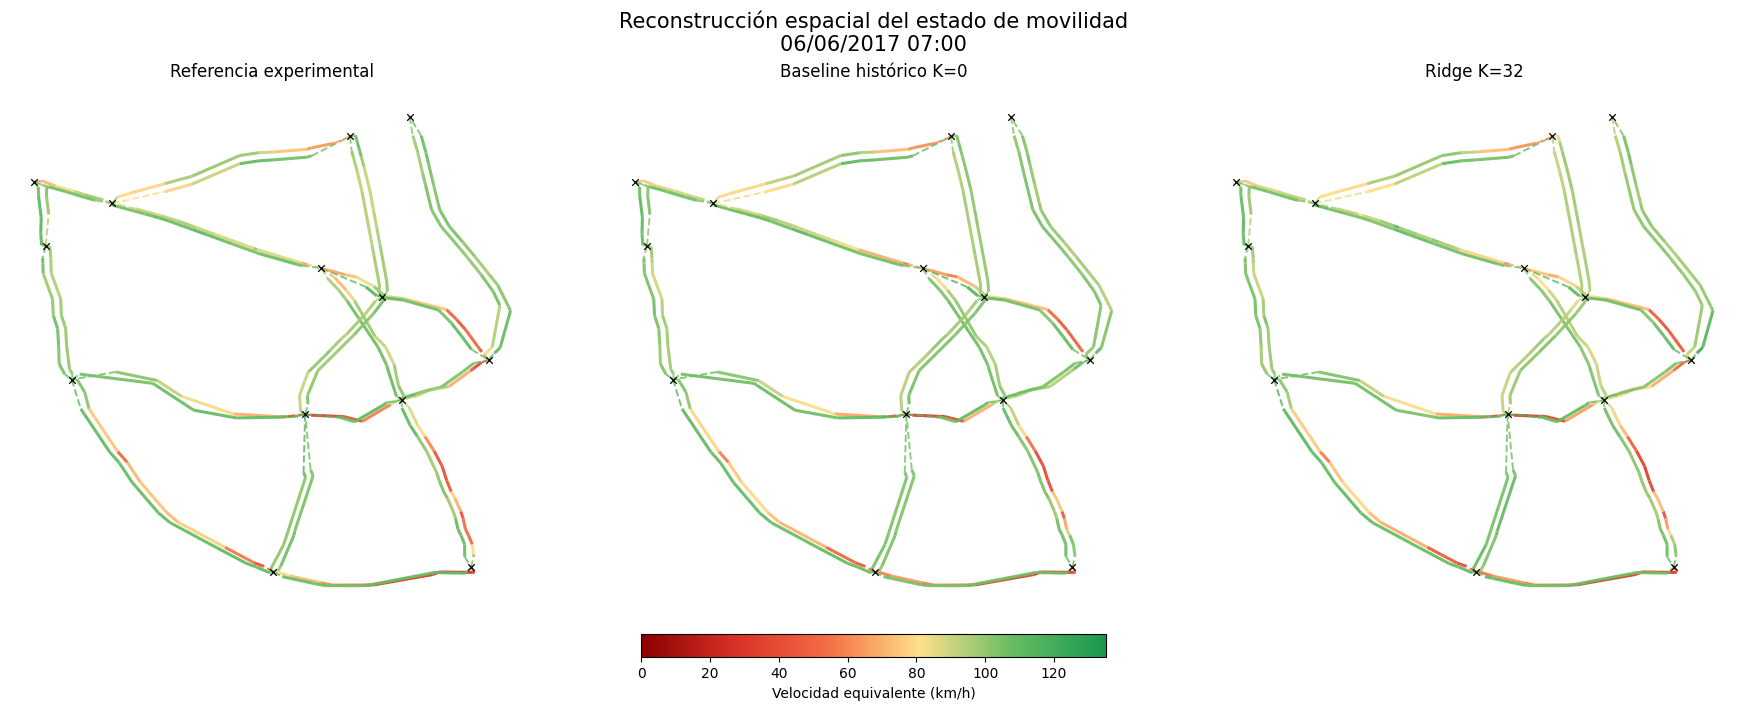


Visualización completada.
Instante utilizado: 2017-06-06 07:00:00

Figura guardada en:
/content/drive/MyDrive/Route Intelligence/avance4_reconstruccion_red_k32_ejecuciones/ejecucion_20261025_165925_885935/mapa_comparativo_trafico_k32.png

Escala de velocidad: 0 a 135 km/h
Modelo: Ridge K=32
Sin reentrenamiento.
Sin nuevas consultas ni cálculos de rutas.


In [18]:

# ------------------------------------------------------------
# 16. Comparación visual de estados de movilidad
# Referencia vs. K=0 vs. Ridge K=32
# ------------------------------------------------------------

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable

# ------------------------------------------------------------
# 1. Recuperar resultados finales guardados
# ------------------------------------------------------------

# OUTPUT_DIR corresponde a los resultados generados en la sección anterior.
# Las celdas deben ejecutarse en orden dentro de la misma sesión.
assert 'OUTPUT_DIR' in globals(), 'Ejecute primero la sección 15.'

npz_path = OUTPUT_DIR / 'predicciones_junio.npz'
manifest_path = OUTPUT_DIR / 'manifest.json'

assert npz_path.is_file()
assert manifest_path.is_file()

# El archivo contiene arrays numéricos y fechas guardadas como cadenas.

with np.load(
    npz_path,
    allow_pickle=False
) as saved:

    timestamps = pd.to_datetime(saved['timestamps'])

    actual_saved = saved['actual_edges']
    baseline_saved = saved['baseline_edges']
    ridge_saved = saved['ridge_edges']

with open(
    manifest_path,
    encoding='utf-8'
) as f:

    saved_manifest = json.load(f)

assert actual_saved.shape == (120, 345)
assert baseline_saved.shape == (120, 345)
assert ridge_saved.shape == (120, 345)

assert (
    saved_manifest['edge_columns']
    == edges['edge_id'].astype(str).tolist()
)

print('Predicciones finales recuperadas.')
print('Instantes disponibles:', len(timestamps))

# ------------------------------------------------------------
# 2. Seleccionar el instante disponible más cercano
# ------------------------------------------------------------

requested_timestamp = pd.Timestamp(
    '2017-06-06 07:00:00'
)

position = int(
    np.argmin(
        np.abs(timestamps - requested_timestamp)
    )
)

SELECTED_TIMESTAMP = timestamps[position]

print()
print('Instante solicitado:', requested_timestamp)
print('Instante disponible:', SELECTED_TIMESTAMP)

time_reference = actual_saved[position]
time_baseline = baseline_saved[position]
time_ridge = ridge_saved[position]

# ------------------------------------------------------------
# 3. Recuperar velocidades equivalentes
#
# v (km/h) = 60 * distancia (km) / tiempo (min)
# ------------------------------------------------------------

distances = edges['distance_km'].to_numpy(
    dtype=float
)

assert distances.shape == (345,)
assert np.isfinite(distances).all()
assert (distances > 0).all()


def equivalent_speeds(times):

    times = np.asarray(
        times,
        dtype=float
    )

    assert times.shape == (345,)
    assert np.isfinite(times).all()
    assert (times > 0).all()

    return 60.0 * distances / times


speeds_reference = equivalent_speeds(
    time_reference
)

speeds_baseline = equivalent_speeds(
    time_baseline
)

speeds_ridge = equivalent_speeds(
    time_ridge
)

# ------------------------------------------------------------
# 4. Coordenadas geográficas
# ------------------------------------------------------------

positions = {
    str(row['node_id']): np.array([
        float(row['longitude']),
        float(row['latitude'])
    ])
    for _, row in nodes.iterrows()
}

assert len(positions) == 322

# ------------------------------------------------------------
# 5. Separación visual de sentidos
#
# N -> derecha
# S -> izquierda
# E -> abajo
# W -> arriba
#
# El desplazamiento es exclusivamente gráfico.
# ------------------------------------------------------------

lon_span = (
    nodes['longitude'].max()
    - nodes['longitude'].min()
)

lat_span = (
    nodes['latitude'].max()
    - nodes['latitude'].min()
)

SHIFT_FRAC = 0.008

dx = SHIFT_FRAC * lon_span
dy = SHIFT_FRAC * lat_span

for _, row in nodes.loc[
    nodes['node_type'] == 'sensor'
].iterrows():

    node = str(row['node_id'])

    direction = str(
        row['corridor']
    ).split('-')[-1]

    if direction == 'N':
        positions[node][0] += dx

    elif direction == 'S':
        positions[node][0] -= dx

    elif direction == 'E':
        positions[node][1] -= dy

    elif direction == 'W':
        positions[node][1] += dy

# ------------------------------------------------------------
# 6. Construir segmentos gráficos
# ------------------------------------------------------------

segments = np.array([
    [
        positions[str(row['from'])],
        positions[str(row['to'])]
    ]
    for _, row in edges.iterrows()
])

assert segments.shape == (345, 2, 2)

corridor_mask = (
    edges['edge_type'].to_numpy()
    == 'corridor'
)

macro_mask = ~corridor_mask

macro_nodes = nodes.loc[
    nodes['node_type'] == 'interchange',
    'node_id'
].astype(str).tolist()

macro_xy = np.array([
    positions[node]
    for node in macro_nodes
])

assert len(macro_xy) == 13

# ------------------------------------------------------------
# 7. Escala de color común
#
# Misma escala utilizada en el Avance 3.
# ------------------------------------------------------------

VMIN = 0
VMAX = 135

traffic_colors = [
    '#8b0000',  # Rojo oscuro
    '#d73027',  # Rojo
    '#f46d43',  # Naranja
    '#fee08b',  # Amarillo
    '#66bd63',  # Verde claro
    '#1a9850'   # Verde
]

cmap = LinearSegmentedColormap.from_list(
    'traffic_like',
    traffic_colors,
    N=256
)

norm = Normalize(
    vmin=VMIN,
    vmax=VMAX
)

# ------------------------------------------------------------
# 8. Función para visualizar el estado de la red
# ------------------------------------------------------------

mean_latitude = float(
    nodes['latitude'].mean()
)


def draw_traffic_state(ax, speeds, title):

    # Aristas de corredores
    corridor_lines = LineCollection(
        segments[corridor_mask],
        cmap=cmap,
        norm=norm,
        linewidths=2.2,
        alpha=0.95
    )

    corridor_lines.set_array(
        speeds[corridor_mask]
    )

    ax.add_collection(corridor_lines)

    # Conexiones con macronodos
    macro_lines = LineCollection(
        segments[macro_mask],
        cmap=cmap,
        norm=norm,
        linewidths=1.4,
        linestyles='dashed',
        alpha=0.85
    )

    macro_lines.set_array(
        speeds[macro_mask]
    )

    ax.add_collection(macro_lines)

    # Macronodos
    ax.scatter(
        macro_xy[:, 0],
        macro_xy[:, 1],
        s=22,
        marker='x',
        c='black',
        linewidths=0.9,
        zorder=4
    )

    ax.autoscale()

    ax.set_aspect(
        1 / np.cos(
            np.deg2rad(mean_latitude)
        )
    )

    ax.set_title(
        title,
        fontsize=12,
        pad=12
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)


# ------------------------------------------------------------
# 9. Crear la figura comparativa
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 7),
    constrained_layout=True
)

states = [
    (
        'Referencia experimental',
        speeds_reference
    ),
    (
        'Baseline histórico K=0',
        speeds_baseline
    ),
    (
        'Ridge K=32',
        speeds_ridge
    )
]

for ax, (title, speeds) in zip(
    axes,
    states
):

    draw_traffic_state(
        ax,
        speeds,
        title
    )

# ------------------------------------------------------------
# 10. Barra de colores compartida
# ------------------------------------------------------------

sm = ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes,
    orientation='horizontal',
    fraction=0.045,
    pad=0.045,
    shrink=0.70
)

cbar.set_label(
    'Velocidad equivalente (km/h)'
)

fig.suptitle(
    'Reconstrucción espacial del estado de movilidad\n'
    f'{SELECTED_TIMESTAMP:%d/%m/%Y %H:%M}',
    fontsize=15
)

# ------------------------------------------------------------
# 11. Guardar la figura
# ------------------------------------------------------------

figure_path = (
    OUTPUT_DIR
    / 'mapa_comparativo_trafico_k32.png'
)

fig.savefig(
    figure_path,
    dpi=220,
    bbox_inches='tight'
)

plt.show()

# ------------------------------------------------------------
# 12. Resumen
# ------------------------------------------------------------

print()
print('Visualización completada.')

print('Instante utilizado:', SELECTED_TIMESTAMP)

print()
print('Figura guardada en:')
print(figure_path)

print()
print('Escala de velocidad:', VMIN, 'a', VMAX, 'km/h')
print('Modelo: Ridge K=32')
print('Sin reentrenamiento.')
print('Sin nuevas consultas ni cálculos de rutas.')


### 17. Comparación espacial de desviaciones y errores por arista

Las visualizaciones muestran, para el instante ilustrativo seleccionado, las desviaciones de los tiempos de recorrido respecto de la referencia histórica $K=0$ y las diferencias entre los errores de reconstrucción obtenidos con dicha referencia y con Ridge $K=32$.

Estas representaciones permiten examinar cómo se distribuyen espacialmente las variaciones de movilidad y las diferencias de precisión entre ambos métodos. La reconstrucción puede mejorar en algunas aristas y presentar errores mayores en otras.

Por tanto, las visualizaciones constituyen un análisis descriptivo de un instante particular y no sustituyen la evaluación cuantitativa realizada sobre los 120 instantes de junio y los cinco conjuntos de nodos.


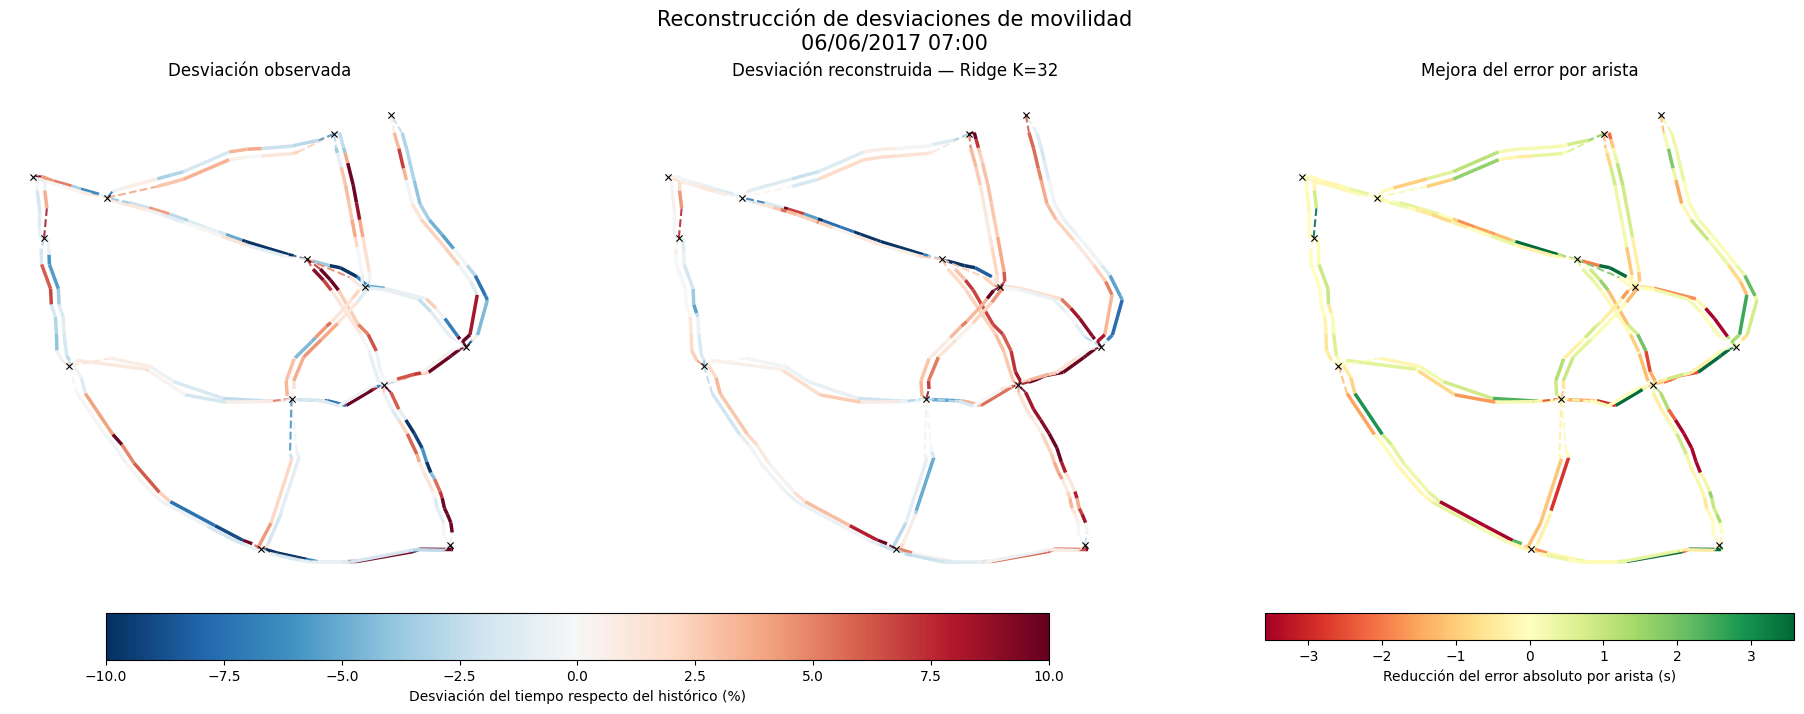


Instante: 2017-06-06 07:00:00

MAE de aristas, baseline: 1.7495 s
MAE de aristas, Ridge: 1.5640 s

Aristas con menor error: 165
Aristas con mayor error: 180
Aristas prácticamente sin cambio: 0

Figura guardada:
/content/drive/MyDrive/Route Intelligence/avance4_reconstruccion_red_k32_ejecuciones/ejecucion_20261025_165925_885935/mapa_desviaciones_ridge_k32.png

Sin reentrenamiento ni nuevas consultas.


In [19]:

# ------------------------------------------------------------
# 17. Desviaciones de movilidad y mejora espacial de Ridge
# ------------------------------------------------------------

from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection

# ------------------------------------------------------------
# 1. Desviaciones respecto del histórico (%)
# ------------------------------------------------------------

# Positivo: tiempo mayor que el histórico (más lento)
# Negativo: tiempo menor que el histórico (más rápido)

relative_reference_pct = (
    100 * (time_reference / time_baseline - 1.0)
)

relative_ridge_pct = (
    100 * (time_ridge / time_baseline - 1.0)
)

# ------------------------------------------------------------
# 2. Mejora del error absoluto por arista (segundos)
#
# Positivo: Ridge reduce el error
# Negativo: Ridge aumenta el error
# ------------------------------------------------------------

baseline_error_s = (
    60 * np.abs(time_reference - time_baseline)
)

ridge_error_s = (
    60 * np.abs(time_reference - time_ridge)
)

error_improvement_s = (
    baseline_error_s - ridge_error_s
)

assert relative_reference_pct.shape == (345,)
assert relative_ridge_pct.shape == (345,)
assert error_improvement_s.shape == (345,)

# ------------------------------------------------------------
# 3. Escalas de colores
# ------------------------------------------------------------

# Misma escala para las desviaciones observadas
# y las estimadas. Los extremos se saturan.

DEVIATION_LIMIT = 10.0

deviation_norm = TwoSlopeNorm(
    vmin=-DEVIATION_LIMIT,
    vcenter=0,
    vmax=DEVIATION_LIMIT
)

deviation_cmap = plt.get_cmap('RdBu_r')

# Escala simétrica para representar mejora y deterioro.
# El P95 sólo define la escala visual, no modifica datos.

improvement_limit = max(
    0.5,
    float(np.percentile(
        np.abs(error_improvement_s),
        95
    ))
)

improvement_norm = TwoSlopeNorm(
    vmin=-improvement_limit,
    vcenter=0,
    vmax=improvement_limit
)

improvement_cmap = plt.get_cmap('RdYlGn')

# ------------------------------------------------------------
# 4. Función de representación espacial
# ------------------------------------------------------------

def draw_spatial_values(
    ax,
    values,
    title,
    cmap,
    norm
):

    # Corredores
    corridor_lines = LineCollection(
        segments[corridor_mask],
        cmap=cmap,
        norm=norm,
        linewidths=2.5,
        alpha=0.98
    )

    corridor_lines.set_array(
        values[corridor_mask]
    )

    ax.add_collection(corridor_lines)

    # Conexiones con macronodos
    macro_lines = LineCollection(
        segments[macro_mask],
        cmap=cmap,
        norm=norm,
        linewidths=1.5,
        linestyles='dashed',
        alpha=0.85
    )

    macro_lines.set_array(
        values[macro_mask]
    )

    ax.add_collection(macro_lines)

    # Macronodos
    ax.scatter(
        macro_xy[:, 0],
        macro_xy[:, 1],
        s=20,
        marker='x',
        c='black',
        linewidths=0.8,
        zorder=4
    )

    ax.autoscale()

    ax.set_aspect(
        1 / np.cos(
            np.deg2rad(mean_latitude)
        )
    )

    ax.set_title(title, fontsize=12, pad=12)
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)


# ------------------------------------------------------------
# 5. Construir figura de tres paneles
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 7),
    constrained_layout=True
)

draw_spatial_values(
    axes[0],
    relative_reference_pct,
    'Desviación observada',
    deviation_cmap,
    deviation_norm
)

draw_spatial_values(
    axes[1],
    relative_ridge_pct,
    'Desviación reconstruida — Ridge K=32',
    deviation_cmap,
    deviation_norm
)

draw_spatial_values(
    axes[2],
    error_improvement_s,
    'Mejora del error por arista',
    improvement_cmap,
    improvement_norm
)

# ------------------------------------------------------------
# 6. Barras de colores
# ------------------------------------------------------------

deviation_sm = ScalarMappable(
    cmap=deviation_cmap,
    norm=deviation_norm
)

deviation_sm.set_array([])

cb1 = fig.colorbar(
    deviation_sm,
    ax=axes[:2],
    orientation='horizontal',
    shrink=0.75,
    pad=0.05
)

cb1.set_label(
    'Desviación del tiempo respecto del histórico (%)'
)

improvement_sm = ScalarMappable(
    cmap=improvement_cmap,
    norm=improvement_norm
)

improvement_sm.set_array([])

cb2 = fig.colorbar(
    improvement_sm,
    ax=axes[2],
    orientation='horizontal',
    shrink=0.85,
    pad=0.05
)

cb2.set_label(
    'Reducción del error absoluto por arista (s)'
)

fig.suptitle(
    'Reconstrucción de desviaciones de movilidad\n'
    f'{SELECTED_TIMESTAMP:%d/%m/%Y %H:%M}',
    fontsize=15
)

# ------------------------------------------------------------
# 7. Guardar figura
# ------------------------------------------------------------

deviation_figure_path = (
    OUTPUT_DIR
    / 'mapa_desviaciones_ridge_k32.png'
)

fig.savefig(
    deviation_figure_path,
    dpi=220,
    bbox_inches='tight'
)

plt.show()

# ------------------------------------------------------------
# 8. Diagnóstico numérico del instante visualizado
# ------------------------------------------------------------

improved_count = int(
    np.sum(error_improvement_s > 1e-8)
)

worsened_count = int(
    np.sum(error_improvement_s < -1e-8)
)

unchanged_count = (
    345 - improved_count - worsened_count
)

print()
print('Instante:', SELECTED_TIMESTAMP)

print()
print(
    'MAE de aristas, baseline:',
    f'{baseline_error_s.mean():.4f} s'
)

print(
    'MAE de aristas, Ridge:',
    f'{ridge_error_s.mean():.4f} s'
)

print()
print('Aristas con menor error:', improved_count)
print('Aristas con mayor error:', worsened_count)
print('Aristas prácticamente sin cambio:', unchanged_count)

print()
print('Figura guardada:')
print(deviation_figure_path)

print()
print('Sin reentrenamiento ni nuevas consultas.')


### Interpretación de la comparación por arista

En el instante ilustrativo del 6 de junio de 2017 a las 07:00, Ridge presenta un error absoluto menor que la referencia histórica $K=0$ en **165 de las 345 aristas** y un error mayor en las **180 restantes**. A pesar de ello, el MAE de los tiempos por arista disminuye de **1.7495 a 1.5640 segundos**, una reducción aproximada del **10.60 %**. Por tanto, la mejora promedio no implica que Ridge sea más preciso en cada arista de la red.

Esta reducción del 10.60 % **no es directamente comparable** con la reducción del **64.04 % del MAE OD** obtenida en la evaluación final. La primera corresponde a errores de tiempos por arista en un solo instante; la segunda resume errores de tiempos origen-destino calculados mediante caminos mínimos a lo largo de 120 instantes y cinco grupos de nodos. Además, los tiempos OD dependen de las aristas que integran los caminos seleccionados, de modo que una mejora global por arista no se traduce de forma proporcional en el error de las matrices OD.



### 18. Distribución espacial de las consultas guía

Se representa la distribución espacial de las 32 consultas origen–destino seleccionadas mediante el procedimiento greedy de cobertura estadística.

La primera visualización muestra los macronodos utilizados como origen y destino, así como su frecuencia de aparición en el conjunto seleccionado.

La segunda muestra cuántos de los 32 caminos mínimos atraviesan cada arista, considerando los tiempos del baseline histórico K=0 correspondientes al instante ilustrativo del 6 de junio de 2017 a las 07:00.

Los extremos de las consultas permanecen fijos, pero sus trayectorias pueden cambiar según las condiciones de movilidad. Por tanto, la cobertura mostrada corresponde a un estado histórico de referencia y no representa necesariamente todos los caminos que podrían observarse.

La frecuencia de utilización de una arista por los caminos seleccionados es un indicador topológico descriptivo. No debe confundirse con cobertura estadística, independencia de observaciones o capacidad predictiva del modelo.


Consultas recuperadas: 32

Aristas utilizadas por al menos un camino: 311
Cobertura de aristas: 90.14%
Aristas de corredor utilizadas: 247
Conexiones con macronodos utilizadas: 64
Máxima frecuencia de una arista: 3


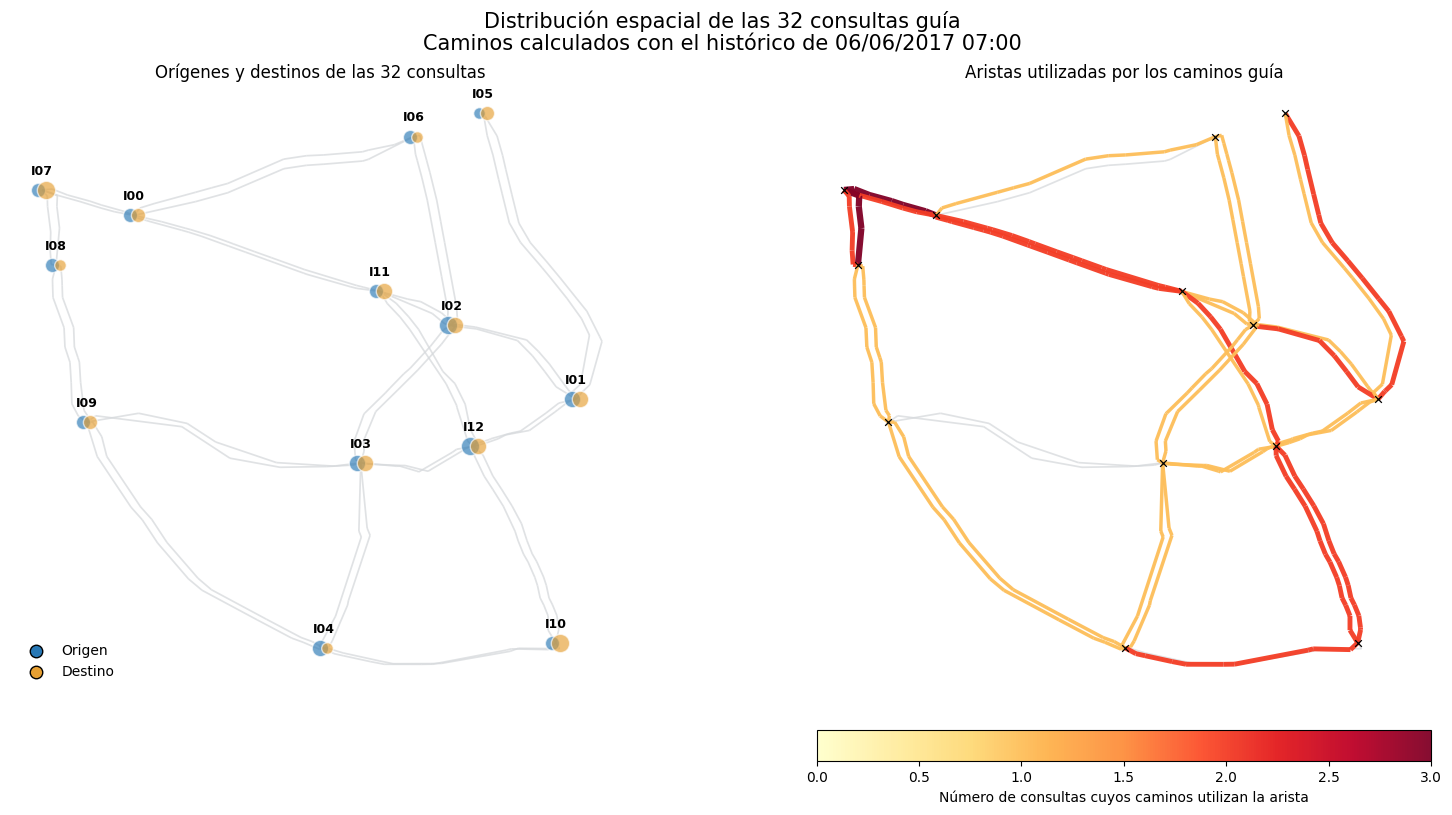


Consultas guía y recorridos históricos:


,Orden,Origen,Destino,Aristas del camino,Tiempo histórico (min)
0,1,I08,I05,53,21.358
1,2,I10,I08,51,23.315
2,3,I09,I10,21,12.102
3,4,I11,I10,23,8.544
4,5,I11,I07,20,9.627
5,6,I12,I01,8,2.424
6,7,I01,I05,17,7.364
7,8,I01,I12,9,2.662
8,9,I02,I03,13,4.039
9,10,I07,I09,16,5.166



Figura guardada:
/content/drive/MyDrive/Route Intelligence/avance4_reconstruccion_red_k32_ejecuciones/ejecucion_20261025_165925_885935/mapa_consultas_guia_k32.png

Sin cambios en el modelo ni en las métricas.
Caminos calculados con el baseline histórico.


In [20]:

# ------------------------------------------------------------
# 18. Distribución espacial de las 32 consultas guía
# ------------------------------------------------------------

from collections import Counter

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. Recuperar las 32 consultas definitivas
# ------------------------------------------------------------

with open(
    OUTPUT_DIR / 'manifest.json',
    encoding='utf-8'
) as f:
    final_manifest = json.load(f)

queries = final_manifest['consultas_guia']

assert len(queries) == 32
assert len(set(queries)) == 32

# Separar los pares origen-destino
query_pairs = [
    tuple(query.split('__'))
    for query in queries
]

assert all(len(pair) == 2 for pair in query_pairs)

origins = [pair[0] for pair in query_pairs]
destinations = [pair[1] for pair in query_pairs]

origin_counts = Counter(origins)
destination_counts = Counter(destinations)

assert all(
    node in node_to_idx
    for pair in query_pairs
    for node in pair
)

print('Consultas recuperadas:', len(query_pairs))
print()

# ------------------------------------------------------------
# 2. Grafo con tiempos del baseline histórico
# ------------------------------------------------------------

historical_weights = np.asarray(
    time_baseline,
    dtype=float
)

assert historical_weights.shape == (345,)
assert (historical_weights > 0).all()

n_nodes = len(graph_nodes)

historical_graph = csr_matrix(
    (
        historical_weights,
        (edge_from_idx, edge_to_idx)
    ),
    shape=(n_nodes, n_nodes)
)

# ------------------------------------------------------------
# 3. Calcular caminos mínimos de las 32 consultas
# ------------------------------------------------------------

unique_origins = list(dict.fromkeys(origins))

source_indices = [
    node_to_idx[node]
    for node in unique_origins
]

distances, predecessors = dijkstra(
    historical_graph,
    directed=True,
    indices=source_indices,
    return_predecessors=True
)

source_row = {
    node: i
    for i, node in enumerate(unique_origins)
}

# Índice para identificar la arista de cada conexión
edge_lookup = {
    (int(u), int(v)): i
    for i, (u, v) in enumerate(
        zip(edge_from_idx, edge_to_idx)
    )
}

assert len(edge_lookup) == 345

edge_usage = np.zeros(345, dtype=int)

path_records = []

for order, (origin, destination) in enumerate(
    query_pairs, start=1
):

    row = source_row[origin]
    start_node = node_to_idx[origin]
    end_node = node_to_idx[destination]

    assert np.isfinite(
        distances[row, end_node]
    )

    current = end_node
    path_edges = []

    # Reconstrucción inversa mediante predecesores
    while current != start_node:

        previous = int(
            predecessors[row, current]
        )

        if previous < 0:
            raise RuntimeError(
                f'Camino incompleto: {origin} -> {destination}'
            )

        edge_idx = edge_lookup[
            (previous, current)
        ]

        path_edges.append(edge_idx)
        current = previous

        if len(path_edges) > n_nodes:
            raise RuntimeError(
                'Se detectó un camino inesperadamente largo.'
            )

    # Cada arista recorrida cuenta una vez por consulta
    for edge_idx in path_edges:
        edge_usage[edge_idx] += 1

    path_records.append({
        'Orden': order,
        'Origen': origin,
        'Destino': destination,
        'Aristas del camino': len(path_edges),
        'Tiempo histórico (min)': distances[
            row, end_node
        ]
    })

path_table = pd.DataFrame(path_records)

assert len(path_table) == 32

# ------------------------------------------------------------
# 4. Resumen de cobertura de caminos
# ------------------------------------------------------------

used_mask = edge_usage > 0

coverage_pct = (
    100 * used_mask.mean()
)

corridor_used = int(
    np.sum(used_mask & corridor_mask)
)

macro_used = int(
    np.sum(used_mask & macro_mask)
)

print('Aristas utilizadas por al menos un camino:',
      int(used_mask.sum()))

print('Cobertura de aristas:',
      f'{coverage_pct:.2f}%')

print('Aristas de corredor utilizadas:', corridor_used)
print('Conexiones con macronodos utilizadas:', macro_used)

print('Máxima frecuencia de una arista:',
      int(edge_usage.max()))

# ------------------------------------------------------------
# 5. Preparar figura
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 8),
    constrained_layout=True
)

def draw_base_network(ax):

    background = LineCollection(
        segments,
        colors='#d6d9dc',
        linewidths=1.25,
        alpha=0.75
    )

    ax.add_collection(background)
    ax.autoscale()

    ax.set_aspect(
        1 / np.cos(
            np.deg2rad(mean_latitude)
        )
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)


# ------------------------------------------------------------
# 6. Panel izquierdo: extremos de consultas
# ------------------------------------------------------------

ax = axes[0]

draw_base_network(ax)

# Mostrar origen y destino desplazados ligeramente
offset = 0.007 * lon_span

for macro in macro_nodes:

    xy = positions[macro]

    n_origin = origin_counts[macro]
    n_destination = destination_counts[macro]

    if n_origin > 0:

        ax.scatter(
            xy[0] - offset,
            xy[1],
            s=35 + 35 * n_origin,
            color='#2878b5',
            alpha=0.65,
            edgecolor='white',
            zorder=5
        )

    if n_destination > 0:

        ax.scatter(
            xy[0] + offset,
            xy[1],
            s=35 + 35 * n_destination,
            color='#e69f32',
            alpha=0.65,
            edgecolor='white',
            zorder=5
        )

    ax.annotate(
        macro,
        xy,
        xytext=(0, 11),
        textcoords='offset points',
        ha='center',
        fontsize=9,
        fontweight='bold',
        zorder=6
    )

ax.set_title(
    'Orígenes y destinos de las 32 consultas',
    fontsize=12
)

legend_items = [
    Line2D(
        [0], [0],
        marker='o',
        color='none',
        markerfacecolor='#2878b5',
        markersize=9,
        label='Origen'
    ),
    Line2D(
        [0], [0],
        marker='o',
        color='none',
        markerfacecolor='#e69f32',
        markersize=9,
        label='Destino'
    )
]

ax.legend(
    handles=legend_items,
    loc='lower left',
    frameon=False
)

# ------------------------------------------------------------
# 7. Panel derecho: frecuencia de caminos
# ------------------------------------------------------------

ax = axes[1]

draw_base_network(ax)

max_usage = int(edge_usage.max())

usage_norm = Normalize(
    vmin=0,
    vmax=max(1, max_usage)
)

used_lines = LineCollection(
    segments[used_mask],
    cmap='YlOrRd',
    norm=usage_norm,
    linewidths=(
        1.5
        + 3.0
        * edge_usage[used_mask]
        / max(1, max_usage)
    ),
    alpha=0.95
)

used_lines.set_array(
    edge_usage[used_mask].astype(float)
)

ax.add_collection(used_lines)

# Macronodos de referencia
ax.scatter(
    macro_xy[:, 0],
    macro_xy[:, 1],
    marker='x',
    color='black',
    s=23,
    linewidths=0.9,
    zorder=6
)

ax.set_title(
    'Aristas utilizadas por los caminos guía',
    fontsize=12
)

cb = fig.colorbar(
    used_lines,
    ax=ax,
    orientation='horizontal',
    shrink=0.78,
    pad=0.055
)

cb.set_label(
    'Número de consultas cuyos caminos utilizan la arista'
)

fig.suptitle(
    'Distribución espacial de las 32 consultas guía\n'
    f'Caminos calculados con el histórico de '
    f'{SELECTED_TIMESTAMP:%d/%m/%Y %H:%M}',
    fontsize=15
)

# ------------------------------------------------------------
# 8. Guardar figura
# ------------------------------------------------------------

guide_map_path = (
    OUTPUT_DIR
    / 'mapa_consultas_guia_k32.png'
)

fig.savefig(
    guide_map_path,
    dpi=220,
    bbox_inches='tight'
)

plt.show()

# ------------------------------------------------------------
# 9. Resumen de las consultas
# ------------------------------------------------------------

print()
print('Consultas guía y recorridos históricos:')
display(path_table.round(3))

print()
print('Figura guardada:')
print(guide_map_path)

print()
print('Sin cambios en el modelo ni en las métricas.')
print('Caminos calculados con el baseline histórico.')


### Observación sobre la distribución de consultas

En el instante ilustrativo considerado, los caminos mínimos asociados a las 32 consultas guía atraviesan al menos una vez **311 de las 345 aristas de la red (90.14 %)**. Esto muestra una distribución topológica amplia de los recorridos seleccionados bajo las condiciones históricas utilizadas.

Sin embargo, esta proporción no representa una medida directa de la capacidad predictiva de las consultas ni garantiza que las aristas no recorridas carezcan de información útil. La selección de las consultas se fundamentó en asociaciones estadísticas históricas, mientras que la cobertura presentada corresponde únicamente a los caminos mínimos de un instante de referencia.

### 19. Conclusiones y trabajo posterior

En este avance se desarrolló y evaluó un procedimiento para reconstruir los tiempos de recorrido de una red vial experimental a partir de un conjunto reducido de consultas origen-destino (OD) contemporáneas simuladas.

Se compararon seis modelos individuales de aprendizaje automático: Ridge, KNN, MLP, PPCA, PLS y árbol de decisión. Los algoritmos se evaluaron bajo un protocolo común, utilizando las mismas 32 consultas guía y midiendo su desempeño mediante los errores de las matrices OD obtenidas después de reconstruir los tiempos de las aristas.

La comparación inicial identificó a Ridge y KNN como los modelos con menor MAE OD. Después de explorar diferentes configuraciones de hiperparámetros, se seleccionó **Ridge multisalida con regularización $\alpha=1000$ y $K=32$ consultas guía**, considerando su precisión, desempeño en métricas complementarias y bajo costo computacional de inferencia.

En la evaluación final sobre junio de 2017, periodo reservado durante las etapas anteriores, el modelo seleccionado obtuvo un MAE OD de **11.4161 segundos**, frente a **31.7485 segundos** de la referencia histórica $K=0$. Esto representa una reducción relativa del **64.04 %**. Las mejoras se observaron en los cinco conjuntos de nodos evaluados.

Estos resultados respaldan la viabilidad experimental de utilizar observaciones contemporáneas parciales para actualizar los tiempos de una red y reconstruir matrices OD para diferentes conjuntos de ubicaciones. Sin embargo, las consultas guía fueron simuladas a partir de PEMS-BAY y no se utilizaron mediciones independientes de proveedores externos. Tampoco se evaluaron directamente los efectos de las matrices estimadas sobre la factibilidad, los costos o los tiempos de recuperación de rutas de reparto.

Como trabajo posterior se plantea evaluar el procedimiento con consultas externas, examinar su desempeño ante distintos escenarios de interrupción e integrar las matrices reconstruidas con algoritmos de planeación y replaneación de rutas con ventanas de tiempo.

En consecuencia, este avance proporciona una base experimental para el componente de estimación de tiempos de desplazamiento del Proyecto Integrador, sin constituir todavía una validación operativa del sistema completo.

#### 19.1. Consideraciones metodológicas y líneas de trabajo posteriores

A partir de los resultados obtenidos, se identifican aspectos que deberán profundizarse en las siguientes etapas del Proyecto Integrador.

**Selección del número de consultas guía.** En la evaluación exploratoria de abril, K=64 obtuvo menor MAE OD que K=32 en ambos conjuntos de nodos. En este avance se adoptó K=32 como configuración experimental intermedia, al obtener reducciones importantes del MAE OD frente a K=0 utilizando la mitad de las consultas. No obstante, esta elección no establece un número óptimo. Posteriormente será necesario evaluar el beneficio adicional de incrementar K frente al costo, disponibilidad y latencia de las observaciones actuales.

**Evaluación de errores individuales.** Aunque Ridge mejora considerablemente el MAE global de las matrices OD, esto no garantiza que todas las estimaciones individuales sean más precisas. Se propone analizar la proporción de pares OD que mejoran o empeoran, así como la frecuencia y magnitud de las subestimaciones, especialmente por sus posibles consecuencias sobre el cumplimiento de ventanas de tiempo.

**Desempeño ante condiciones extraordinarias.** La evaluación actual demuestra mejoras bajo las condiciones experimentales de PEMS-BAY, pero todavía no caracteriza específicamente el desempeño ante interrupciones, congestión atípica o cambios abruptos de movilidad. Estos escenarios serán relevantes para evaluar la capacidad del sistema de apoyar decisiones de replaneación.

**Cobertura de las consultas guía.** La cobertura espacial observada proporciona evidencia preliminar sobre la distribución de las consultas seleccionadas. Como extensión, se plantea analizar su estabilidad en diferentes instantes y la relación entre las zonas menos cubiertas y los errores de reconstrucción.

**Integración con la optimización de rutas.** Finalmente, será necesario incorporar las matrices estimadas al algoritmo de planeación y replaneación, para determinar si las mejoras en precisión se traducen en mejores decisiones operativas, considerando factibilidad de las rutas, cumplimiento de ventanas de tiempo, costos y tiempos de recuperación.

Estas líneas de trabajo se plantean como extensiones del alcance experimental actual. Su desarrollo se priorizará en las siguientes entregas, de acuerdo con su contribución al objetivo general del proyecto.